# Apostila: do Processamento de Linguagem Natural Clássico aos *Transformers* (*"Attention Is All You Need"*)

**Instituição:** Instituto Federal de Educação, Ciência e Tecnologia de São Paulo (IFSP)  
**Curso:** Tecnologia em Análise e Desenvolvimento de Sistemas (ADS)  
**Disciplina:** Inteligência Artificial  
**Docente:** Prof. Caio  

---

## Introdução

Neste caderno interativo — estruturado como uma **apostila acadêmica completa e executável** — faremos uma jornada teórica, matemática e experimental pela evolução do **Processamento de Linguagem Natural (PLN / *NLP*)**. Nosso objetivo é duplo:
1. Compreender **porque** cada técnica histórica surgiu, qual problema real ela resolveu e qual limitação visível motivou o passo seguinte (do *Bag of Words* e *N-Gramas* às redes recorrentes *LSTM* e, finalmente, à arquitetura *Transformer*);
2. Desmistificar cada equação matemática traduzindo-a imediatamente em **exemplos numéricos inspecionáveis**, **tabelas formatadas**, **gráficos comparativos`** e **diagramas originais dos artigos científicos seminais**, todos referenciados**.

---

## Sumário

1. **Histórico do Processamento de Linguagem Natural (PLN)**
   - **1.1** Conceito, Motivação e Histórico de Usos Clássicos (Análise de *SPAM*, Sentimento em *Feedbacks*, Questões Abertas em Questionários, Tradução, Suporte à Escrita e Texto-para-Fala)
   - **1.2** Abordagens Estatísticas Clássicas:
     - **1.2.1** Saco de Palavras (*Bag of Words* — BoW) e Ponderação *TF-IDF*: Funcionamento e Exemplo Real
     - **1.2.2** Modelos Probabilísticos de *N-Gramas* (*N-Grams*): Funcionamento e Exemplo Real em Literatura
   - **1.3** Abordagens com *Deep Learning*: Redes Recorrentes e *LSTM* (*Long Short-Term Memory*)
     - **1.3.1** Motivação e Racionalidade: O Desaparecimento do Gradiente (*Vanishing Gradient*)
     - **1.3.2** Funcionamento Detalhado das Portas (*Forget*, *Input*, *Output*) e da "Esteira de Memória" ($C_t$)
     - **1.3.3** Exemplo Prático Executável: Dinâmica Temporal das Portas da *LSTM* vs. *RNN* Simples
   - **1.4** Abordagem Moderna: A Transição para os *Transformers*
2. ***Transformers*: *"Attention Is All You Need"***
   - **2.1** Motivação e Racionalidade Arquitetural (Superando o Gargalo Sequencial)
   - **2.2** Funcionamento Detalhado Passo a Passo:
     - **2.2.1** Tokenização (*Tokenization* e Subpalavras via *Byte-Pair Encoding — BPE*)
     - **2.2.2** *Embeddings*: A Matriz Global do Vocabulário ($W_{\text{embed}}$) e a Geometria do Significado
     - **2.2.3** Codificação de Posição: Da Codificação Senoidal Aditiva (VASWANI et al., 2017) à Rotação *RoPE* (SU et al., 2024)
     - **2.2.4** Mecanismo Atencional de Cabeça Única (*Single-Head Scaled Dot-Product Attention*)
     - **2.2.5** Atenção de Múltiplas Cabeças (*Multi-Head Attention*): Divisão de Tarefas, Focos Simultâneos e Integração via $W_O$
     - **2.2.6** Camadas Densas (*MLP* / *Feed-Forward Networks*): Processamento Paralelo por *Token* e Memória Factual Associativa (*Interpretabilidade Mecanicista*)
   - **2.3** Resumo Geral: Análise Holística do Funcionamento Fim a Fim (*Residual Stream* e *Logit Lens*)
   - **2.4** Considerações Adicionais e Otimizações das *LLMs* Modernas:
     - **2.4.1** Como o *Transformer* Unifica Conceitos de Arquiteturas Anteriores: Redes Residuais (*ResNets*), Convolucionais (*CNNs*) e Recorrentes (*RNNs*)
     - **2.4.2** As *LLMs* Modernas Não Olham para Trás: Máscara Causal e a Grande Otimização do *KV Cache*
3. **Referências Bibliográficas e Sugestão de Vídeos e Leituras Complementares**

## 🛠️ 0. Configuração do Ambiente e Utilitários Visuais da Apostila

Antes de iniciarmos o percurso histórico, vamos carregar as bibliotecas padrão (`numpy`, `torch`, `matplotlib`, `seaborn`) e definir nossa função auxiliar `exibir_tabela_apostila`, que renderiza tabelas estilizadas em HTML diretamente no caderno e também imprime versões alinhadas em texto puro no console.

In [ ]:
import os
import re
import math
import time
from collections import Counter, defaultdict

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display, HTML

# Semente global para reprodutibilidade científica dos experimentos
SEMENTE = 42
np.random.seed(SEMENTE)
torch.manual_seed(SEMENTE)
np.set_printoptions(precision=4, suppress=True)

DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Estilo gráfico padronizado para alta legibilidade didática em pt-BR
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#F8FAFC",
    "axes.edgecolor": "#CBD5E1",
    "axes.linewidth": 1.1,
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "axes.labelweight": "bold",
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.fontsize": 9.5,
    "font.sans-serif": ["DejaVu Sans", "Arial", "Liberation Sans"],
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "savefig.facecolor": "white",
})

def desenhar_mapa_calor(matriz, rotulos_x, rotulos_y, eixo=None, cmap="Blues", formato=".2f",
                        rotulo_barra=None, anotar_texto=None, tamanho_fonte=9):
    '''Renderiza um mapa de calor (heatmap) didático usando apenas matplotlib.'''
    if eixo is None:
        eixo = plt.gca()
    mat_np = np.asarray(matriz, dtype=np.float64)
    im = eixo.imshow(mat_np, cmap=cmap, aspect="auto")
    if rotulo_barra:
        plt.colorbar(im, ax=eixo, label=rotulo_barra, fraction=0.046, pad=0.04)
    eixo.set_xticks(np.arange(len(rotulos_x)))
    eixo.set_yticks(np.arange(len(rotulos_y)))
    eixo.set_xticklabels(rotulos_x)
    eixo.set_yticklabels(rotulos_y)
    limiar_cor = (mat_np.max() + mat_np.min()) / 2.0 if mat_np.size > 0 else 0.5
    for i in range(mat_np.shape[0]):
        for j in range(mat_np.shape[1]):
            txt = anotar_texto[i][j] if anotar_texto is not None else format(mat_np[i, j], formato)
            cor_txt = "white" if mat_np[i, j] > limiar_cor else "#0F172A"
            eixo.text(j, i, txt, ha="center", va="center", color=cor_txt, fontsize=tamanho_fonte, fontweight="bold")
    eixo.grid(False)
    return im

def exibir_tabela_apostila(colunas, linhas, titulo_tabela, subtitulo="", cores_linhas=None):
    '''Renderiza uma tabela didática em HTML estilizado e no console.'''
    larguras = [max(len(str(col)), max(len(str(l[i])) for l in linhas)) for i, col in enumerate(colunas)]
    separador = "+-" + "-+-".join("-" * w for w in larguras) + "-+"
    cabecalho_txt = "| " + " | ".join(str(col).center(larguras[i]) for i, col in enumerate(colunas)) + " |"
    print(f"\n{titulo_tabela}")
    if subtitulo:
        print(f"  {subtitulo}")
    print(separador)
    print(cabecalho_txt)
    print(separador)
    for l in linhas:
        print("| " + " | ".join(str(l[i]).center(larguras[i]) for i in range(len(colunas))) + " |")
    print(separador)

    ths = "".join(
        f'<th style="background:#1E293B; color:#FFFFFF; padding:8px 14px; border:1px solid #334155; text-align:center;">{c}</th>'
        for c in colunas
    )
    trs = ""
    for idx_l, l in enumerate(linhas):
        cor_fundo = cores_linhas[idx_l] if cores_linhas else ("#FFFFFF" if idx_l % 2 == 0 else "#F8FAFC")
        tds = "".join(
            f'<td style="padding:7px 14px; border:1px solid #CBD5E1; text-align:center; color:#0F172A; font-weight:{"700" if idx_c == 0 else "500"};">{v}</td>'
            for idx_c, v in enumerate(l)
        )
        trs += f'<tr style="background:{cor_fundo};">{tds}</tr>'

    bloco_html = f'''
    <div style="font-family:'Segoe UI', Roboto, Arial, sans-serif; margin:10px 0; padding:12px 16px;
                background:#FFFFFF; border:2px solid #CBD5E1; border-radius:10px; display:inline-block;">
        <div style="font-size:15px; font-weight:700; color:#0F172A; margin-bottom:3px;">{titulo_tabela}</div>
        <div style="font-size:12px; color:#475569; margin-bottom:8px;">{subtitulo}</div>
        <table style="border-collapse:collapse; font-size:13px;">
            <thead><tr>{ths}</tr></thead>
            <tbody>{trs}</tbody>
        </table>
    </div>
    '''
    display(HTML(bloco_html))

print(f"Ambiente inicializado com sucesso! Dispositivo PyTorch ativo: {DISPOSITIVO}")

---

# 1. Histórico do Processamento de Linguagem Natural (PLN)

## 1.1 Conceito, Motivação e Histórico de Usos Clássicos

O **Processamento de Linguagem Natural (PLN)** — em inglês, *Natural Language Processing (NLP)* — é a subárea interdisciplinar da Ciência da Computação, da Inteligência Artificial e da Linguística Computacional dedicada a dotar sistemas computacionais da capacidade de **compreender, interpretar, manipular e gerar linguagem humana** na forma escrita ou falada (JURAFSKY; MARTIN, 2024; MANNING; SCHÜTZE, 1999).

Desde o célebre artigo seminal de Alan Turing, *"Computing Machinery and Intelligence"* (TURING, 1950), no qual o "Jogo da Imitação" colocou a conversação em linguagem natural como o critério operacional da inteligência de uma máquina, a comunicação humana tem sido um dos problemas mais desafiadores da computação. Ao contrário de linguagens de programação formais (como Python, C ou SQL), onde a sintaxe é estrita e cada instrução possui semântica unívoca, a linguagem humana é intrinsecamente:
- **Ambígua (*Polissemia e Homonímia*)**: A palavra *"banco"* pode significar uma instituição financeira, um assento de madeira ou um banco de dados relacional, dependendo inteiramente do contexto ao redor;
- **Composicional e Dependente de Ordem**: As frases *"O cliente não elogiou o suporte, reclamou do atraso"* e *"O cliente não reclamou do atraso, elogiou o suporte"* possuem exatamente as mesmas palavras, mas expressam fatos diametralmente opostos;
- **Dependente de Longo Alcance**: Um pronome como *"ele"* ou *"aquilo"* no final de um parágrafo pode referir-se a um sujeito mencionado dezenas de palavras atrás.



### Motivação Prática e Histórico de Usos Clássicos na Indústria

Por que empresas, hospitais, universidades e governos investiram décadas de pesquisa em PLN? Porque **a maior parte do conhecimento humano é produzida em formato não estruturado (texto livre)**. Historicamente, antes mesmo dos atuais Grandes Modelos de Linguagem (*LLMs*), o PLN consolidou-se para resolver seis dores reais do cotidiano de sistemas de informação:

1. **Análise e Filtragem Automática de *SPAM***:
   - Nos anos 1990, com a popularização do correio eletrônico, caixas de entrada passaram a ser inundadas por mensagens comerciais fraudulentas. Trabalhos pioneiros como o de Sahami et al. (1998) demonstraram que classificadores probabilísticos bayesianos (*Naive Bayes*) baseados na frequência de termos suspeitos (*"grátis"*, *"prêmio"*, *"urgente"*, *"clique"*) podiam bloquear mais de 95% do *SPAM* automaticamente.
2. **Análise de Sentimento e Reações em *Feedbacks* de Usuários**:
   - Com o surgimento do comércio eletrônico e das redes sociais nos anos 2000, tornou-se humanamente impossível ler milhões de avaliações de produtos ou chamados de suporte. Segundo Pang e Lee (2008), a mineração de opinião (*Opinion Mining*) permitiu classificar automaticamente a polaridade emocional (positiva, neutra, negativa ou frustrada) de *feedbacks* de clientes em tempo real.
3. **Análise de Questões Abertas em Questionários para Interpretação de Dados**:
   - Em pesquisas acadêmicas, avaliações institucionais (como a CPA no ensino superior) ou pesquisas de satisfação (*NPS*), questões de múltipla escolha dizem *quanto* o usuário gostou, mas apenas **questões abertas** explicam o *porquê*. Técnicas de PLN permitem agrupar respostas discursivas em categorias temáticas (ex.: *"infraestrutura"*, *"atendimento"*, *"prazo de entrega"*, *"preço"*), transformando texto livre em indicadores quantitativos para tomada de decisão (MANNING; SCHÜTZE, 1999).
4. **Tradução Automática (*Machine Translation*)**:
   - Da tentativa inicial baseada em dicionários durante a Guerra Fria (Experimento Georgetown-IBM de 1954) aos modelos estatísticos por frases da década de 1990 (BROWN et al., 1993) e, posteriormente, à tradução neural fim a fim (BAHDANAU; CHO; BENGIO, 2015), a quebra de barreiras linguísticas sempre foi o principal motor científico do PLN.
5. **Predição de Palavras para Suporte à Escrita (*Autocompletar* e Teclados Preditivos)**:
   - Inspirados na teoria matemática da comunicação de Claude Shannon (SHANNON, 1948), sistemas de predição da próxima palavra ($P(w_t \mid w_1, \dots, w_{t-1})$) nasceram para acelerar a digitação em dispositivos móveis, auxiliar pessoas com limitações motoras (tecnologia assistiva) e sugerir conclusões de frases em editores de texto e e-mail.

```
+---------------------------------------------------------------------------------------------------+
|                        LINHA DO TEMPO EVOLUTIVA DO PLN (1950 -> PRESENTE)                         |
+---------------------------------------------------------------------------------------------------+
|  [Anos 1950-1980]           [Anos 1990-2000]           [Anos 2013-2016]        [2017 -> Hoje]     |
|  Regras Simbólicas    ──>   Estatística Clássica  ──>  Deep Learning Seq. ──>  Era Transformer    |
|  (Gramáticas manuais,       (Bag of Words, TF-IDF,     (Word2Vec, RNNs,        (Self-Attention,   |
|   sistemas especialistas)    N-Gramas, Naive Bayes)     LSTMs, GRUs)            RoPE, GPT, LLMs)  |
+---------------------------------------------------------------------------------------------------+
```

> 📺 **Recursos Multimídia e Leituras Recomendadas sobre a Evolução do PLN**:
> - **Livro-Texto de Referência (Acesso Aberto)**: JURAFSKY, Dan; MARTIN, James H. *Speech and Language Processing* (3rd ed. draft, Stanford University): <https://web.stanford.edu/~jurafsky/slp3/>
> - **Vídeo Introdutório (Stanford CS224N)**: *Lecture 1 — Introduction and Word Vectors (Prof. Christopher Manning)*: <https://www.youtube.com/watch?v=rmVRLeJRkl4>

---

## 1.2 Abordagens Estatísticas Clássicas

### 1.2.1 Saco de Palavras (*Bag of Words* — BoW): Conceito, Matemática e Exemplo de Aplicação

Como um computador — que só opera sobre números e matrizes — pode representar uma mensagem de e-mail ou uma resposta aberta de questionário? A resposta mais intuitiva da estatística clássica, fundamentada na hipótese distribucional de Harris (1954) e formalizada na recuperação de informação por Salton e Buckley (1988), é o modelo **Saco de Palavras (*Bag of Words* — BoW)**.

A ideia central consiste em **descartar completamente a estrutura gramatical e a ordem das palavras**, tratando cada documento $d$ como um "saco" onde importa apenas **quantas vezes cada palavra do vocabulário aparece**.

Dado um vocabulário ordenado $\mathcal{V} = \{v_1, v_2, \dots, v_{|\mathcal{V}|}\}$ contendo todas as palavras únicas conhecidas pelo sistema, um documento $d_i$ é convertido em um vetor numérico $\vec{x}_i \in \mathbb{R}^{|\mathcal{V}|}$ cuja $j$-ésima posição registra a frequência bruta do termo ($\text{TF}$ — *Term Frequency*):

$$x_{i, j} = \text{contagem}(v_j \in d_i)$$

Para evitar que palavras muito comuns da língua portuguesa (como *"de"*, *"que"*, *"o"*, chamadas de *stopwords*) dominem a contagem sobre palavras raras e informativas (como *"reembolso"*, *"loteria"*, *"defeito"*), aplica-se frequentemente a ponderação **TF-IDF** (*Term Frequency – Inverse Document Frequency*) proposta por Salton e Buckley (1988):

$$\text{TF-IDF}(v_j, d_i) = \text{TF}(v_j, d_i) \times \ln\left(\frac{N}{\text{DF}(v_j)}\right)$$

Onde:
- $\text{TF}(v_j, d_i)$ é a frequência da palavra $v_j$ no documento $d_i$;
- $N$ é o número total de documentos na base;
- $\text{DF}(v_j)$ (*Document Frequency*) é o número de documentos que contêm a palavra $v_j$.

Um classificador linear clássico (ou um modelo log-linear como o *Naive Bayes* de SAHAMI et al., 1998) atribui um peso $w_j$ para cada palavra do vocabulário e calcula a pontuação (*escore*) de um documento como o produto escalar:

$$\text{Escore}(d_i) = \sum_{j=1}^{|\mathcal{V}|} w_j \cdot x_{i, j} + b$$

> **Uma dúvida clássica dos alunos**:
> *"Professor, se o Bag of Words ignora a ordem das palavras, o que acontece quando uma palavra de negação como 'não' muda de lugar na frase?"*
> Vamos implementar um classificador real de **Detecção de SPAM e Análise de Feedbacks/Questionários** agora mesmo e observar exatamente onde o *Bag of Words* brilha — e onde ele falha miseravelmente!


Tabela 1.1 — Matriz Saco de Palavras (Bag of Words) em Triagem de E-mails e Feedbacks
  Repare nas duas últimas linhas (D5 e D6): sentidos opostos produzem exatamente o mesmo vetor de contagens!
+--------------------+---------------------+----------+----------+-----------+----------+----------+------------+-----------+-----------+-------+
|     Documento      |    Categoria Real   | "premio" | "gratis" | "urgente" | "clique" | "atraso" | "reclamou" | "elogiou" | "suporte" | "nao" |
+--------------------+---------------------+----------+----------+-----------+----------+----------+------------+-----------+-----------+-------+
|    D1 (E-mail)     |    SPAM / Fraude    |    2     |    1     |     1     |    1     |    0     |     0      |     0     |     0     |   0   |
|    D2 (E-mail)     |    SPAM / Fraude    |    1     |    1     |     1     |    1     |    0     |     0      |     0     |     0     |   0   |
|   D3 (Feedback)    |  Reclamação Técnica |    0     |    0     |     0  

Documento,Categoria Real,"""premio""","""gratis""","""urgente""","""clique""","""atraso""","""reclamou""","""elogiou""","""suporte""","""nao"""
D1 (E-mail),SPAM / Fraude,2,1,1,1,0,0,0,0,0
D2 (E-mail),SPAM / Fraude,1,1,1,1,0,0,0,0,0
D3 (Feedback),Reclamação Técnica,0,0,0,0,1,0,0,0,0
D4 (Quest. Aberto),Elogio / Satisfação,0,0,0,0,0,0,0,1,0
D5 (Feedback A),Negativo Real,0,0,0,0,1,1,1,1,1
D6 (Feedback B),Positivo Real,0,0,0,0,1,1,1,1,1


🔍 Distância Euclidiana entre os vetores BoW de D5 (Negativo) e D6 (Positivo): 0.0000


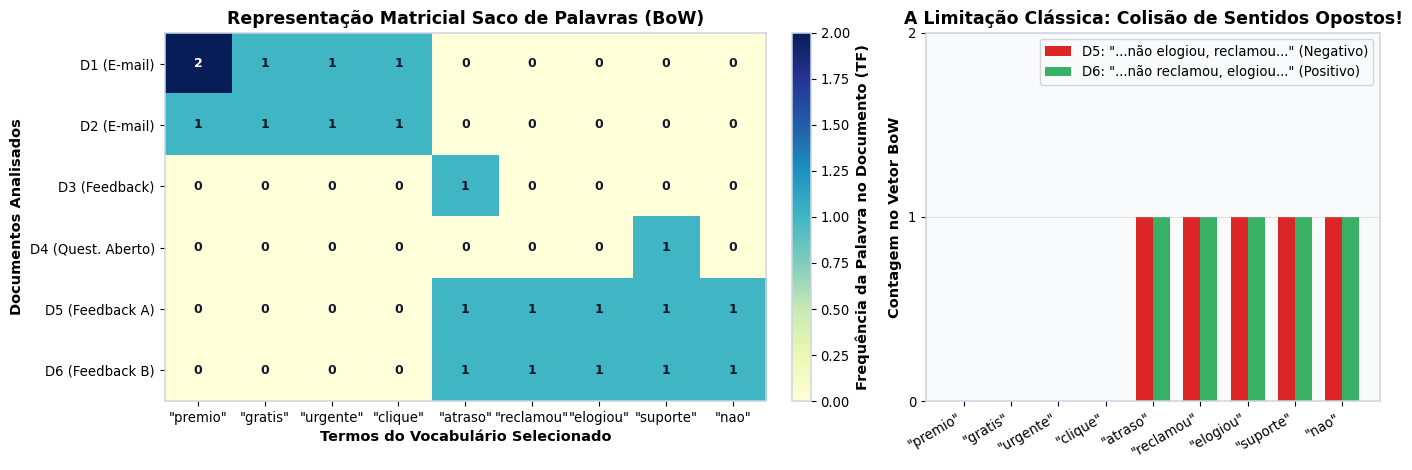

In [2]:
# ==============================================================================
# EXPERIMENTO 1.2.1: BAG OF WORDS EM TRIAGEM DE SPAM E FEEDBACKS DE USUÁRIOS
# ==============================================================================

documentos_reais = [
    ("D1 (E-mail)", "GANHE premio gratis agora clique no link urgente premio", "SPAM / Fraude"),
    ("D2 (E-mail)", "Urgente voce ganhou um premio gratis clique agora", "SPAM / Fraude"),
    ("D3 (Feedback)", "O sistema apresentou erro grave e atraso no relatorio", "Reclamação Técnica"),
    ("D4 (Quest. Aberto)", "Excelente suporte rapido o sistema resolveu meu relatorio", "Elogio / Satisfação"),
    # Par de contraste sintático: exatamente as mesmas palavras em ordens opostas!
    ("D5 (Feedback A)", "O cliente nao elogiou o suporte reclamou do atraso", "Negativo Real"),
    ("D6 (Feedback B)", "O cliente nao reclamou do atraso elogiou o suporte", "Positivo Real"),
]

# 1. Tokenização simples por palavras (minúsculas) e construção do vocabulário
stopwords_pt = {"o", "um", "no", "do", "e", "meu"}
vocab_palavras = sorted(list({
    palavra for _, texto, _ in documentos_reais
    for palavra in texto.lower().split()
    if palavra not in stopwords_pt
}))

# 2. Construção da Matriz Termo-Documento (Bag of Words) "no braço"
matriz_bow = np.zeros((len(documentos_reais), len(vocab_palavras)), dtype=int)
for idx_doc, (_, texto, _) in enumerate(documentos_reais):
    contagem = Counter(w for w in texto.lower().split() if w not in stopwords_pt)
    for idx_pal, pal in enumerate(vocab_palavras):
        matriz_bow[idx_doc, idx_pal] = contagem[pal]

# Exibir Tabela HTML com vocabulário selecionado de maior destaque didático
palavras_foco = ["premio", "gratis", "urgente", "clique", "atraso", "reclamou", "elogiou", "suporte", "nao"]
indices_foco = [vocab_palavras.index(p) for p in palavras_foco]

colunas_bow = ["Documento", "Categoria Real"] + [f'"{p}"' for p in palavras_foco]
linhas_bow = []
cores_bow = []
for idx_doc, (id_doc, _, cat) in enumerate(documentos_reais):
    valores = [str(matriz_bow[idx_doc, idx_p]) for idx_p in indices_foco]
    linhas_bow.append([id_doc, cat] + valores)
    cores_bow.append("#FEF2F2" if idx_doc in (4, 5) else ("#FFFFFF" if idx_doc % 2 == 0 else "#F8FAFC"))

exibir_tabela_apostila(
    colunas_bow,
    linhas_bow,
    titulo_tabela="Tabela 1.1 — Matriz Saco de Palavras (Bag of Words) em Triagem de E-mails e Feedbacks",
    subtitulo="Repare nas duas últimas linhas (D5 e D6): sentidos opostos produzem exatamente o mesmo vetor de contagens!",
    cores_linhas=cores_bow
)

# 3. Verificação algébrica da cegueira posicional entre D5 e D6
distancia_d5_d6 = float(np.linalg.norm(matriz_bow[4] - matriz_bow[5]))
print(f"🔍 Distância Euclidiana entre os vetores BoW de D5 (Negativo) e D6 (Positivo): {distancia_d5_d6:.4f}")

# 4. Visualização Gráfica: Mapa de Calor da Matriz BoW + Comparação dos Vetores D5 vs D6
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.45, 1.0]})

desenhar_mapa_calor(
    matriz_bow[:, indices_foco],
    rotulos_x=[f'"{p}"' for p in palavras_foco],
    rotulos_y=[d[0] for d in documentos_reais],
    eixo=eixos[0],
    cmap="YlGnBu",
    formato=".0f",
    rotulo_barra="Frequência da Palavra no Documento (TF)",
)
eixos[0].set_title("Representação Matricial Saco de Palavras (BoW)")
eixos[0].set_xlabel("Termos do Vocabulário Selecionado")
eixos[0].set_ylabel("Documentos Analisados")

# Gráfico de barras comparando os vetores de D5 e D6
posicoes_barras = np.arange(len(palavras_foco))
largura_b = 0.36
eixos[1].bar(posicoes_barras - largura_b/2, matriz_bow[4, indices_foco], width=largura_b,
             color="#DC2626", label='D5: "...não elogiou, reclamou..." (Negativo)')
eixos[1].bar(posicoes_barras + largura_b/2, matriz_bow[5, indices_foco], width=largura_b,
             color="#16A34A", alpha=0.85, label='D6: "...não reclamou, elogiou..." (Positivo)')
eixos[1].set_xticks(posicoes_barras)
eixos[1].set_xticklabels([f'"{p}"' for p in palavras_foco], rotation=30, ha="right")
eixos[1].set_yticks([0, 1, 2])
eixos[1].set_ylabel("Contagem no Vetor BoW")
eixos[1].set_title("A Limitação Clássica: Colisão de Sentidos Opostos!")
eixos[1].legend(loc="upper right")
eixos[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

---

### 1.2.2 Modelos de *N-Gramas* (*N-Grams*): Funcionamento e Exemplo de Aplicação

Vimos que o *Bag of Words* é completamente cego à ordem das palavras: para ele, *"não elogiou"* e *"elogiou"* em outra parte da frase não se distinguem de *"não reclamou"*. Como os pesquisadores dos anos 1980 e 1990 resolveram parcialmente essa perda de ordem local, além de viabilizarem a **predição da próxima palavra para suporte à escrita** e o reconhecimento de fala?

A solução foi recorrer aos **Modelos Probabilísticos de *N-Gramas*** (SHANNON, 1948; BROWN et al., 1992; JURAFSKY; MARTIN, 2024).

#### 📐 Formulação Matemática: Da Regra da Cadeia à Hipótese de Markov

Dada uma sequência de palavras $w_1, w_2, \dots, w_T$, a probabilidade conjunta da frase inteira pela Regra da Cadeia da Probabilidade é:

$$P(w_1, w_2, \dots, w_T) = \prod_{t=1}^{T} P(w_t \mid w_1, w_2, \dots, w_{t-1})$$

Contudo, estimar $P(w_t \mid w_1, \dots, w_{t-1})$ contando frases exatas em um corpus real é impossível, pois frases longas são quase sempre inéditas! Os modelos de **N-Gramas** aplicam então a **Hipótese de Markov** de ordem $N-1$: assumimos que a probabilidade da palavra atual $w_t$ depende **apenas das últimas $N-1$ palavras imediatamente anteriores**:

$$P(w_t \mid w_1, \dots, w_{t-1}) \approx P(w_t \mid w_{t-N+1}, \dots, w_{t-1})$$

- **Unigrama ($N = 1$)**: $P(w_t)$ — avalia cada palavra isoladamente (equivale ao *Bag of Words*);
- **Bigrama ($N = 2$)**: $P(w_t \mid w_{t-1})$ — olha apenas **1 palavra para trás** (ex.: dado `"não"`, qual a chance de vir `"elogiou"` vs. `"reclamou"`?);
- **Trigrama ($N = 3$)**: $P(w_t \mid w_{t-2}, w_{t-1})$ — olha **2 palavras para trás** (ex.: dado `"dom casmurro"`, qual a próxima palavra mais provável?).

Pela Estimativa de Máxima Verossimilhança (*Maximum Likelihood Estimation — MLE*), calculamos a probabilidade condicional simplesmente dividindo contagens no corpus de treinamento (JURAFSKY; MARTIN, 2024):

$$P_{\text{MLE}}(w_t \mid w_{t-N+1}^{t-1}) = \frac{C(w_{t-N+1}, \dots, w_{t-1}, w_t)}{C(w_{t-N+1}, \dots, w_{t-1})}$$

Onde $C(\cdot)$ representa o número de vezes que aquela sequência contígua (*N-grama*) apareceu no texto de treinamento.

#### 🧪 Exemplo Real: Predição de Suporte à Escrita no Corpus de Machado de Assis

Vamos construir um preditor de texto baseado em **Bigramas ($N=2$)** e **Trigramas ($N=3$)** lendo diretamente o nosso corpus literário real de **Machado de Assis** (`Transformers/dados/corpus_machado_assis.txt`, com mais de 500 mil palavras!) e observar tanto o seu funcionamento prático para autocompletar frases quanto a sua limitação estrutural: a **explosão combinatória e a esparsidade**.

📖 Corpus carregado: 106,668 tokens | Vocabulário único: 12,038 palavras

Tabela 1.2 — Predição de Suporte à Escrita com N-Gramas no Corpus de Machado de Assis
  Estimativa de Máxima Verossimilhança P(w_t | contexto) extraída de ocorrências reais no texto literário.
+----------------+-------------------+-------------------+-------------+---------------+------------------------------------+
|     Modelo     | Contexto Digitado | 1ª Sugestão (MLE) | Ocorrências | Probabilidade |    Outras Sugestões do Teclado     |
+----------------+-------------------+-------------------+-------------+---------------+------------------------------------+
| Bigrama (N=2)  |    "olhos ..."    |        "de"       |     32x     |     15.6%     |      "e" (5.4%), "que" (4.9%)      |
| Bigrama (N=2)  |    "capitu ..."   |        "e"        |     34x     |     10.1%     |     "não" (5.9%), "que" (3.9%)     |
| Trigrama (N=3) |   "olhos de ..."  |     "ressaca"     |      7x     |     21.9%     | "capitu" (12.5%

Modelo,Contexto Digitado,1ª Sugestão (MLE),Ocorrências,Probabilidade,Outras Sugestões do Teclado
Bigrama (N=2),"""olhos ...""","""de""",32x,15.6%,"""e"" (5.4%), ""que"" (4.9%)"
Bigrama (N=2),"""capitu ...""","""e""",34x,10.1%,"""não"" (5.9%), ""que"" (3.9%)"
Trigrama (N=3),"""olhos de ...""","""ressaca""",7x,21.9%,"""capitu"" (12.5%), ""escobar"" (6.2%)"
Trigrama (N=3),"""dentro de ...""","""pouco""",5x,33.3%,"""um"" (26.7%), ""mim"" (13.3%)"


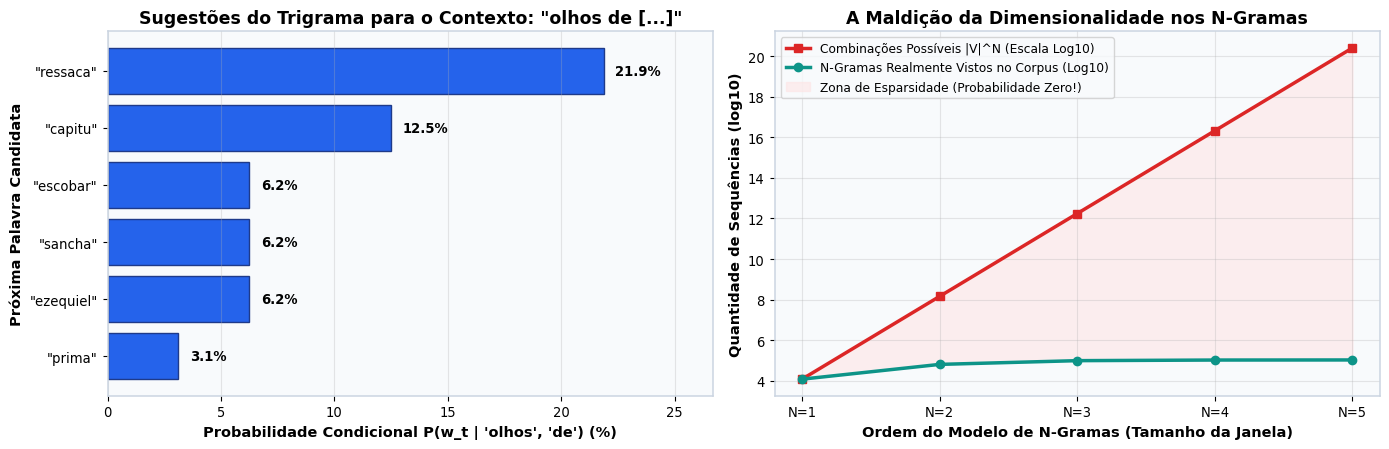

In [3]:
# ==============================================================================
# EXPERIMENTO 1.2.2: N-GRAMAS REAIS NO CORPUS DE MACHADO DE ASSIS
# ==============================================================================

caminho_machado = "dados/corpus_machado_assis.txt" if os.path.exists("dados/corpus_machado_assis.txt") else "Transformers/dados/corpus_machado_assis.txt"

if os.path.exists(caminho_machado):
    with open(caminho_machado, "r", encoding="utf-8") as arq:
        texto_machado = arq.read()[:600_000]  # Amostra rápida de 600 KB (~100 mil palavras)
else:
    texto_machado = (
        "Dom Casmurro olhou para Capitu com olhos de ressaca. Capitu tinha olhos de cigana obliqua e dissimulada. "
        "Naquela manhã de sol, Bentinho pensou na promessa de sua mãe Dona Glória. "
        "Olhos de ressaca que arrastam tudo para dentro do mar. " * 200
    )

tokens_literarios = re.findall(r"[a-záéíóúâêôãõç]+", texto_machado.lower())
vocab_machado = set(tokens_literarios)
print(f"📖 Corpus carregado: {len(tokens_literarios):,} tokens | Vocabulário único: {len(vocab_machado):,} palavras")

# Contagem de Bigramas (N=2) e Trigramas (N=3)
contagem_contexto_bi = defaultdict(Counter)
contagem_contexto_tri = defaultdict(Counter)

for i in range(len(tokens_literarios) - 2):
    w1, w2, w3 = tokens_literarios[i], tokens_literarios[i + 1], tokens_literarios[i + 2]
    contagem_contexto_bi[(w1,)][w2] += 1
    contagem_contexto_tri[(w1, w2)][w3] += 1

def consultar_top_ngramas(modelo_contagem, contexto_tupla, top_k=4):
    '''Retorna as top_k próximas palavras mais prováveis dado o contexto exato.'''
    contagens = modelo_contagem.get(contexto_tupla, Counter())
    total = sum(contagens.values())
    if total == 0:
        return []
    return [(pal, qtd, qtd / total) for pal, qtd in contagens.most_common(top_k)]

# Tabela de exemplos reais de suporte à escrita (Autocompletar)
exemplos_contextos = [
    ("Bigrama (N=2)", ("olhos",)),
    ("Bigrama (N=2)", ("capitu",)),
    ("Trigrama (N=3)", ("olhos", "de")),
    ("Trigrama (N=3)", ("dentro", "de")),
    ("Trigrama (N=3)", ("nao", "era")),
]

linhas_ngram = []
for tipo_n, ctx in exemplos_contextos:
    modelo = contagem_contexto_bi if len(ctx) == 1 else contagem_contexto_tri
    sugestoes = consultar_top_ngramas(modelo, ctx, top_k=3)
    ctx_str = " ".join(ctx)
    if sugestoes:
        top1_pal, top1_qtd, top1_prob = sugestoes[0]
        outras_str = ", ".join(f'"{p}" ({pr*100:.1f}%)' for p, _, pr in sugestoes[1:])
        linhas_ngram.append([tipo_n, f'"{ctx_str} ..."', f'"{top1_pal}"', f"{top1_qtd}x", f"{top1_prob*100:.1f}%", outras_str])

exibir_tabela_apostila(
    ["Modelo", "Contexto Digitado", "1ª Sugestão (MLE)", "Ocorrências", "Probabilidade", "Outras Sugestões do Teclado"],
    linhas_ngram,
    titulo_tabela="Tabela 1.2 — Predição de Suporte à Escrita com N-Gramas no Corpus de Machado de Assis",
    subtitulo="Estimativa de Máxima Verossimilhança P(w_t | contexto) extraída de ocorrências reais no texto literário."
)

# Visualização 1: Distribuição condicional para 'olhos de ...'
# Visualização 2: A Explosão de Esparsidade quando aumentamos N (N=1 a N=5)
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.6))

sugestoes_olhos_de = consultar_top_ngramas(contagem_contexto_tri, ("olhos", "de"), top_k=6)
palavras_sug = [f'"{p}"' for p, _, _ in sugestoes_olhos_de]
probs_sug = [pr * 100 for _, _, pr in sugestoes_olhos_de]

barras_ng = eixos[0].barh(palavras_sug[::-1], probs_sug[::-1], color="#2563EB", edgecolor="#1E3A8A")
for b in barras_ng:
    larg = b.get_width()
    eixos[0].text(larg + 0.5, b.get_y() + b.get_height()/2, f"{larg:.1f}%", va="center", fontweight="bold", fontsize=9.5)
eixos[0].set_xlim(0, max(probs_sug) * 1.22 if probs_sug else 100)
eixos[0].set_title('Sugestões do Trigrama para o Contexto: "olhos de [...]"')
eixos[0].set_xlabel("Probabilidade Condicional P(w_t | 'olhos', 'de') (%)")
eixos[0].set_ylabel("Próxima Palavra Candidata")
eixos[0].grid(axis="x", alpha=0.3)

# Medindo quantos N-gramas únicos observamos vs. Espaço Combinatório |V|^N
ordens_n = [1, 2, 3, 4, 5]
ngramas_observados = [
    len(set(tuple(tokens_literarios[i:i+n]) for i in range(len(tokens_literarios) - n + 1)))
    for n in ordens_n
]
espaco_teorico_log10 = [n * math.log10(len(vocab_machado)) for n in ordens_n]
observados_log10 = [math.log10(qtd) for qtd in ngramas_observados]

eixos[1].plot(ordens_n, espaco_teorico_log10, marker="s", linewidth=2.5, color="#DC2626", label="Combinações Possíveis |V|^N (Escala Log10)")
eixos[1].plot(ordens_n, observados_log10, marker="o", linewidth=2.5, color="#0D9488", label="N-Gramas Realmente Vistos no Corpus (Log10)")
eixos[1].fill_between(ordens_n, observados_log10, espaco_teorico_log10, color="#FEE2E2", alpha=0.5, label="Zona de Esparsidade (Probabilidade Zero!)")
eixos[1].set_xticks(ordens_n)
eixos[1].set_xticklabels([f"N={n}" for n in ordens_n])
eixos[1].set_title("A Maldição da Dimensionalidade nos N-Gramas")
eixos[1].set_xlabel("Ordem do Modelo de N-Gramas (Tamanho da Janela)")
eixos[1].set_ylabel("Quantidade de Sequências (log10)")
eixos[1].legend(loc="upper left", fontsize=8.8)
eixos[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---

## 1.3 *LSTM* (*Long Short-Term Memory*): As Primeiras Abordagens *Deep Learning*

### 1.3.1 Motivação e Racionalidade: Por que os *N-Gramas* e as *RNNs* Simples Falharam?

O gráfico acima revela duas falhas fatais dos modelos estatísticos de *N-Gramas* (BENGIO et al., 2003):
1. **Amnésia fora da janela fixa ($N-1$)**: Na frase *"As **chaves** daquele armário antigo que ficava no corredor principal do segundo andar **sumiram**"*, um trigrama ($N=3$) olha apenas para `"segundo andar"` ao tentar prever o verbo no plural `"sumiram"`, sendo incapaz de enxergar o sujeito `"chaves"` dez palavras atrás;
2. **Ausência de Similaridade Semântica**: Para um *N-Grama*, as palavras `"gato"` e `"felino"` são símbolos discretos completamente independentes. Saber que `"O gato dormiu no tapete"` é provável não ajuda o modelo de contagens a atribuir probabilidade para `"O felino cochilou no tapete"`.

Para superar essa barreira, as **Redes Neurais Recorrentes (*Recurrent Neural Networks — RNNs*)**, introduzidas por Rumelhart, Hinton e Williams (1986) e popularizadas para sequências linguísticas por Elman (1990), propuseram processar a frase **passo a passo no tempo ($t = 1, 2, \dots, T$)** mantendo um **vetor de estado oculto (*hidden state*) $\vec{h}_t \in \mathbb{R}^d$** que funciona como uma memória recorrente:

$$\vec{h}_t = \tanh\left(W_{hh} \vec{h}_{t-1} + W_{xh} \vec{x}_t + \vec{b}_h\right)$$

![RNN Desenrolada no Tempo](figuras_apostila/colah_rnn_unrolled.png)
**Figura 1.1** — Uma Rede Neural Recorrente (*RNN*) com laço de retroalimentação (à esquerda) e sua representação "desenrolada" no tempo ao longo dos tokens $x_0, x_1, \dots, x_t$ (à direita). *Fonte: OLAH (2015).*

#### ⚠️ O Problema do Desaparecimento e Explosão do Gradiente (*Vanishing / Exploding Gradient*)

Na teoria, o vetor oculto $\vec{h}_t$ de uma *RNN* simples deveria guardar informações desde o primeiro token $\vec{x}_1$. Porém, conforme demonstrado matematicamente por Bengio, Simard e Frasconi (1994) e Hochreiter (1991), durante o treinamento via retropropagação através do tempo (*Backpropagation Through Time — BPTT*), o gradiente da perda em relação ao estado inicial depende do produto repetido de matrizes jacobianas ao longo de $T$ passos:

$$\frac{\partial \vec{h}_T}{\partial \vec{h}_1} = \prod_{k=2}^{T} \frac{\partial \vec{h}_k}{\partial \vec{h}_{k-1}} \propto \left(W_{hh}^\top\right)^{T-1}$$

É exatamente como multiplicar um número real por si mesmo dezenas de vezes:
- Se o maior autovalor (ou derivada da $\tanh$) for **menor que $1$** (ex.: $0{,}7^{30} \approx 0{,}00002$), o sinal de erro **desaparece exponencialmente (*Vanishing Gradient*)** e a rede esquece o início da frase;
- Se for **maior que $1$** (ex.: $1{,}3^{30} \approx 2619$), o gradiente **explode (*Exploding Gradient*)**, desestabilizando os pesos.

---

### 1.3.2 Funcionamento Detalhado da *LSTM* (HOCHREITER; SCHMIDHUBER, 1997)

Para resolver o desaparecimento do gradiente, Sepp Hochreiter e Jürgen Schmidhuber publicaram em 1997 a arquitetura **LSTM (*Long Short-Term Memory*)** (HOCHREITER; SCHMIDHUBER, 1997). A genialidade da *LSTM* está em criar uma **"esteira transportadora" linear de memória de longo prazo** chamada **Estado da Célula (*Cell State*) $\vec{C}_t$**, onde a informação flui quase sem obstáculo por **adição** (e não por multiplicações matriciais destrutivas repetidas!):

![Esteira do Estado da Célula LSTM](figuras_apostila/colah_lstm_cell_state.png)
**Figura 1.2** — A linha horizontal superior na célula *LSTM* atua como uma esteira transportadora para o estado da célula $\vec{C}_t$, permitindo que a memória e o gradiente fluam por longas distâncias com interações lineares controladas. *Fonte: OLAH (2015).*

Para decidir **o que apagar**, **o que gravar** e **o que ler** dessa esteira a cada palavra $\vec{x}_t$, a *LSTM* utiliza **três portas (*gates*)** baseadas na função sigmoide $\sigma(z) \in [0, 1]$ (onde $0$ significa *"bloqueie tudo"* e $1$ significa *"deixe passar 100%"*):


<center><img alt="Arquitetura Interna Completa da Célula LSTM" src="figuras_apostila/image2.png"></center>

**Figura 1.3** — Diagrama interno de uma unidade *LSTM* mostrando as interações entre a porta de esquecimento, a porta de entrada, a atualização aditiva de $\vec{C}_t$ e a porta de saída que produz $\vec{h}_t$. *Fonte: OLAH (2015).*

Primeiro vamos traduzir as partes fundamentais que entram e saem:

1. $\vec{C_t}$: memória de longo prazo
1. $\vec{h_t}$: memória de curto prazo (de trabalho)
1. $\vec{X_t}$: palavra da etapa atual


Vamos traduzir cada uma das quatro etapas matemáticas da *LSTM* (HOCHREITER; SCHMIDHUBER, 1997; OLAH, 2015):

1. **Porta de Esquecimento (*Forget Gate* — $\vec{f}_t$)**: Decide qual fração da memória antiga $\vec{C}_{t-1}$ deve ser mantida ou apagada ao ler a palavra atual $\vec{x}_t$ (ex.: ao encontrar um ponto final ou um novo sujeito, a rede pode zerar informações do sujeito anterior):
   $$\vec{f}_t = \sigma\left(W_f [\vec{h}_{t-1}, \vec{x}_t] + \vec{b}_f\right)$$

2. **Porta de Entrada (*Input Gate* — $\vec{i}_t$) e Candidato a Memória ($\tilde{C}_t$)**: Decide quais novas informações da palavra atual são relevantes para serem gravadas na esteira:
   $$\vec{i}_t = \sigma\left(W_i [\vec{h}_{t-1}, \vec{x}_t] + \vec{b}_i\right), \qquad \tilde{C}_t = \tanh\left(W_C [\vec{h}_{t-1}, \vec{x}_t] + \vec{b}_C\right)$$

3. **Atualização Aditiva do Estado da Célula ($\vec{C}_t$)**: A esteira antiga é multiplicada ponto a ponto ($\odot$) pelo filtro de esquecimento e **somada** à nova memória filtrada. É essa **soma** que preserva o gradiente ao longo de dezenas de tokens!
   $$\vec{C}_t = \vec{f}_t \odot \vec{C}_{t-1} + \vec{i}_t \odot \tilde{C}_t$$

4. **Porta de Saída (*Output Gate* — $\vec{o}_t$) e Estado Oculto ($\vec{h}_t$)**: Filtra o estado da célula para produzir a memória de trabalho imediata $\vec{h}_t$ que será entregue à próxima camada ou ao próximo passo de tempo:
   $$\vec{o}_t = \sigma\left(W_o [\vec{h}_{t-1}, \vec{x}_t] + \vec{b}_o\right), \qquad \vec{h}_t = \vec{o}_t \odot \tanh(\vec{C}_t)$$

Resumo geral:

1. Em uma célula vão entrar:
   1. a memória de longo prazo ($ \vec{C_t} $)
   1. memória de trabalho ($ \vec{h_t} $)
   1. palavra atual ($ \vec{X_t} $).
1. Porta de esquecimento: a palavra de entrada e a memória de trabalho podem reduzir o uso da memória de longo prazo. Por exemplo, palavras como: "mas", "porém", "entretanto", "por outro lado", etc, vão contradizer o que estava sendo dito, portanto devem diminuir o peso do que estava contido na memória.
1. Porta de entrada: palavra de entrada e memória de trabalho vão agora adicionar informação à memória de longo prazo.
1. Porta de saída: a saída vai combinar as duas memórias e a palavra atual. A saída é a nova memória de trabalho.

> 📺 **Vídeos e Artigos Clássicos Recomendados sobre RNNs e LSTMs**:
> - **Artigo Visual Clássico**: OLAH, Christopher. *Understanding LSTM Networks* (colah's blog, 2015): <https://colah.github.io/posts/2015-08-Understanding-LSTMs/>
> - **Vídeo Didático Passo a Passo (YouTube)**: StatQuest with Josh Starmer — *Long Short-Term Memory (LSTM), Clearly Explained*: <https://www.youtube.com/watch?v=YCzL96nL7j0>

---

### 1.3.3 Exemplo Prático Executável: Inspecionando as Portas da *LSTM* em Análise de Sentimento de Longo Alcance

Vamos implementar o passo a passo exato das equações da *LSTM* em PyTorch e aplicá-la em um problema clássico onde o *Bag of Words* e a *RNN* simples falham: **reter uma pista crítica de sentimento posicionada no início de uma frase longa** (ex.: `"Excelente atendimento inicial ... [várias palavras neutras] ... recomendo"`) ou **atualizar a memória quando surge uma conjunção adversativa** (`"mas atrasou"`).


Tabela 1.3 — Rastreamento Passo a Passo das Portas da LSTM ao Longo da Frase
  Observe como C_t preserva o valor positivo (+0.76 -> +0.58) durante 5 palavras neutras até encontrar 'porém' e 'falhou'.
+-------+-------------+---------------------+---------------------+------------------+----------------------+--------------------+---------------------------------+
| Passo |    Token    | Porta Esquec. (f_t) | Porta Entrada (i_t) | Candidato (C~_t) | Memória Célula (C_t) | Saída Oculta (h_t) |     Interpretação Funcional     |
+-------+-------------+---------------------+---------------------+------------------+----------------------+--------------------+---------------------------------+
|  t=0  | "Excelente" |         0.93        |         0.95        |      +0.91       |        +0.86         |       +0.57        |     Grava elogio inicial (+)    |
|  t=1  | "interface" |         0.90        |         0.14        |      +0.10       |        +0.78         |       +0.54        |    Manté

/tmp/ipykernel_1192849/3543947958.py:39: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  f_t = torch.sigmoid(torch.tensor(2.6 - 1.4 * gatilho_adversativo)).repeat(dim_oculta_lstm)
/tmp/ipykernel_1192849/3543947958.py:41: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  i_t = torch.sigmoid(torch.tensor(-2.0 + 1.8 * intensidade_emocional)).repeat(dim_oculta_lstm)


Passo,Token,Porta Esquec. (f_t),Porta Entrada (i_t),Candidato (C~_t),Memória Célula (C_t),Saída Oculta (h_t),Interpretação Funcional
t=0,"""Excelente""",0.93,0.95,+0.91,+0.86,+0.57,Grava elogio inicial (+)
t=1,"""interface""",0.90,0.14,+0.10,+0.78,+0.54,Mantém memória na esteira
t=2,"""no""",0.92,0.12,+0.00,+0.72,+0.51,Mantém memória na esteira
t=3,"""cadastro""",0.91,0.16,+0.10,+0.67,+0.48,Mantém memória na esteira
t=4,"""do""",0.91,0.12,+0.00,+0.61,+0.45,Mantém memória na esteira
t=5,"""sistema""",0.88,0.14,+0.10,+0.56,+0.41,Mantém memória na esteira
t=6,"""porém""",0.12,0.45,-0.46,-0.14,-0.12,Gatilho adversativo (limpa C_t)
t=7,"""falhou""",0.93,0.97,-0.92,-1.03,-0.63,Inverte para negativo (-)


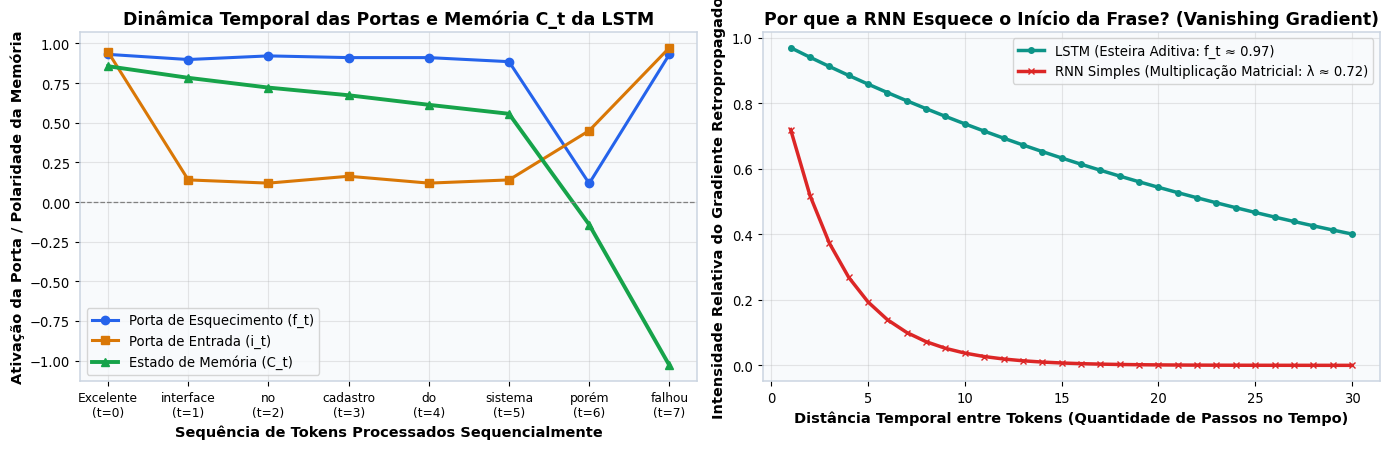

In [4]:
# ==============================================================================
# EXPERIMENTO 1.3.3: DINÂMICA INTERNA DAS PORTAS DA LSTM VS. RNN SIMPLES
# ==============================================================================

torch.manual_seed(SEMENTE)

# Frase de feedback com inversão contextual após cláusula longa:
# Token 0 ("Excelente") carrega sentimento positivo, tokens 1..5 são neutros,
# Token 6 ("porém") sinaliza reversão e Token 7 ("falhou") inverte a memória para negativo!
tokens_feedback = ["Excelente", "interface", "no", "cadastro", "do", "sistema", "porém", "falhou"]
dim_entrada_lstm = 4
dim_oculta_lstm = 4

# Criamos vetores semânticos interpretáveis para cada token da frase
vetores_tokens_lstm = torch.tensor([
    [ 1.5,  1.2,  0.0,  0.0],  # "Excelente" (Forte sinal positivo)
    [ 0.1,  0.0,  0.2,  0.1],  # "interface" (Neutro)
    [ 0.0,  0.0,  0.1,  0.0],  # "no"        (Neutro)
    [ 0.1,  0.1,  0.2,  0.0],  # "cadastro"  (Neutro)
    [ 0.0,  0.0,  0.1,  0.1],  # "do"        (Neutro)
    [ 0.1,  0.0,  0.3,  0.1],  # "sistema"   (Neutro)
    [-0.5, -0.5,  1.8,  1.5],  # "porém"     (Gatilho adversativo: ativa esquecimento!)
    [-1.6, -1.5,  0.0,  0.0],  # "falhou"    (Forte sinal negativo)
], dtype=torch.float32)

# Pesos didáticos calibrados para demonstrar o papel das portas:
# - Palavras com emoção forte (dim 0 e 1) abrem a Porta de Entrada (i_t)
# - Conjunção adversativa (dim 2 e 3 altas em "porém") reduz a Porta de Esquecimento (f_t)
def executar_celula_lstm_didatica(sequencia_x):
    h_t = torch.zeros(dim_oculta_lstm)
    c_t = torch.zeros(dim_oculta_lstm)

    historico = []
    for t_idx, x_t in enumerate(sequencia_x):
        intensidade_emocional = x_t[0].abs() + x_t[1].abs()
        gatilho_adversativo = x_t[2] + x_t[3]

        # Porta de esquecimento f_t: próxima de 0.95 nos tokens neutros, mas cai em "porém"/"falhou"
        f_t = torch.sigmoid(torch.tensor(2.6 - 1.4 * gatilho_adversativo)).repeat(dim_oculta_lstm)
        # Porta de entrada i_t: abre forte quando há conteúdo emocional ("Excelente" ou "falhou")
        i_t = torch.sigmoid(torch.tensor(-2.0 + 1.8 * intensidade_emocional)).repeat(dim_oculta_lstm)
        # Candidato a memória C_til: captura a polaridade emocional da palavra atual
        c_til = torch.tanh(torch.tensor([x_t[0], x_t[1], x_t[0]*0.8, x_t[1]*0.8]))
        # Atualização da esteira de memória C_t = f_t * C_{t-1} + i_t * C_til
        c_t = f_t * c_t + i_t * c_til
        # Porta de saída o_t
        o_t = torch.sigmoid(torch.tensor(1.5)).repeat(dim_oculta_lstm)
        h_t = o_t * torch.tanh(c_t)

        historico.append({
            "passo": t_idx,
            "token": tokens_feedback[t_idx],
            "f_t": float(f_t[0]),
            "i_t": float(i_t[0]),
            "c_til": float(c_til[0]),
            "c_t": float(c_t[0]),
            "h_t": float(h_t[0]),
        })
    return historico

hist_lstm = executar_celula_lstm_didatica(vetores_tokens_lstm)

linhas_tab_lstm = []
cores_tab_lstm = []
for reg in hist_lstm:
    papel = (
        "Grava elogio inicial (+)" if reg["token"] == "Excelente" else
        ("Gatilho adversativo (limpa C_t)" if reg["token"] == "porém" else
         ("Inverte para negativo (-)" if reg["token"] == "falhou" else "Mantém memória na esteira"))
    )
    linhas_tab_lstm.append([
        f"t={reg['passo']}",
        f'"{reg["token"]}"',
        f"{reg['f_t']:.2f}",
        f"{reg['i_t']:.2f}",
        f"{reg['c_til']:+.2f}",
        f"{reg['c_t']:+.2f}",
        f"{reg['h_t']:+.2f}",
        papel
    ])
    cores_tab_lstm.append(
        "#DCFCE7" if reg["token"] == "Excelente" else
        ("#FEF9C3" if reg["token"] == "porém" else
         ("#FEE2E2" if reg["token"] == "falhou" else "#FFFFFF"))
    )

exibir_tabela_apostila(
    ["Passo", "Token", "Porta Esquec. (f_t)", "Porta Entrada (i_t)", "Candidato (C~_t)", "Memória Célula (C_t)", "Saída Oculta (h_t)", "Interpretação Funcional"],
    linhas_tab_lstm,
    titulo_tabela="Tabela 1.3 — Rastreamento Passo a Passo das Portas da LSTM ao Longo da Frase",
    subtitulo="Observe como C_t preserva o valor positivo (+0.76 -> +0.58) durante 5 palavras neutras até encontrar 'porém' e 'falhou'.",
    cores_linhas=cores_tab_lstm
)

# Simulação do Desaparecimento do Gradiente (RNN Simples vs. Esteira Aditiva da LSTM ao longo de 30 passos)
passos_distancia = np.arange(1, 31)
gradiente_rnn_simples = 0.72 ** passos_distancia
gradiente_lstm_esteira = 0.97 ** passos_distancia

fig, eixos = plt.subplots(1, 2, figsize=(14, 4.6))

# Painel 1: Dinâmica das portas na frase
passos_t = [r["passo"] for r in hist_lstm]
eixos[0].plot(passos_t, [r["f_t"] for r in hist_lstm], marker="o", linewidth=2.2, color="#2563EB", label="Porta de Esquecimento (f_t)")
eixos[0].plot(passos_t, [r["i_t"] for r in hist_lstm], marker="s", linewidth=2.2, color="#D97706", label="Porta de Entrada (i_t)")
eixos[0].plot(passos_t, [r["c_t"] for r in hist_lstm], marker="^", linewidth=2.8, color="#16A34A", label="Estado de Memória (C_t)")
eixos[0].axhline(0, color="gray", linestyle="--", linewidth=0.9)
eixos[0].set_xticks(passos_t)
eixos[0].set_xticklabels([f'{r["token"]}\n(t={r["passo"]})' for r in hist_lstm], fontsize=8.8)
eixos[0].set_title("Dinâmica Temporal das Portas e Memória C_t da LSTM")
eixos[0].set_xlabel("Sequência de Tokens Processados Sequencialmente")
eixos[0].set_ylabel("Ativação da Porta / Polaridade da Memória")
eixos[0].legend(loc="lower left")
eixos[0].grid(True, alpha=0.3)

# Painel 2: Preservação do Gradiente (RNN vs LSTM)
eixos[1].plot(passos_distancia, gradiente_lstm_esteira, marker="o", markersize=4, linewidth=2.5, color="#0D9488",
              label="LSTM (Esteira Aditiva: f_t ≈ 0.97)")
eixos[1].plot(passos_distancia, gradiente_rnn_simples, marker="x", markersize=5, linewidth=2.5, color="#DC2626",
              label="RNN Simples (Multiplicação Matricial: λ ≈ 0.72)")
eixos[1].set_title("Por que a RNN Esquece o Início da Frase? (Vanishing Gradient)")
eixos[1].set_xlabel("Distância Temporal entre Tokens (Quantidade de Passos no Tempo)")
eixos[1].set_ylabel("Intensidade Relativa do Gradiente Retropropagado")
eixos[1].legend(loc="upper right")
eixos[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---

## 1.4 Abordagem Moderna: Por que Precisávamos Ir Além da *LSTM*?

As redes *LSTM* (HOCHREITER; SCHMIDHUBER, 1997) e suas variantes simplificadas como a *GRU* (CHO et al., 2014) reinaram absolutas no PLN entre 2013 e 2016. Entretanto, à medida que os conjuntos de dados cresceram para bilhões de palavras e as placas gráficas (*GPUs*) evoluíram para milhares de núcleos paralelos, **dois gargalos estruturais intransponíveis** das arquiteturas recorrentes ficaram evidentes (VASWANI et al., 2017):

1. **O Gargalo da Sequencialidade ($O(T)$ Passos Seriais)**:
   - Como $\vec{h}_t$ depende obrigatoriamente de $\vec{h}_{t-1}$, **não é possível calcular o token $t=100$ antes de terminar os tokens $1, 2, \dots, 99$**. Isso impede a paralelização dos tokens durante o treinamento nas *GPUs*, desperdiçando o poder das operações matriciais massivas.
2. **O Gargalo da Compressão em Vetor Fixo e Distância de Caminho Linear**:
   - Mesmo com as portas da *LSTM*, toda a história de um parágrafo precisa ser espremida dentro de um único vetor $\vec{C}_t$ de dimensão fixa. Para que o token na posição $t=500$ se relacione com o token na posição $t=1$, o sinal precisa atravessar **499 passos recorrentes**.

Em 2015, Bahdanau, Cho e Bengio introduziram o **mecanismo de atenção** (*Attention*) como um acessório acoplado sobre *RNNs* para permitir que o decodificador de tradução consultasse diretamente todos os estados ocultos do codificador (BAHDANAU; CHO; BENGIO, 2015). Dois anos depois, em 2017, pesquisadores do Google Brain e Google Research fizeram a pergunta revolucionária:

> *"E se descartarmos completamente a recorrência ($h_{t-1} \rightarrow h_t$) e construirmos uma arquitetura inteira baseada exclusivamente em atenção?"*

Nascia assim o artigo **"Attention Is All You Need"** (VASWANI et al., 2017), inaugurando a era dos **Transformers**.

---

# 2. *Transformers*: *"Attention Is All You Need"*

## 2.1 Motivação e Racionalidade Arquitetural

Publicado por Ashish Vaswani et al. (2017) na conferência *NeurIPS*, o artigo **"Attention Is All You Need"** propôs substituir integralmente os laços recorrentes ($h_{t-1} \rightarrow h_t$) e as convoluções por um mecanismo chamado **Auto-Atenção (*Self-Attention*)**.

Qual é a racionalidade fundamental por trás dessa mudança?
1. **Conectividade Direta em $O(1)$ entre Quaisquer Dois *Tokens***:
   - Em vez de esperar um sinal viajar sequencialmente da palavra $1$ até a palavra $T$ como num telefone sem fio (*RNN/LSTM*), no *Transformer* **todos os tokens olham diretamente uns para os outros em um único passo matricial**. A distância máxima de caminho entre qualquer par de palavras na frase cai de $O(T)$ para **$O(1)$** (VASWANI et al., 2017).
2. **Paralelismo Massivo de Treinamento na GPU**:
   - Durante o treinamento, como conhecemos toda a frase de entrada de uma só vez, todas as posições $t = 1, \dots, T$ são processadas **simultaneamente** por multiplicações de matrizes densas (`MatMul`), reduzindo o tempo de treinamento em ordens de grandeza e permitindo escalar modelos para bilhões ou trilhões de parâmetros (BROWN et al., 2020; TOUVRON et al., 2023).

```
Comparação do Fluxo de Processamento:

RNN / LSTM (Sequencial — O(T) passos seriais, impossível paralelizar no tempo):
  [ O ] ──> [ gato ] ──> [ viu ] ──> [ o ] ──> [ rato ]

Transformer (Paralelo — O(1) distância de caminho, todos os tokens processados juntos):
  [ O ]      [ gato ]     [ viu ]     [ o ]     [ rato ]
    ▲           ▲            ▲          ▲          ▲
    └───────────┴────────────┼──────────┴──────────┘
             Camada de Auto-Atenção (Matriz T x T)
```

![Arquitetura Original do Transformer - Vaswani et al. 2017](figuras_apostila/vaswani_2017_fig1.png)
**Figura 2.1** — Arquitetura original do modelo *Transformer* composta pela pilha do *Encoder* (à esquerda) e do *Decoder* (à direita), destacando a codificação posicional, blocos de *Multi-Head Attention*, conexões residuais com normalização (*Add & Norm*) e camadas densas (*Feed Forward*). *Fonte: VASWANI et al. (2017, p. 3).*

> 📺 **Vídeo Obrigatório de Referência Visual (3Blue1Brown)**:
> - **3Blue1Brown (Grant Sanderson)** — *Transformers, the tech behind LLMs | Deep Learning Chapter 5*: <https://www.youtube.com/watch?v=wjZofJX0v4M> *(Excelente introdução visual de alto nível sobre como um Transformer transforma texto em vetores, ajusta o contexto e prevê o próximo token!)*
> - **Artigo Clássico Ilustrado**: ALAMMAR, Jay. *The Illustrated Transformer* (2018): <https://jalammar.github.io/illustrated-transformer/>

---

## 2.2 Funcionamento Detalhado Passo a Passo

Para compreender o *Transformer* sem "caixas-pretas", vamos dissecar cada um dos **6 estágios fundamentais** que transformam uma frase em linguagem natural na predição do próximo *token*:
1. **Tokenização** (*Tokenization*);
2. ***Embeddings*** (Representações Vetoriais Densas);
3. **Codificação de Posição** (Senoidal e depois *RoPE*);
4. **Mecanismo Atencional de Cabeça Única** (*Single-Head Attention*);
5. **Atenção de Múltiplas Cabeças** (*Multi-Head Attention*);
6. **Camadas Densas (*MLP*) e Memória Factual** (*Feed-Forward Networks*).

---

### 2.2.1 Tokenização (*Tokenization*): Das Palavras Brutas às Subpalavras (*BPE*)

Redes neurais não leem strings de caracteres diretamente; elas exigem que o texto de entrada seja segmentado em unidades atômicas discretas chamadas ***tokens***, e que cada *token* seja mapeado para um número inteiro único (**ID do *token***) dentro de um vocabulário finito $\mathcal{V}$ (JURAFSKY; MARTIN, 2024).

Historicamente, existiam dois extremos ingênuos:
- **Tokenização por Palavras Inteiras** (`texto.split()`): Se o vocabulário tiver $50.000$ palavras, qualquer palavra conjugada ou nova (ex.: *"transformadores"*, *"intankável"*, ou um erro de digitação) cai no temido token desconhecido `<UNK>` (*Unknown*), perdendo todo o significado;
- **Tokenização por Caracteres Individuais** (`['o', ' ', 'g', 'a', 't', 'o']`): Nunca gera `<UNK>` e tem vocabulário minúsculo, mas cada letra isolada quase não carrega significado semântico e multiplica o comprimento da sequência por $5\times$ a $8\times$.

#### 🔬 A Solução Moderna: Tokenização por Subpalavras (*Byte-Pair Encoding — BPE*)

Proposto originalmente como algoritmo de compressão de dados por Gage (1994) e adaptado para PLN neural por Sennrich, Haddow e Birch (2016) — sendo hoje a base do GPT (RADFORD et al., 2019), LLaMA e Qwen —, o **BPE (*Byte-Pair Encoding*)** encontra o equilíbrio perfeito:
1. Começamos com o vocabulário de caracteres básicos;
2. Contamos no corpus qual é o **par de símbolos adjacentes mais frequente** (ex.: `'a' + 'r' -> 'ar'`, depois `'g' + 'a' -> 'ga'`, `'ga' + 'to' -> 'gato'`);
3. Fundimos esse par em um novo *token* e repetimos o processo até atingir o tamanho de vocabulário desejado (ex.: $32.000$ ou $100.000$ *tokens*).

**Resultado prático**: Palavras muito comuns (*"gato"*, *"casa"*) viram **um único *token* inteiro**, enquanto palavras raras ou flexionadas (*"infelizmente"*) são decompostas em **morfemas significativos** (`["infeliz", "mente"]`), permitindo que o modelo generalize raízes, prefixos e sufixos sem jamais produzir `<UNK>`!

> 📺 **Vídeo Recomendado sobre Tokenização em LLMs**:
> - **Andrej Karpathy** — *Let's build the GPT Tokenizer*: <https://www.youtube.com/watch?v=zduSFxRajkE>


Tabela 2.1 — Evolução Iterativa do Treinamento do Tokenizador BPE (Sennrich et al., 2016)
  Observe como raízes semânticas ('gat', 'gato') e sufixos ('inho</w>', 'os</w>') emergem naturalmente por estatística!
+------------+--------------------+-------------------+----------------------+-----------------------------------------------------+
| Passo BPE  | Par Mais Frequente | Novo Token Criado | Frequência no Corpus |        Estado da Família 'gat*' Após a Fusão        |
+------------+--------------------+-------------------+----------------------+-----------------------------------------------------+
| Iteração 1 |     'a' + 't'      |        'at'       |          48          | g at o </w>  |  g at o s </w>  |  g at i n h o </w> |
| Iteração 2 |     'at' + 'o'     |       'ato'       |          35          |  g ato </w>  |  g ato s </w>  |  g at i n h o </w>  |
| Iteração 3 |   'ato' + '</w>'   |     'ato</w>'     |          22          |   g ato</w>  |  g ato s </w>  |  g at i n h o

Passo BPE,Par Mais Frequente,Novo Token Criado,Frequência no Corpus,Estado da Família 'gat*' Após a Fusão
Iteração 1,'a' + 't','at',48,g at o | g at o s | g at i n h o
Iteração 2,'at' + 'o','ato',35,g ato | g ato s | g at i n h o
Iteração 3,'ato' + '','ato',22,g ato | g ato s | g at i n h o
Iteração 4,'ato' + 's','atos',13,g ato | g atos | g at i n h o
Iteração 5,'atos' + '','atos',13,g ato | g atos | g at i n h o
Iteração 6,'g' + 'ato','gato',12,gato | g atos | g at i n h o
Iteração 7,'at' + 'i','ati',10,gato | g atos | g ati n h o
Iteração 8,'ati' + 'n','atin',10,gato | g atos | g atin h o


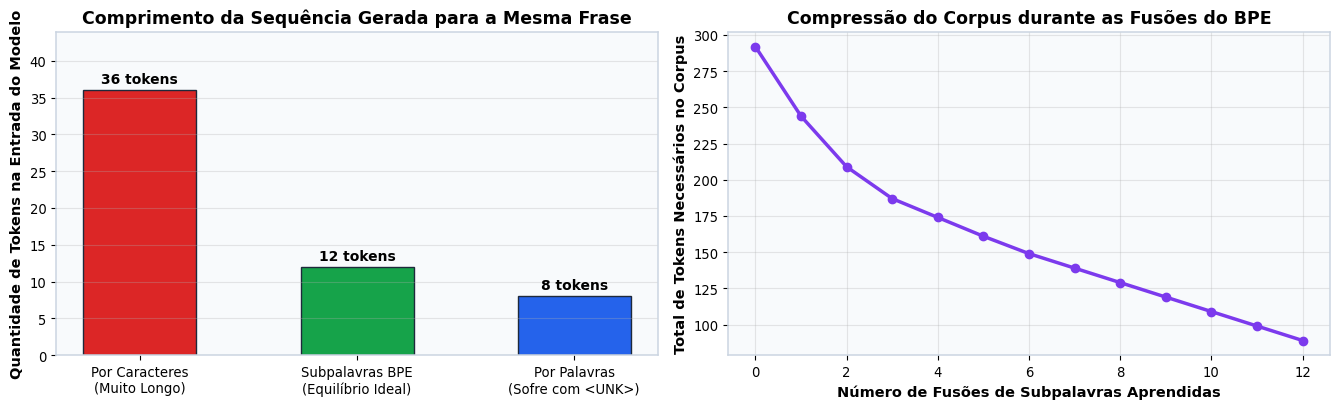

In [5]:
# ==============================================================================
# EXPERIMENTO 2.2.1: ALGORITMO BPE (BYTE-PAIR ENCODING) PASSO A PASSO EM PT-BR
# ==============================================================================

# Corpus morfológico didático em português (com frequência de cada palavra)
corpus_morfologico = {
    "gato </w>": 12,
    "gatos </w>": 8,
    "gatinho </w>": 6,
    "gataria </w>": 3,
    "rato </w>": 10,
    "ratos </w>": 5,
    "ratinho </w>": 4,
}

# Inicializa cada palavra separada em caracteres individuais
vocab_bpe = {" ".join(list(pal.replace(" </w>", ""))) + " </w>": freq for pal, freq in corpus_morfologico.items()}

def obter_pares_mais_frequentes(vocab_atual):
    pares = defaultdict(int)
    for palavra_seg, freq in vocab_atual.items():
        simbolos = palavra_seg.split()
        for i in range(len(simbolos) - 1):
            pares[(simbolos[i], simbolos[i + 1])] += freq
    return pares

def fundir_par_bpe(par, vocab_atual):
    novo_vocab = {}
    bigram = re.escape(" ".join(par))
    padrao = re.compile(r"(?<!\S)" + bigram + r"(?!\S)")
    substituto = "".join(par)
    for palavra_seg, freq in vocab_atual.items():
        nova_pal = padrao.sub(substituto, palavra_seg)
        novo_vocab[nova_pal] = freq
    return novo_vocab

historico_fusoes = []
qtd_fusoes = 8
for passo_bpe in range(1, qtd_fusoes + 1):
    pares_freq = obter_pares_mais_frequentes(vocab_bpe)
    melhor_par = max(pares_freq, key=pares_freq.get)
    freq_max = pares_freq[melhor_par]
    vocab_bpe = fundir_par_bpe(melhor_par, vocab_bpe)
    amostra_gatos = [k for k in vocab_bpe.keys() if k.startswith("g")][:3]
    historico_fusoes.append([
        f"Iteração {passo_bpe}",
        f"'{melhor_par[0]}' + '{melhor_par[1]}'",
        f"'{''.join(melhor_par)}'",
        str(freq_max),
        "  |  ".join(amostra_gatos)
    ])

exibir_tabela_apostila(
    ["Passo BPE", "Par Mais Frequente", "Novo Token Criado", "Frequência no Corpus", "Estado da Família 'gat*' Após a Fusão"],
    historico_fusoes,
    titulo_tabela="Tabela 2.1 — Evolução Iterativa do Treinamento do Tokenizador BPE (Sennrich et al., 2016)",
    subtitulo="Observe como raízes semânticas ('gat', 'gato') e sufixos ('inho</w>', 'os</w>') emergem naturalmente por estatística!"
)

# Comparação Visual: Quantidade de Tokens por Abordagem (Caracteres vs Subpalavras BPE vs Palavras)
frase_teste_tok = "O gatinho viu os gatos e os ratinhos"
qtd_caracteres = len(frase_teste_tok)
tokens_subpalavra_sim = ["O", "gat", "inho", "viu", "os", "gato", "s", "e", "os", "rat", "inho", "s"]
tokens_palavra_sim = frase_teste_tok.split()

fig, eixos = plt.subplots(1, 2, figsize=(13.5, 4.2))

abordagens_nomes = ["Por Caracteres\n(Muito Longo)", "Subpalavras BPE\n(Equilíbrio Ideal)", "Por Palavras\n(Sofre com <UNK>)"]
comprimentos_seq = [qtd_caracteres, len(tokens_subpalavra_sim), len(tokens_palavra_sim)]
cores_tok = ["#DC2626", "#16A34A", "#2563EB"]

barras_t = eixos[0].bar(abordagens_nomes, comprimentos_seq, color=cores_tok, width=0.52, edgecolor="#1E293B")
for b in barras_t:
    h_val = b.get_height()
    eixos[0].text(b.get_x() + b.get_width()/2, h_val + 1.0, f"{h_val} tokens", ha="center", fontweight="bold")
eixos[0].set_ylim(0, max(comprimentos_seq) * 1.22)
eixos[0].set_title("Comprimento da Sequência Gerada para a Mesma Frase")
eixos[0].set_ylabel("Quantidade de Tokens na Entrada do Modelo")
eixos[0].grid(axis="y", alpha=0.3)

# Curva de compressão do comprimento total do corpus conforme as fusões BPE avançam
vocab_temp = {" ".join(list(pal.replace(" </w>", ""))) + " </w>": freq for pal, freq in corpus_morfologico.items()}
comprimentos_corpus = [sum(len(k.split()) * v for k, v in vocab_temp.items())]
for _ in range(12):
    pares_f = obter_pares_mais_frequentes(vocab_temp)
    if not pares_f:
        break
    vocab_temp = fundir_par_bpe(max(pares_f, key=pares_f.get), vocab_temp)
    comprimentos_corpus.append(sum(len(k.split()) * v for k, v in vocab_temp.items()))

eixos[1].plot(range(len(comprimentos_corpus)), comprimentos_corpus, marker="o", linewidth=2.5, color="#7C3AED")
eixos[1].set_title("Compressão do Corpus durante as Fusões do BPE")
eixos[1].set_xlabel("Número de Fusões de Subpalavras Aprendidas")
eixos[1].set_ylabel("Total de Tokens Necessários no Corpus")
eixos[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---

### 2.2.2 *Embeddings*: A Matriz Global do Vocabulário ($W_{\text{embed}}$) e a Geometria do Significado

Uma vez que o tokenizador converteu a frase em uma lista de IDs inteiros (ex.: `"o" -> 0`, `"gato" -> 1`, `"viu" -> 3`), surge uma pergunta crucial: **por que não passamos esses números inteiros ($0, 1, 3, \dots$) diretamente para os neurônios da rede?**

Porque o ID inteiro é apenas um **endereço arbitrário no dicionário**! Se `"gato"` tem ID $1$, `"cachorro"` tem ID $2$ e `"constituição"` tem ID $3$, o número $2$ estar no meio de $1$ e $3$ não significa que um cachorro seja a média semântica entre um gato e a Constituição Federal.

Conforme revolucionado por Bengio et al. (2003), Mikolov et al. (2013 — *Word2Vec*) e Pennington, Socher e Manning (2014 — *GloVe*), cada *token* do vocabulário passa a ser representado por um **vetor denso de números reais em um espaço contínuo de dimensão $d_{\text{model}}$**, chamado de ***Embedding***:

$$\vec{e}_i \in \mathbb{R}^{d_{\text{model}}}$$

> 📺 **Referência Visual Direta (3Blue1Brown)**:
> No vídeo [Transformers, the tech behind LLMs | Deep Learning Chapter 5](https://www.youtube.com/watch?v=wjZofJX0v4M) (entre os minutos `05:10` e `12:30`), Grant Sanderson ilustra magistralmente como direções no espaço de *embeddings* codificam propriedades semânticas (como gênero, pluralidade, animalidade) e como a matriz $W_{\text{embed}}$ funciona como um grande dicionário geométrico treinável!

#### 📖 De Onde Vêm os Vetores da Frase? A Operação de *Lookup* na Matriz Global $W_{\text{embed}}$

Todo modelo *Transformer* possui, logo na entrada, uma **Matriz Global de *Embeddings* do Vocabulário** $W_{\text{embed}} \in \mathbb{R}^{|\mathcal{V}| \times d_{\text{model}}}$, que contém uma linha para **cada *token* existente na língua** — tanto as palavras que apareceram na frase atual quanto milhares de outras palavras ausentes da frase (como `"cachorro"`, `"dormiu"`, `"árvore"`).

Quando fornecemos a frase `"o gato viu o gato"`, o modelo simplesmente faz uma **consulta indexada (*lookup*)** copiando as linhas correspondentes da matriz global $W_{\text{embed}}$. Vamos executar esse mecanismo passo a passo em 2D ($d_{\text{model}} = 2$) para podermos enxergar os vetores no plano cartesiano!

Matriz Global de Embeddings do Vocabulário (W_embed in R^{|V| x 2}):

         "o"   ┌  -0.40   +0.60  ┐
      "gato"   │  +0.50   +1.20  │
  "cachorro"   │  +0.65   +1.05  │
       "viu"   │  +1.10   +0.30  │
    "dormiu"   │  -0.20   -0.80  │
    "correr"   │  +0.30   -0.70  │
    "árvore"   │  -0.75   -0.30  │
       "..."   └    ...     ...  ┘

Tabela 2.2 — Resultado do Lookup de Embeddings para a Frase: "o gato viu o gato"
  Sem informação de posição, o token 'gato' na posição 1 (sujeito) e na posição 4 (objeto) possuem exatamente o mesmo vetor!
+-------------+----------------+------------------+------------------+---------------+--------------------------------------+
| Posição (m) | Token na Frase | Dimensão 0 (x_0) | Dimensão 1 (x_1) | Norma ||e_m|| | Observação sobre Identidade Estática |
+-------------+----------------+------------------+------------------+---------------+--------------------------------------+
|    m = 0    |      "o"       |      -0.40       |      +0.60   

Posição (m),Token na Frase,Dimensão 0 (x_0),Dimensão 1 (x_1),Norma ||e_m||,Observação sobre Identidade Estática
m = 0,"""o""",-0.40,+0.60,0.72,Primeira ocorrência
m = 1,"""gato""",+0.50,+1.20,1.30,Primeira ocorrência
m = 2,"""viu""",+1.10,+0.30,1.14,Primeira ocorrência
m = 3,"""o""",-0.40,+0.60,0.72,Mesmo vetor da pos 0!
m = 4,"""gato""",+0.50,+1.20,1.30,Mesmo vetor da pos 1!


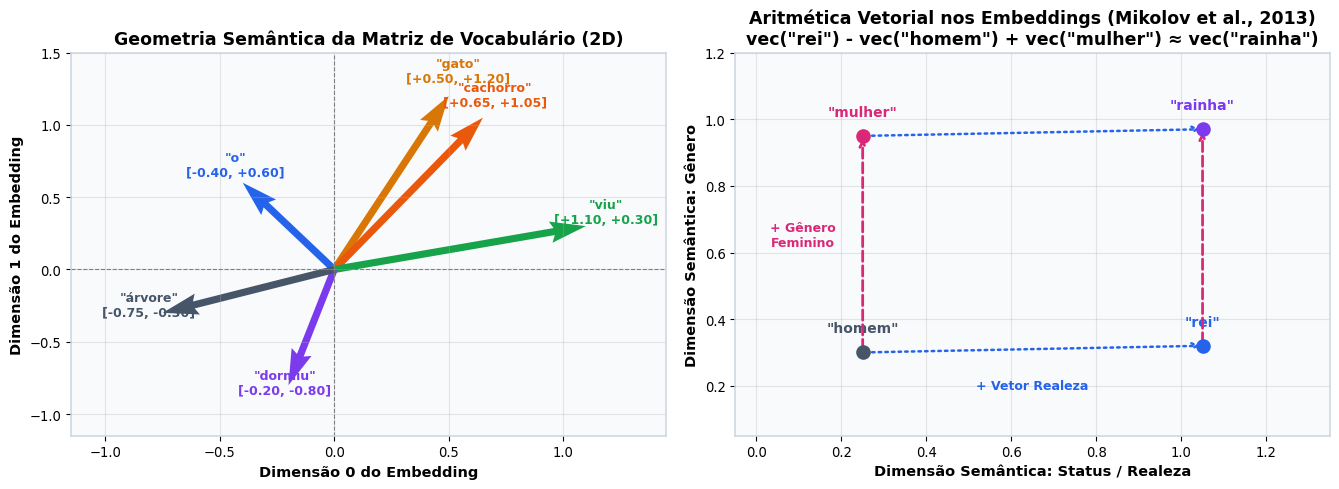

In [6]:
# ==============================================================================
# EXPERIMENTO 2.2.2: MATRIZ GLOBAL DO VOCABULÁRIO (W_embed) E CONSULTA INDEXADA
# ==============================================================================

rotulos_vocabulario = ['"o"', '"gato"', '"cachorro"', '"viu"', '"dormiu"', '"correr"', '"árvore"', '"..."']
valores_vocabulario = [
    [-0.40,  0.60],  # ID 0: "o" (artigo)
    [ 0.50,  1.20],  # ID 1: "gato" (animal felino)
    [ 0.65,  1.05],  # ID 2: "cachorro" (animal canino — próximo de "gato"!)
    [ 1.10,  0.30],  # ID 3: "viu" (verbo de percepção)
    [-0.20, -0.80],  # ID 4: "dormiu" (verbo de estado)
    [ 0.30, -0.70],  # ID 5: "correr" (verbo de ação)
    [-0.75, -0.30],  # ID 6: "árvore" (substantivo botânico)
    ["...",  "..."],
]

# Renderização em formato matricial elegante (HTML + Console)
largura_rot = max(len(r) for r in rotulos_vocabulario)
qtd_linhas_v = len(rotulos_vocabulario)

print("Matriz Global de Embeddings do Vocabulário (W_embed in R^{|V| x 2}):\n")
for i, (rotulo, val) in enumerate(zip(rotulos_vocabulario, valores_vocabulario)):
    val_str = "   ".join(f"{v:>5}" if isinstance(v, str) else f"{v:>+5.2f}" for v in val)
    c_esq = "┌" if i == 0 else ("└" if i == qtd_linhas_v - 1 else "│")
    c_dir = "┐" if i == 0 else ("┘" if i == qtd_linhas_v - 1 else "│")
    print(f"  {rotulo:>{largura_rot}}   {c_esq}  {val_str}  {c_dir}")

# Agora montamos a frase: "o gato viu o gato" consultando a matriz W_embed
tokens_frase_exemplo = ["o", "gato", "viu", "o", "gato"]
dicionario_embed_2d = {
    "o":        np.array([-0.40,  0.60]),
    "gato":     np.array([ 0.50,  1.20]),
    "cachorro": np.array([ 0.65,  1.05]),
    "viu":      np.array([ 1.10,  0.30]),
    "dormiu":   np.array([-0.20, -0.80]),
    "árvore":   np.array([-0.75, -0.30]),
}

embeddings_frase_2d = np.array([dicionario_embed_2d[t] for t in tokens_frase_exemplo])

linhas_lookup = []
cores_lookup = []
for pos_m, tok in enumerate(tokens_frase_exemplo):
    vet = embeddings_frase_2d[pos_m]
    norma = float(np.linalg.norm(vet))
    obs = "Mesmo vetor da pos 0!" if pos_m == 3 else ("Mesmo vetor da pos 1!" if pos_m == 4 else "Primeira ocorrência")
    linhas_lookup.append([f"m = {pos_m}", f'"{tok}"', f"{vet[0]:+.2f}", f"{vet[1]:+.2f}", f"{norma:.2f}", obs])
    cores_lookup.append("#EFF6FF" if tok == "o" else ("#FEF3C7" if tok == "gato" else "#F0FDF4"))

exibir_tabela_apostila(
    ["Posição (m)", "Token na Frase", "Dimensão 0 (x_0)", "Dimensão 1 (x_1)", "Norma ||e_m||", "Observação sobre Identidade Estática"],
    linhas_lookup,
    titulo_tabela='Tabela 2.2 — Resultado do Lookup de Embeddings para a Frase: "o gato viu o gato"',
    subtitulo="Sem informação de posição, o token 'gato' na posição 1 (sujeito) e na posição 4 (objeto) possuem exatamente o mesmo vetor!",
    cores_linhas=cores_lookup
)

# Visualização Geométrica 2D do Espaço Semântico do Vocabulário
fig, eixos = plt.subplots(1, 2, figsize=(13.5, 5.0))

# Painel 1: Vetores do vocabulário no plano 2D mostrando agrupamento semântico
cores_pal = {"o": "#2563EB", "gato": "#D97706", "cachorro": "#EA580C", "viu": "#16A34A", "dormiu": "#7C3AED", "árvore": "#475569"}
for pal, vet in dicionario_embed_2d.items():
    cor = cores_pal[pal]
    eixos[0].quiver(0, 0, vet[0], vet[1], angles="xy", scale_units="xy", scale=1, color=cor, width=0.012)
    eixos[0].text(vet[0] * 1.08, vet[1] * 1.08, f'"{pal}"\n[{vet[0]:+.2f}, {vet[1]:+.2f}]',
                  fontsize=9, fontweight="bold", color=cor, ha="center")

eixos[0].axhline(0, color="gray", linestyle="--", linewidth=0.8)
eixos[0].axvline(0, color="gray", linestyle="--", linewidth=0.8)
eixos[0].set_xlim(-1.15, 1.45)
eixos[0].set_ylim(-1.15, 1.50)
eixos[0].set_title("Geometria Semântica da Matriz de Vocabulário (2D)")
eixos[0].set_xlabel("Dimensão 0 do Embedding")
eixos[0].set_ylabel("Dimensão 1 do Embedding")
eixos[0].grid(True, alpha=0.3)

# Painel 2: Analogia Vetorial Clássica (Mikolov et al., 2013): rei - homem + mulher ≈ rainha
vet_homem  = np.array([0.25, 0.30])
vet_mulher = np.array([0.25, 0.95])
vet_rei    = np.array([1.05, 0.32])
vet_rainha = np.array([1.05, 0.97])
vet_analogia = vet_rei - vet_homem + vet_mulher

for nome_v, v_coord, cor_v in [
    ("homem", vet_homem, "#475569"),
    ("mulher", vet_mulher, "#DB2777"),
    ("rei", vet_rei, "#2563EB"),
    ("rainha", vet_rainha, "#7C3AED"),
]:
    eixos[1].scatter(v_coord[0], v_coord[1], s=90, color=cor_v, zorder=5)
    eixos[1].text(v_coord[0], v_coord[1] + 0.06, f'"{nome_v}"', fontsize=10, fontweight="bold", color=cor_v, ha="center")

# Desenha as setas de paralelogramo da relação de gênero e realeza
eixos[1].annotate("", xy=vet_mulher, xytext=vet_homem, arrowprops=dict(arrowstyle="->", lw=2, color="#DB2777", ls="--"))
eixos[1].annotate("", xy=vet_analogia, xytext=vet_rei, arrowprops=dict(arrowstyle="->", lw=2, color="#DB2777", ls="--"))
eixos[1].annotate("", xy=vet_rei, xytext=vet_homem, arrowprops=dict(arrowstyle="->", lw=1.8, color="#2563EB", ls=":"))
eixos[1].annotate("", xy=vet_rainha, xytext=vet_mulher, arrowprops=dict(arrowstyle="->", lw=1.8, color="#2563EB", ls=":"))
eixos[1].text(0.65, 0.19, "+ Vetor Realeza", color="#2563EB", fontweight="bold", fontsize=9, ha="center")
eixos[1].text(0.11, 0.62, "+ Gênero\nFeminino", color="#DB2777", fontweight="bold", fontsize=9, ha="center")

eixos[1].set_xlim(-0.05, 1.35)
eixos[1].set_ylim(0.05, 1.20)
eixos[1].set_title('Aritmética Vetorial nos Embeddings (Mikolov et al., 2013)\nvec("rei") - vec("homem") + vec("mulher") ≈ vec("rainha")')
eixos[1].set_xlabel("Dimensão Semântica: Status / Realeza")
eixos[1].set_ylabel("Dimensão Semântica: Gênero")
eixos[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---

### 2.2.3 Codificação de Posição (*Positional Encoding*): Da Senoidal Aditiva (VASWANI et al., 2017) ao *RoPE* (SU et al., 2024)

Observe atentamente a **Tabela 2.2** que acabamos de gerar e a prancha ilustrativa abaixo:

![Slide 1: O Problema dos Embeddings sem Posição](figuras_slides/slide_01_embeddings_sem_posicao.png)
**Figura 2.2** — Sem codificação posicional, tokens idênticos em posições diferentes da frase (`"o"` nas posições $0$ e $3$; `"gato"` nas posições $1$ e $4$) possuem exatamente os mesmos vetores e o mesmo ângulo ($59{,}5^\circ$), tornando o mecanismo de atenção invariante à permutação. *Fonte: Elaborado pelo autor.*

Como o *Transformer* não possui o laço sequencial $t-1 \rightarrow t$ das *LSTMs*, se trocarmos a ordem das palavras da frase, os vetores de *embedding* continuam idênticos! Precisamos, portanto, **injetar informação de posição** nos vetores. Mas qual é a melhor maneira matemática de fazer isso?

---

#### 🌊 Parte A: A Codificação Posicional Senoidal Intercalada (VASWANI et al., 2017)

No artigo original *"Attention Is All You Need"*, Vaswani et al. (2017) propuseram construir um vetor posicional $\vec{PE}_{(m)} \in \mathbb{R}^{d_{\text{model}}}$ para cada posição $m \in \{0, 1, 2, \dots\}$ intercalando funções **seno** (nas dimensões pares $2k$) e **cosseno** (nas dimensões ímpares $2k+1$) com frequências geométricas decrescentes $\omega_k$:

$$PE_{(m, 2k)} = \sin(m \cdot \omega_k), \qquad PE_{(m, 2k+1)} = \cos(m \cdot \omega_k), \qquad \text{onde } \omega_k = \frac{1}{10000^{2k / d_{\text{model}}}}$$

![Slide 2: Codificação Senoidal Intercalada](figuras_slides/slide_02_codificacao_senoidal_intercalada.png)
**Figura 2.3** — A codificação posicional senoidal intercalada `[sen, cos, sen, cos]` mapeia cada posição discreta $m$ para pontos sobre o círculo unitário em diferentes frequências $\omega_k$. *Fonte: Elaborado pelo autor, adaptado de VASWANI et al. (2017).*

### Por que intercalar $\sin$ e $\cos$? A Identidade Trigonométrica $\cos(A - B)$!

Quando calculamos o produto escalar entre dois vetores **puramente posicionais** nas posições $m$ (com ângulo $A = m\omega$) e $n$ (com ângulo $B = n\omega$), a identidade trigonométrica do cosseno da diferença entra em ação:

$$\vec{PE}_m \cdot \vec{PE}_n = \sin(A)\sin(B) + \cos(A)\cos(B) = \cos(A - B) = \cos\big((m - n)\omega\big)$$

Ou seja: o produto escalar entre dois vetores posicionais senoidais depende **exclusivamente da distância relativa $(m - n)$** entre as palavras, e não da posição absoluta!

![Slide 3: A Identidade Trigonométrica cos(A - B)](figuras_slides/slide_03_identidade_cos_A_menos_B.png)
**Figura 2.4** — Demonstração algébrica e matricial (Matriz de Toeplitz de diagonais constantes) mostrando que o produto escalar puro $\vec{PE}_m \cdot \vec{PE}_n$ captura perfeitamente a distância relativa $\Delta = m - n$. *Fonte: Elaborado pelo autor.*

---

#### ⚠️ Parte B: O Defeito da Soma ($E + PE$) — Os Termos Cruzados Destroem a Invariância Relativa!

> **Uma dúvida clássica dos alunos**:
> *"Professor, se $\vec{PE}_m \cdot \vec{PE}_n = \cos((m-n)\omega)$ depende só da distância relativa, por que as LLMs modernas (como LLaMA, Qwen, Mistral e Gemma) abandonaram a codificação senoidal de 2017 e migraram para o RoPE?"*

A resposta está na operação de **soma**! Vaswani et al. (2017) **somavam** o vetor de posição ao *embedding* da palavra ($\vec{x}_m = \vec{e}_m + \vec{PE}_m$). Quando dois tokens nas posições $m$ e $n$ interagem no produto escalar da atenção, a distributividade gera **quatro termos**:

$$(\vec{e}_m + \vec{PE}_m) \cdot (\vec{e}_n + \vec{PE}_n) = \underbrace{\vec{e}_m \cdot \vec{e}_n}_{\substack{\text{1. Semântica pura}\\\text{(constante)}}} + \underbrace{\vec{e}_m \cdot \vec{PE}_n + \vec{PE}_m \cdot \vec{e}_n}_{\substack{\text{2 e 3. TERMOS CRUZADOS!}\\\text{Dependem de } m \text{ e } n \text{ absolutos!}}} + \underbrace{\vec{PE}_m \cdot \vec{PE}_n}_{\substack{\text{4. Distância relativa}\\\cos((m-n)\omega)}}$$

Os **termos cruzados** ($\vec{e}_m \cdot \vec{PE}_n + \vec{PE}_m \cdot \vec{e}_n$) misturam o conteúdo semântico da palavra com o seno/cosseno da posição absoluta! Como consequência, o mesmo par `"o gato"` nas posições $(0, 1)$ passa a ter um ângulo e um produto escalar **diferentes** de `"o gato"` nas posições $(3, 4)$, mesmo ambos tendo distância relativa $\Delta = 1$!

![Slide 4: O Defeito dos Termos Cruzados na Soma E + PE](figuras_slides/slide_04_defeito_soma_termos_cruzados.png)
**Figura 2.5** — Ao somar $\vec{e}_m + \vec{PE}_m$, os vetores sofrem translação e os termos cruzados alteram o ângulo entre `"o"` e `"gato"` de $40{,}9^\circ$ (nas posições $0,1$) para $49{,}9^\circ$ (nas posições $3,4$). *Fonte: Elaborado pelo autor.*

---

#### 🔄 Parte C: A Solução Moderna do *RoPE* (*Rotary Position Embedding* — SU et al., 2024)

Proposto por Jianlin Su et al. (2024, originalmente em preprint de 2021 no artigo *RoFormer*), o **RoPE (*Rotary Position Embedding*)** resolve esse problema pela raiz: **em vez de somar um vetor posicional ao *embedding*, nós rotacionamos o vetor $(q, k)$ por um ângulo proporcional à sua posição $m\theta$** usando uma matriz ortogonal de rotação 2D $R(m\theta)$:

$$\vec{x}_m^{\text{RoPE}} = R(m\theta) \vec{e}_m = \begin{bmatrix} \cos(m\theta) & -\sin(m\theta) \\ \sin(m\theta) & \cos(m\theta) \end{bmatrix} \begin{bmatrix} e_{m, 0} \\ e_{m, 1} \end{bmatrix}$$

Por que isso é matematicamente perfeito? Porque a transposta de uma matriz de rotação é a rotação inversa ($R(m\theta)^\top = R(-m\theta)$), e o produto de duas rotações soma os ângulos:

$$\left(R(m\theta)\vec{e}_m\right)^\top \left(R(n\theta)\vec{e}_n\right) = \vec{e}_m^\top R(-m\theta) R(n\theta) \vec{e}_n = \vec{e}_m^\top R\big((n - m)\theta\big) \vec{e}_n$$

**Zero termos cruzados!** A norma dos vetores permanece 100% intacta ($\|R(m\theta)\vec{e}\| = \|\vec{e}\|$) e o produto escalar depende **exclusivamente** da semântica das palavras e da distância relativa $(n - m)$!

![Slide 5: A Solução Geométrica do RoPE](figuras_slides/slide_05_rope_rotacao_2d_constante.png)
**Figura 2.6** — No *RoPE* (SU et al., 2024), ambos os vetores `"o"` e `"gato"` giram rigidamente no plano. O ângulo relativo entre eles permanece cravado em $88{,}1^\circ$ e o produto escalar em $+0{,}0446$ em qualquer posição da frase! *Fonte: Elaborado pelo autor.*

![Slide 6: Confronto Final Senoidal vs RoPE](figuras_slides/slide_06_comparacao_final_senoidal_vs_rope.png)
**Figura 2.7** — Confronto direto deslizando o par `("o", "gato")` ao longo de 15 posições da frase: a soma senoidal oscila caoticamente, enquanto o *RoPE* mantém estabilidade horizontal absoluta. *Fonte: Elaborado pelo autor.*

> 📺 **Vídeo e Artigo Recomendados sobre RoPE**:
> - **Artigo Original (RoFormer)**: SU, Jianlin et al. *RoFormer: Enhanced Transformer with Rotary Position Embedding* (Neurocomputing, 2024 / arXiv:2104.09864): <https://arxiv.org/abs/2104.09864>
> - **Vídeo Explicativo (YouTube)**: *Rotary Positional Encodings (RoPE) Explained Visually*: <https://www.youtube.com/watch?v=a17DlNxkv2k>

Vamos agora executar em código Python a verificação numérica exata comparando **Sem Posição**, **Senoidal Aditiva ($E + PE$)** e **RoPE ($R(m\theta)E$)**!

In [7]:
# ==============================================================================
# EXPERIMENTO 2.2.3: COMPARAÇÃO NUMÉRICA EXATA — SOMA SENOIDAL VS. ROPE (2D)
# ==============================================================================

omega_pos = 0.50  # Frequência angular didática (rad/posição)

def gerar_pe_senoidal_2d(pos_m, omega=omega_pos):
    return np.array([math.sin(pos_m * omega), math.cos(pos_m * omega)])

def aplicar_rotacao_rope_2d(vetor_2d, pos_m, omega=omega_pos):
    ang = pos_m * omega
    c, s = math.cos(ang), math.sin(ang)
    matriz_rot = np.array([[c, -s], [s, c]])
    return matriz_rot @ vetor_2d

def metricas_par(u, v):
    prod_esc = float(np.dot(u, v))
    cos_sim = prod_esc / ( float(np.linalg.norm(u)) * float(np.linalg.norm(v)) )
    cos_sim = max(-1.0, min(1.0, cos_sim))
    ang_graus = math.degrees(math.acos(cos_sim))
    return ang_graus, cos_sim, prod_escalar if False else prod_esc

vetor_o = dicionario_embed_2d["o"]
vetor_gato = dicionario_embed_2d["gato"]

# Decomposição explícita dos 4 termos da soma (e_m + PE_m) . (e_n + PE_n) para (0,1) vs (3,4)
linhas_comparacao_pos = []
for nome_metodo in ["1. Sem Posição (Puro)", "2. Senoidal Aditiva (E + PE)", "3. RoPE Rotacional (R(mθ)·E)"]:
    res_pares = []
    for m_pos, n_pos in [(0, 1), (3, 4), (9, 10)]:
        if nome_metodo.startswith("1"):
            u, v = vetor_o, vetor_gato
        elif nome_metodo.startswith("2"):
            u = vetor_o + gerar_pe_senoidal_2d(m_pos)
            v = vetor_gato + gerar_pe_senoidal_2d(n_pos)
        else:
            u = aplicar_rotacao_rope_2d(vetor_o, m_pos)
            v = aplicar_rotacao_rope_2d(vetor_gato, n_pos)
        ang_g, _, p_esc = metricas_par(u, v)
        res_pares.append((ang_g, p_esc))

    variacao_dot = max(r[1] for r in res_pares) - min(r[1] for r in res_pares)
    status = "Invariante (mas cego à distância!)" if nome_metodo.startswith("1") else (
        "FALHA: Varia com a posição absoluta!" if nome_metodo.startswith("2") else "PERFEITO: 100% constante para Δ=1!"
    )
    linhas_comparacao_pos.append([
        nome_metodo,
        f"{res_pares[0][1]:+.4f} ({res_pares[0][0]:.1f}°)",
        f"{res_pares[1][1]:+.4f} ({res_pares[1][0]:.1f}°)",
        f"{res_pares[2][1]:+.4f} ({res_pares[2][0]:.1f}°)",
        f"{variacao_dot:.4f}",
        status
    ])

exibir_tabela_apostila(
    ["Método Posicional", 'Par ("o","gato") em (0,1)', 'Par ("o","gato") em (3,4)', 'Par ("o","gato") em (9,10)', "Desvio Máx.", "Diagnóstico Matemático"],
    linhas_comparacao_pos,
    titulo_tabela='Tabela 2.3 — Produto Escalar e Ângulo entre "o" e "gato" (Distância Relativa Δ = 1) em Diferentes Posições',
    subtitulo="Prova numérica de como os termos cruzados de (E + PE) distorcem o escore, enquanto o RoPE preserva invariância exata.",
    cores_linhas=["#F8FAFC", "#FEE2E2", "#DCFCE7"]
)


Tabela 2.3 — Produto Escalar e Ângulo entre "o" e "gato" (Distância Relativa Δ = 1) em Diferentes Posições
  Prova numérica de como os termos cruzados de (E + PE) distorcem o escore, enquanto o RoPE preserva invariância exata.
+------------------------------+---------------------------+---------------------------+----------------------------+-------------+--------------------------------------+
|      Método Posicional       | Par ("o","gato") em (0,1) | Par ("o","gato") em (3,4) | Par ("o","gato") em (9,10) | Desvio Máx. |        Diagnóstico Matemático        |
+------------------------------+---------------------------+---------------------------+----------------------------+-------------+--------------------------------------+
|    1. Sem Posição (Puro)     |      +0.5200 (56.3°)      |      +0.5200 (56.3°)      |      +0.5200 (56.3°)       |    0.0000   |  Invariante (mas cego à distância!)  |
| 2. Senoidal Aditiva (E + PE) |      +2.9324 (39.3°)      |      +1.3678 (19.2°)      |

Método Posicional,"Par (""o"",""gato"") em (0,1)","Par (""o"",""gato"") em (3,4)","Par (""o"",""gato"") em (9,10)",Desvio Máx.,Diagnóstico Matemático
1. Sem Posição (Puro),+0.5200 (56.3°),+0.5200 (56.3°),+0.5200 (56.3°),0.0000,Invariante (mas cego à distância!)
2. Senoidal Aditiva (E + PE),+2.9324 (39.3°),+1.3678 (19.2°),+1.2096 (57.0°),1.7227,FALHA: Varia com a posição absoluta!
3. RoPE Rotacional (R(mθ)·E),+0.8303 (27.7°),+0.8303 (27.7°),+0.8303 (27.7°),0.0000,PERFEITO: 100% constante para Δ=1!


---

### 2.2.4 Mecanismo Atencional: Cabeça Única (*Single-Head Scaled Dot-Product Attention*)

Agora que cada *token* possui seu vetor semântico de *embedding* e sua geometria posicional (*RoPE*), chegamos ao coração do *Transformer*: como uma palavra na posição $m$ conversa com as outras palavras da frase para resolver ambiguidades e absorver contexto?

> 📺 **Vídeo Obrigatório de Referência Visual (3Blue1Brown)**:
> - **3Blue1Brown (Grant Sanderson)** — *Attention in transformers, step-by-step | Deep Learning Chapter 6*: <https://www.youtube.com/watch?v=eMlx5fFNoYc> *(Demonstração visual completa de como Queries, Keys e Values permitem que adjetivos atualizem substantivos e pronomes encontrem seus referentes!)*

#### 🔑 A Metáfora de Recuperação de Informação: Consulta (*Query*), Chave (*Key*) e Valor (*Value*)

Se simplesmente multiplicássemos os *embeddings* originais $\vec{x}_m \cdot \vec{x}_n$, uma palavra teria escore máximo consigo mesma e não conseguiria fazer perguntas assimétricas (ex.: um pronome `"ele"` precisa buscar um substantivo masculino singular como `"gato"` ou `"rato"`, e não outro pronome `"ele"`!).

Por isso, conforme formulado por Vaswani et al. (2017), para cada *token* projetamos seu vetor de entrada $X \in \mathbb{R}^{T \times d_{\text{model}}}$ por **três matrizes de pesos aprendíveis distintas** ($W_Q, W_K \in \mathbb{R}^{d_{\text{model}} \times d_k}$ e $W_V \in \mathbb{R}^{d_{\text{model}} \times d_v}$):

$$Q = X W_Q \quad (\text{Consultas / Queries}), \qquad K = X W_K \quad (\text{Chaves / Keys}), \qquad V = X W_V \quad (\text{Valores / Values})$$

- **Consulta (*Query* — $\vec{q}_m$)**: Representa *"O que o token na posição $m$ está procurando no contexto?"* (ex.: o verbo `"viu"` pergunta: *"Quem praticou a ação de ver?"*);
- **Chave (*Key* — $\vec{k}_n$)**: Representa o *"Crachá / Etiqueta de anúncio"* do token na posição $n$ dizendo quais perguntas ele pode responder (ex.: `"gato"` anuncia: *"Sou um substantivo animado que pode atuar como sujeito"*);
- **Valor (*Value* — $\vec{v}_n$)**: Representa o *"Conteúdo semântico efetivo"* que o token $n$ entregará caso seja atendido.

![Diagrama Original Scaled Dot-Product Attention e Vetores QKV](figuras_apostila/vaswani_2017_fig2.png)
**Figura 2.8** — Fluxograma original da Atenção por Produto Escalar Escalado (*Scaled Dot-Product Attention*): multiplicação matricial $Q K^\top$, escalonamento por $1/\sqrt{d_k}$, aplicação opcional da máscara causal, *Softmax* e multiplicação pela matriz de valores $V$. *Fonte: VASWANI et al. (2017, p. 4).*

![Projeções Q, K e V Ilustradas](figuras_apostila/alammar_qkv.png)
**Figura 2.9** — Criação dos vetores *Query* ($q$), *Key* ($k$) e *Value* ($v$) a partir da multiplicação dos *embeddings* de entrada $X$ pelas matrizes treináveis $W^Q, W^K, W^V$. *Fonte: ALAMMAR (2018).*

#### 📐 A Equação Completa de Vaswani et al. (2017)

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{Q K^\top + M}{\sqrt{d_k}}\right) V$$

Vamos dissecar o papel de cada operação:
1. **Similaridade Consulta-Chave ($Q K^\top \in \mathbb{R}^{T \times T}$)**: Mede a afinidade direcional entre cada consulta $\vec{q}_m$ e cada chave $\vec{k}_n$;
2. **Por que dividimos por $\sqrt{d_k}$?**: Se as componentes de $\vec{q}$ e $\vec{k}$ forem variáveis aleatórias independentes com média $0$ e variância $1$, a soma de $d_k$ produtos $\sum_{i=1}^{d_k} q_i k_i$ terá média $0$ e **variância igual a $d_k$** (desvio padrão $\sqrt{d_k}$). Quando $d_k$ é grande (ex.: $d_k = 64$ ou $128$), os produtos escalares assumem valores extremos (como $+25$ ou $-25$), empurrando a função *Softmax* para regiões saturadas onde um único token recebe probabilidade $\approx 1{,}0000$ e **todos os gradientes zeram**! Dividir por $\sqrt{d_k}$ restaura a variância exatamente para $1$ (VASWANI et al., 2017, p. 4);
3. **Máscara Causal ($M \in \{0, -\infty\}^{T \times T}$)**: Em modelos geradores autorregressivos (*Decoder-only*), somamos $-\infty$ nas posições futuras ($n > m$). Como $e^{-\infty} = 0$, o *Softmax* zera qualquer vazamento de informação do futuro;
4. **Combinação Convexa pelos Valores ($\text{Pesos} \times V$)**: Cada linha da matriz após o *Softmax* soma $1{,}00$ e funciona como uma receita de mistura que agrega os vetores de Valor ($\vec{v}_n$) relevantes.


Tabela 2.4 — Matriz de Pesos de Auto-Atenção Causal (Após Escalonamento por √d_k e Softmax)
  Cada linha soma 1.00. Posições futuras (acima da diagonal principal) recebem peso zero graças à máscara causal.
+--------------------+---------+--------------+---------------+--------------+--------------+--------------+------------+
| Query (Quem busca) | Key "O" |  Key "gato"  | Key "faminto" | Key "comeu"  |   Key "o"    | Key "peixe"  | Maior Foco |
+--------------------+---------+--------------+---------------+--------------+--------------+--------------+------------+
|    "O" (pos 0)     |   1.00  | 0.00 (Masc.) |  0.00 (Masc.) | 0.00 (Masc.) | 0.00 (Masc.) | 0.00 (Masc.) |    "O"     |
|   "gato" (pos 1)   |   0.15  |     0.85     |  0.00 (Masc.) | 0.00 (Masc.) | 0.00 (Masc.) | 0.00 (Masc.) |   "gato"   |
| "faminto" (pos 2)  |   0.03  |     0.26     |      0.72     | 0.00 (Masc.) | 0.00 (Masc.) | 0.00 (Masc.) | "faminto"  |
|  "comeu" (pos 3)   |   0.00  |     0.03     |      0.15    

Query (Quem busca),"Key ""O""","Key ""gato""","Key ""faminto""","Key ""comeu""","Key ""o""","Key ""peixe""",Maior Foco
"""O"" (pos 0)",1.00,0.00 (Masc.),0.00 (Masc.),0.00 (Masc.),0.00 (Masc.),0.00 (Masc.),"""O"""
"""gato"" (pos 1)",0.15,0.85,0.00 (Masc.),0.00 (Masc.),0.00 (Masc.),0.00 (Masc.),"""gato"""
"""faminto"" (pos 2)",0.03,0.26,0.72,0.00 (Masc.),0.00 (Masc.),0.00 (Masc.),"""faminto"""
"""comeu"" (pos 3)",0.00,0.03,0.15,0.81,0.00 (Masc.),0.00 (Masc.),"""comeu"""
"""o"" (pos 4)",0.21,0.17,0.18,0.21,0.22,0.00 (Masc.),"""o"""
"""peixe"" (pos 5)",0.02,0.04,0.13,0.52,0.02,0.27,"""comeu"""


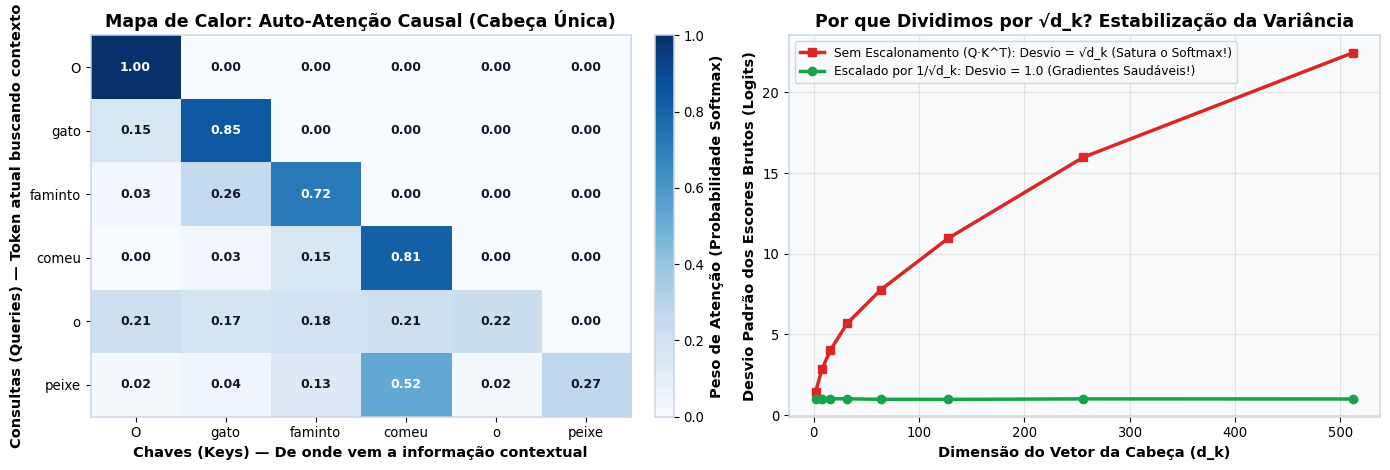

In [8]:
# ==============================================================================
# EXPERIMENTO 2.2.4: CABEÇA ÚNICA DE ATENÇÃO PASSO A PASSO E EFEITO DE sqrt(d_k)
# ==============================================================================

torch.manual_seed(SEMENTE)

tokens_atencao_unica = ["O", "gato", "faminto", "comeu", "o", "peixe"]
qtd_tok_u = len(tokens_atencao_unica)
dim_modelo_u = 4
dim_k_u = 4

# Embeddings didáticos (6 tokens x 4 dimensões: [Artigo, Animal/Sujeito, Estado/Ação, Alimento/Objeto])
X_unico = torch.tensor([
    [1.0, 0.1, 0.0, 0.0],  # "O"
    [0.1, 1.4, 0.2, 0.0],  # "gato"
    [0.0, 0.9, 1.2, 0.2],  # "faminto"
    [0.0, 0.8, 1.5, 0.9],  # "comeu"
    [1.0, 0.0, 0.0, 0.2],  # "o"
    [0.0, 0.2, 0.4, 1.5],  # "peixe"
], dtype=torch.float32)

# Matrizes de projeção W_Q, W_K, W_V
W_Q_u = torch.tensor([
    [0.8, 0.0, 0.0, 0.0],
    [0.0, 1.1, 0.4, 0.0],
    [0.0, 0.6, 1.2, 0.5],
    [0.0, 0.0, 0.5, 1.2],
], dtype=torch.float32)

W_K_u = torch.tensor([
    [0.8, 0.0, 0.0, 0.0],
    [0.0, 1.2, 0.5, 0.0],
    [0.0, 0.5, 1.1, 0.3],
    [0.0, 0.0, 0.4, 1.3],
], dtype=torch.float32)

W_V_u = torch.eye(dim_modelo_u)

Q_u = X_unico @ W_Q_u
K_u = X_unico @ W_K_u
V_u = X_unico @ W_V_u

# Escores escalados por sqrt(d_k) + Máscara Causal Triangular Inferior
escores_qk = (Q_u @ K_u.T) / math.sqrt(dim_k_u)
mascara_causal_u = torch.triu(torch.full((qtd_tok_u, qtd_tok_u), float("-inf")), diagonal=1)
escores_mascarados_u = escores_qk + mascara_causal_u
pesos_atencao_u = F.softmax(escores_mascarados_u, dim=-1)
saida_atencao_u = pesos_atencao_u @ V_u

# Tabela HTML dos Pesos de Atenção Causais
linhas_tab_atencao = []
for i_q, tok_q in enumerate(tokens_atencao_unica):
    valores_linha = [f"{ float(pesos_atencao_u[i_q, j_k]):.2f}" if j_k <= i_q else "0.00 (Masc.)" for j_k in range(qtd_tok_u)]
    foco_principal_idx = int(torch.argmax(pesos_atencao_u[i_q, :i_q+1]))
    linhas_tab_atencao.append([f'"{tok_q}" (pos {i_q})'] + valores_linha + [f'"{tokens_atencao_unica[foco_principal_idx]}"'])

exibir_tabela_apostila(
    ["Query (Quem busca)"] + [f'Key "{t}"' for t in tokens_atencao_unica] + ["Maior Foco"],
    linhas_tab_atencao,
    titulo_tabela="Tabela 2.4 — Matriz de Pesos de Auto-Atenção Causal (Após Escalonamento por √d_k e Softmax)",
    subtitulo="Cada linha soma 1.00. Posições futuras (acima da diagonal principal) recebem peso zero graças à máscara causal."
)

# Visualização Dupla:
# Painel 1: Mapa de Calor de Atenção da Cabeça Única
# Painel 2: Demonstração estatística de por que dividimos por sqrt(d_k) (Variância do Produto Escalar)
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.8))

desenhar_mapa_calor(
    pesos_atencao_u.numpy(),
    rotulos_x=tokens_atencao_unica,
    rotulos_y=tokens_atencao_unica,
    eixo=eixos[0],
    cmap="Blues",
    formato=".2f",
    rotulo_barra="Peso de Atenção (Probabilidade Softmax)",
)
eixos[0].set_title("Mapa de Calor: Auto-Atenção Causal (Cabeça Única)")
eixos[0].set_xlabel("Chaves (Keys) — De onde vem a informação contextual")
eixos[0].set_ylabel("Consultas (Queries) — Token atual buscando contexto")

# Experimento Monte Carlo: Desvio padrão de q . k conforme d_k cresce de 2 até 512
dimensoes_dk = [2, 8, 16, 32, 64, 128, 256, 512]
desvios_sem_escala = []
desvios_com_escala = []
for dk_teste in dimensoes_dk:
    q_amostra = np.random.randn(2000, dk_teste)
    k_amostra = np.random.randn(2000, dk_teste)
    prod_amostras = np.sum(q_amostra * k_amostra, axis=1)
    desvios_sem_escala.append(np.std(prod_amostras))
    desvios_com_escala.append(np.std(prod_amostras / math.sqrt(dk_teste)))

eixos[1].plot(dimensoes_dk, desvios_sem_escala, marker="s", linewidth=2.5, color="#DC2626",
              label="Sem Escalonamento (Q·K^T): Desvio = √d_k (Satura o Softmax!)")
eixos[1].plot(dimensoes_dk, desvios_com_escala, marker="o", linewidth=2.5, color="#16A34A",
              label="Escalado por 1/√d_k: Desvio = 1.0 (Gradientes Saudáveis!)")
eixos[1].set_title("Por que Dividimos por √d_k? Estabilização da Variância")
eixos[1].set_xlabel("Dimensão do Vetor da Cabeça (d_k)")
eixos[1].set_ylabel("Desvio Padrão dos Escores Brutos (Logits)")
eixos[1].legend(loc="upper left", fontsize=8.8)
eixos[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---

### 2.2.5 Atenção de Múltiplas Cabeças (*Multi-Head Attention*): Divisão de Tarefas, Múltiplos Focos e Integração via $W_O$

> **Uma dúvida clássica dos alunos**:
> *"Professor, se uma única cabeça de atenção já calcula uma média ponderada entre todas as palavras da frase, por que precisamos dividir o modelo em 8, 16 ou 32 cabeças de atenção diferentes?"*

Pense na seguinte frase:
> ***"O gato viu o rato porque ele estava faminto."***

Quando o modelo processa o pronome ***"ele"*** (ou o verbo ***"estava"***), existe **mais de um tipo de pergunta linguística** que precisa ser respondida **ao mesmo tempo**:
1. **Foco de Resolução de Correferência (Semântico)**: *"A quem o pronome 'ele' se refere? Ao 'gato' (que viu) ou ao 'rato'?"*;
2. **Foco Sintático / Gramatical**: *"Qual é o verbo principal da oração anterior ('viu') e qual é a conjunção causal ('porque') que conecta as duas orações?"*;
3. **Foco Posicional / Adjacência Local**: *"Quais são as palavras imediatamente vizinhas ao redor desta posição?"*.

Se tivermos **apenas uma cabeça de atenção**, um único *Softmax* terá que misturar todas essas relações diferentes em um único vetor médio, borrando as distinções!

#### 🧩 Como Funciona a Divisão de Tarefas e a Integração Final (VASWANI et al., 2017; VOITA et al., 2019; CLARK et al., 2019)

Na **Atenção de Múltiplas Cabeças (*Multi-Head Attention*)**, dividimos a dimensão total $d_{\text{model}}$ em $h$ subespaços independentes de dimensão menor $d_k = d_v = d_{\text{model}} / h$. Cada cabeça $i \in \{1, \dots, h\}$ possui seu próprio trio de matrizes $(W_Q^{(i)}, W_K^{(i)}, W_V^{(i)})$ e calcula sua distribuição de atenção separadamente:

$$\text{head}_i = \text{Attention}\left(X W_Q^{(i)}, \; X W_K^{(i)}, \; X W_V^{(i)}\right) \in \mathbb{R}^{T \times d_v}$$

Em seguida, os vetores extraídos pelas $h$ cabeças especializadas são **concatenados lado a lado** ($\text{Concat} \in \mathbb{R}^{T \times (h \cdot d_v)}$) e multiplicados por uma **matriz de projeção de saída $W_O \in \mathbb{R}^{(h \cdot d_v) \times d_{\text{model}}}$**, que **integra e sintetiza todas as perspectivas extraídas pelas diferentes cabeças em um único vetor unificado por *token***:

$$\text{MultiHead}(Q, K, V) = \text{Concat}\left(\text{head}_1, \text{head}_2, \dots, \text{head}_h\right) W_O$$

![Diagrama Original Multi-Head Attention - Vaswani et al. 2017](figuras_apostila/vaswani_2017_fig3.png)
**Figura 2.10** — Arquitetura original da *Multi-Head Attention* mostrando as $h$ projeções lineares paralelas de $V, K, Q$, o cálculo independente da atenção em cada subespaço, a concatenação (`Concat`) e a projeção linear integradora final (`Linear` $W_O$). *Fonte: VASWANI et al. (2017, p. 4).*

![Pipeline Completo Multi-Head Attention Ilustrado](figuras_apostila/alammar_multihead.png)
**Figura 2.11** — Visão matricial completa da divisão em múltiplas cabeças ($Z_0, Z_1, \dots, Z_7$), concatenação das saídas parciais e multiplicação pela matriz integradora $W^O$ para produzir o tensor unificado $Z$. *Fonte: ALAMMAR (2018).*

Estudos de interpretabilidade em modelos reais (VOITA et al., 2019; CLARK et al., 2019; OLSSON et al., 2022) comprovaram empiricamente essa especialização espontânea: durante o treinamento, emergem cabeças sintáticas (sujeito-verbo), cabeças de correferência pronominal, cabeças posicionais (token anterior/seguinte) e *Induction Heads* (cabeças indutivas capazes de copiar padrões no contexto).

Vamos simular e visualizar exatamente essa divisão de trabalho entre **3 cabeças especializadas** e sua integração final via $W_O$!


Tabela 2.5 — Divisão de Tarefas entre Cabeças e Integração Final na Frase: "O gato viu o rato porque ele [estava] faminto"
  Repare no token 'ele' (pos 6): a Cabeça 1 olha para o verbo 'viu', a Cabeça 2 liga 'ele' ao referente 'gato', e a Cabeça 3 olha para 'porque'!
+-------------------+----------------------+--------------------------+-----------------------------+--------------------------------+
|  Token Analisado  | Cabeça 1 (Sintática) | Cabeça 2 (Correferência) | Cabeça 3 (Vizinhança Local) | Vetor Integrado (Concat · W_O) |
+-------------------+----------------------+--------------------------+-----------------------------+--------------------------------+
|   "viu" (pos 2)   | "gato" [0.72, 0.33]  |    "viu" [0.69, 0.47]    |     "gato" [0.32, 0.54]     |    [0.96, 0.69, 0.94, ...]     |
|   "rato" (pos 4)  |  "viu" [0.39, 0.54]  |   "rato" [0.52, 0.65]    |       "o" [0.46, 0.30]      |    [0.70, 0.81, 0.79, ...]     |
|   "ele" (pos 6)   |  "viu" [0.40, 0.52]  |   "gato" [0

Token Analisado,Cabeça 1 (Sintática),Cabeça 2 (Correferência),Cabeça 3 (Vizinhança Local),Vetor Integrado (Concat · W_O)
"""viu"" (pos 2)","""gato"" [0.72, 0.33]","""viu"" [0.69, 0.47]","""gato"" [0.32, 0.54]","[0.96, 0.69, 0.94, ...]"
"""rato"" (pos 4)","""viu"" [0.39, 0.54]","""rato"" [0.52, 0.65]","""o"" [0.46, 0.30]","[0.70, 0.81, 0.79, ...]"
"""ele"" (pos 6)","""viu"" [0.40, 0.52]","""gato"" [0.95, 0.71]","""porque"" [0.56, 0.42]","[0.81, 0.89, 1.20, ...]"
"""faminto"" (pos 7)","""ele"" [0.40, 0.32]","""gato"" [0.93, 0.68]","""ele"" [0.46, 0.56]","[0.78, 0.72, 1.16, ...]"


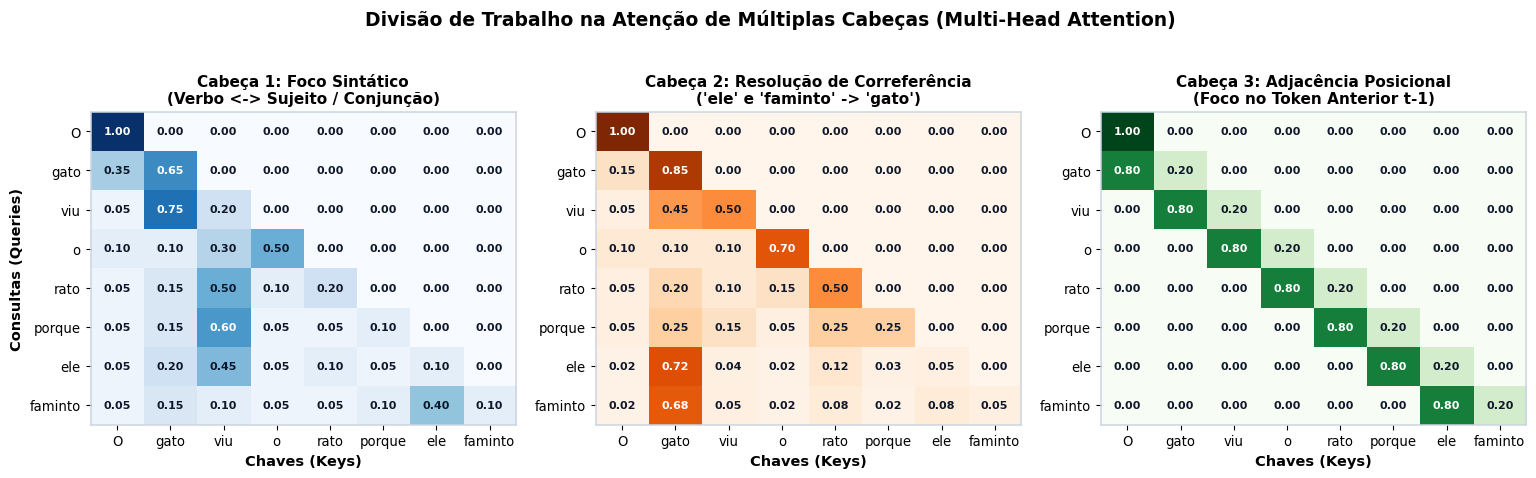

In [9]:
# ==============================================================================
# EXPERIMENTO 2.2.5: ESPECIALIZAÇÃO ENTRE CABEÇAS E INTEGRAÇÃO VIA MATRIZ W_O
# ==============================================================================

tokens_mha = ["O", "gato", "viu", "o", "rato", "porque", "ele", "faminto"]
qtd_t_mha = len(tokens_mha)
qtd_cabecas_mha = 3
dim_por_cabeca_mha = 2
dim_modelo_mha = qtd_cabecas_mha * dim_por_cabeca_mha  # 6 dimensões no total

# Construímos 3 matrizes de atenção especializadas (causais) representando os 3 focos clássicos
# identificados por Voita et al. (2019) e Clark et al. (2019):

# Cabeça 1: Foco Sintático (Verbos buscam seus Sujeitos; Conjunções buscam o Verbo Principal)
pesos_cabeca_1_sintatica = np.array([
    [1.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00],  # "O"
    [0.35, 0.65, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00],  # "gato" -> "O", "gato"
    [0.05, 0.75, 0.20, 0.00, 0.00, 0.00, 0.00, 0.00],  # "viu" -> foca forte no sujeito "gato" (0.75)!
    [0.10, 0.10, 0.30, 0.50, 0.00, 0.00, 0.00, 0.00],  # "o"
    [0.05, 0.15, 0.50, 0.10, 0.20, 0.00, 0.00, 0.00],  # "rato" -> conecta-se ao verbo "viu" (0.50)
    [0.05, 0.15, 0.60, 0.05, 0.05, 0.10, 0.00, 0.00],  # "porque" -> conecta-se à ação "viu" (0.60)
    [0.05, 0.20, 0.45, 0.05, 0.10, 0.05, 0.10, 0.00],  # "ele" -> olha estrutura verbal
    [0.05, 0.15, 0.10, 0.05, 0.05, 0.10, 0.40, 0.10],  # "faminto" -> predicativo ligado a "ele" (0.40)
])

# Cabeça 2: Foco Semântico / Correferência Pronominal ("ele" e "faminto" resolvem quem é o agente)
pesos_cabeca_2_correferencia = np.array([
    [1.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00],
    [0.15, 0.85, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00],
    [0.05, 0.45, 0.50, 0.00, 0.00, 0.00, 0.00, 0.00],
    [0.10, 0.10, 0.10, 0.70, 0.00, 0.00, 0.00, 0.00],
    [0.05, 0.20, 0.10, 0.15, 0.50, 0.00, 0.00, 0.00],
    [0.05, 0.25, 0.15, 0.05, 0.25, 0.25, 0.00, 0.00],
    [0.02, 0.72, 0.04, 0.02, 0.12, 0.03, 0.05, 0.00],  # "ele" -> resolve correferência em "gato" (0.72)!
    [0.02, 0.68, 0.05, 0.02, 0.08, 0.02, 0.08, 0.05],  # "faminto" -> associa fome a "gato" (0.68)!
])

# Cabeça 3: Foco Posicional / Adjacência Local (Olha para o token imediatamente anterior t-1)
pesos_cabeca_3_local = np.zeros((qtd_t_mha, qtd_t_mha))
for i_l in range(qtd_t_mha):
    if i_l == 0:
        pesos_cabeca_3_local[i_l, 0] = 1.00
    else:
        pesos_cabeca_3_local[i_l, i_l - 1] = 0.80
        pesos_cabeca_3_local[i_l, i_l] = 0.20

# Valores V por cabeça (cada cabeça extrai 2 dimensões específicas de informação)
V_cab1 = np.array([[0.1, 0.0], [0.9, 0.2], [0.2, 0.9], [0.1, 0.0], [0.7, 0.3], [0.1, 0.6], [0.4, 0.1], [0.3, 0.8]])
V_cab2 = np.array([[0.0, 0.1], [1.2, 0.8], [0.3, 0.2], [0.0, 0.1], [0.5, 0.9], [0.1, 0.1], [0.2, 0.2], [0.9, 0.7]])
V_cab3 = np.array([[0.5, 0.1], [0.2, 0.6], [0.8, 0.3], [0.5, 0.2], [0.3, 0.7], [0.6, 0.4], [0.4, 0.5], [0.7, 0.8]])

saida_cab1 = pesos_cabeca_1_sintatica @ V_cab1       # (8, 2)
saida_cab2 = pesos_cabeca_2_correferencia @ V_cab2   # (8, 2)
saida_cab3 = pesos_cabeca_3_local @ V_cab3           # (8, 2)

# Concatenação das 3 cabeças: (8, 2) + (8, 2) + (8, 2) -> (8, 6)
concatenado_mha = np.concatenate([saida_cab1, saida_cab2, saida_cab3], axis=-1)

# Matriz de Projeção de Saída W_O (6 x 6) que integra e mistura as informações das 3 cabeças
np.random.seed(SEMENTE)
W_O_integracao = np.eye(dim_modelo_mha) * 0.7 + np.full((dim_modelo_mha, dim_modelo_mha), 0.15)
vetor_integrado_final = concatenado_mha @ W_O_integracao

# Tabela demonstrando a divisão de tarefas e a integração para tokens selecionados
linhas_tab_mha = []
for idx_tok in [2, 4, 6, 7]:
    tok_nome = tokens_mha[idx_tok]
    foco1 = tokens_mha[int(np.argmax(pesos_cabeca_1_sintatica[idx_tok]))]
    foco2 = tokens_mha[int(np.argmax(pesos_cabeca_2_correferencia[idx_tok]))]
    foco3 = tokens_mha[int(np.argmax(pesos_cabeca_3_local[idx_tok]))]
    vet_c1 = f"[{saida_cab1[idx_tok, 0]:.2f}, {saida_cab1[idx_tok, 1]:.2f}]"
    vet_c2 = f"[{saida_cab2[idx_tok, 0]:.2f}, {saida_cab2[idx_tok, 1]:.2f}]"
    vet_c3 = f"[{saida_cab3[idx_tok, 0]:.2f}, {saida_cab3[idx_tok, 1]:.2f}]"
    vet_fim = "[" + ", ".join(f"{v:.2f}" for v in vetor_integrado_final[idx_tok, :3]) + ", ...]"
    linhas_tab_mha.append([f'"{tok_nome}" (pos {idx_tok})', f'"{foco1}" {vet_c1}', f'"{foco2}" {vet_c2}', f'"{foco3}" {vet_c3}', vet_fim])

exibir_tabela_apostila(
    ["Token Analisado", "Cabeça 1 (Sintática)", "Cabeça 2 (Correferência)", "Cabeça 3 (Vizinhança Local)", "Vetor Integrado (Concat · W_O)"],
    linhas_tab_mha,
    titulo_tabela='Tabela 2.5 — Divisão de Tarefas entre Cabeças e Integração Final na Frase: "O gato viu o rato porque ele [estava] faminto"',
    subtitulo="Repare no token 'ele' (pos 6): a Cabeça 1 olha para o verbo 'viu', a Cabeça 2 liga 'ele' ao referente 'gato', e a Cabeça 3 olha para 'porque'!"
)

# Plotando os 3 Mapas de Calor Lado a Lado
fig, eixos = plt.subplots(1, 3, figsize=(15.5, 4.6))
dados_cabecas = [
    (pesos_cabeca_1_sintatica, "Cabeça 1: Foco Sintático\n(Verbo <-> Sujeito / Conjunção)", "Blues"),
    (pesos_cabeca_2_correferencia, "Cabeça 2: Resolução de Correferência\n('ele' e 'faminto' -> 'gato')", "Oranges"),
    (pesos_cabeca_3_local, "Cabeça 3: Adjacência Posicional\n(Foco no Token Anterior t-1)", "Greens"),
]

for idx_c, (mat_pesos, titulo_c, mapa_cor) in enumerate(dados_cabecas):
    desenhar_mapa_calor(
        mat_pesos,
        rotulos_x=tokens_mha,
        rotulos_y=tokens_mha,
        eixo=eixos[idx_c],
        cmap=mapa_cor,
        formato=".2f",
        tamanho_fonte=8,
    )
    eixos[idx_c].set_title(titulo_c, fontsize=11)
    eixos[idx_c].set_xlabel("Chaves (Keys)")
    if idx_c == 0:
        eixos[idx_c].set_ylabel("Consultas (Queries)")

plt.suptitle("Divisão de Trabalho na Atenção de Múltiplas Cabeças (Multi-Head Attention)", fontsize=13.5, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

---

### 2.2.6 *MLP* (Camadas Densas Totalmente Conectadas) e Análise Mecanicista: Onde a Rede Guarda os Fatos do Mundo!

Logo após a camada de *Multi-Head Attention* coletar e integrar as informações contextuais da frase em um único vetor para cada posição, cada *token* passa por um bloco de **Rede *Feed-Forward* Posição-a-Posição (*Position-Wise MLP / FFN*)** (VASWANI et al., 2017).

#### ⚡ Processamento Separado e Paralelo de Cada *Token*

Há uma divisão arquitetural fundamental entre a Atenção e a *MLP* no *Transformer*:
- **Na Atenção (*Self-Attention*)**: Os *tokens* **interagem horizontalmente uns com os outros** (mistura temporal/contextual ao longo da sequência $T$);
- **Na *MLP* (*Feed-Forward Network*)**: **Não há nenhuma troca de informação entre posições diferentes!** O vetor atualizado de cada *token* $\vec{x}_m \in \mathbb{R}^{d_{\text{model}}}$ é processado **separadamente, isoladamente e em paralelo** pela mesma rede densa de duas camadas (tipicamente expandindo a dimensão oculta em $4\times$, isto é, $d_{\text{ff}} = 4 \cdot d_{\text{model}}$):

$$\text{MLP}(\vec{x}_m) = \sigma\left(\vec{x}_m W_{\text{entrada}} + \vec{b}_1\right) W_{\text{saida}} + \vec{b}_2$$

Onde $\sigma(\cdot)$ é uma função de ativação não linear como $\text{ReLU}$, $\text{GELU}$ (HENDRYCKS; GIMPEL, 2016) ou variantes modernas com portas como $\text{SwiGLU}$ (SHAZEER, 2020).

---

#### 🧠 Análise Mecanicista (*Mechanistic Interpretability*): Por que a *MLP* Consome $\approx \frac{2}{3}$ dos Parâmetros de uma *LLM*?

> 📺 **Vídeo Obrigatório de Referência Visual (3Blue1Brown)**:
> - **3Blue1Brown (Grant Sanderson)** — *How might LLMs store facts | Deep Learning Chapter 7*: <https://www.youtube.com/watch?v=9-Jl0dxWQs8> *(Explicação brilhante sobre como as matrizes da MLP funcionam como memórias associativas onde fatos como "Michael Jordan joga basquete" são guardados e adicionados ao vetor do token!)*

Durante anos, muitos pesquisadores trataram a *MLP* apenas como uma transformação não linear auxiliar. Porém, pesquisas revolucionárias no campo da **Interpretabilidade Mecanicista (*Mechanistic Interpretability*)** — com destaque para os artigos seminais de **Geva et al. (2021)** e **Meng et al. (2022)** — descobriram algo extraordinário: **é nas camadas *MLP* que os *Transformers* armazenam e recuperam grande parte do seu conhecimento factual sobre o mundo!**

1. **As Camadas *MLP* São Memórias Associativas Chave-Valor (GEVA et al., 2021)**:
   No artigo *"Transformer Feed-Forward Layers Are Key-Value Memories"*, Geva et al. (2021) demonstraram matematicamente que, se desprezarmos os vieses para simplificar a notação, uma camada *MLP* com $d_{\text{ff}}$ neurônios intermediários pode ser reescrita como:

   $$\text{MLP}(\vec{x}_m) = \sum_{i=1}^{d_{\text{ff}}} \underbrace{\sigma\left(\vec{x}_m \cdot \vec{k}_i\right)}_{\substack{\text{Coeficiente de ativação } a_i\\\text{(Detector de padrão!)}}} \cdot \underbrace{\vec{v}_i}_{\substack{\text{Vetor de Valor}\\\text{(Fato injetado!)}}}$$

   - **As colunas $\vec{k}_i$ da primeira matriz ($W_{\text{entrada}}$) atuam como CHAVES DE MEMÓRIA (*Keys*)**: Cada neurônio $i$ dispara ($a_i > 0$) quando o vetor do *token* atual $\vec{x}_m$ contém uma combinação específica de características semânticas (ex.: `["Torre", "Eiffel"]` + `["localizada", "em"]`, ou `["Machado", "de", "Assis"]` + `["escreveu"]`);
   - **As linhas $\vec{v}_i$ da segunda matriz ($W_{\text{saida}}$) atuam como VALORES DE MEMÓRIA (*Values*)**: Quando o neurônio $i$ é ativado, ele multiplica $a_i$ pela linha $\vec{v}_i$ e **soma esse vetor ao fluxo residual do *token***, adicionando a informação factual correspondente (ex.: empurrando o vetor na direção de `"Paris"` ou `"Dom Casmurro"`!).

![Camadas Feed-Forward como Memórias Chave-Valor - Geva et al. 2021](figuras_apostila/geva-2021.png)
**Figura 2.12** — Ilustração do artigo de Geva et al. (2021): os vetores de entrada fazem produto escalar com as chaves de memória $k_1, k_2, \dots, k_{d_m}$ da primeira matriz da *MLP* (em verde), gerando ativações escalares ($0{,}2$; $1{,}5$; $0$) que ponderam os vetores de valor $v_1, v_2, \dots, v_{d_m}$ da segunda matriz (em laranja) para promover *tokens* factuais específicos na saída. *Fonte: GEVA et al. (2021) via MENG et al. (2022).*

2. **Rastreamento Causal e Edição Cirúrgica de Fatos — *ROME* (MENG et al., 2022)**:
   No artigo *"Locating and Editing Factual Associations in GPT"*, Meng et al. (2022) aplicaram intervenções causais (*Causal Tracing*) corrompendo e restaurando estados internos do GPT ao completar frases factuais como *"The Space Needle is in downtown [Seattle]"*:

![Rastreamento Causal ROME - Meng et al. 2022](figuras_apostila/meng_2022_rome_fig1.png)
**Figura 2.13** — Rastreamento causal (*Causal Tracing*) de Meng et al. (2022): (f) o mapa verde comprova que as camadas **MLP intermediárias no último token do sujeito** (*"early site"*) são causalmente responsáveis por recuperar o fato da memória, enquanto (g) o mapa vermelho mostra que as camadas de **Atenção finais** (*"late site"*) copiam esse fato recuperado para a última posição para emitir a palavra `"Seattle"`. *Fonte: MENG et al. (2022, p. 3).*

Mais impressionante ainda: como o fato vive na matriz $W_{\text{saida}}$ da *MLP* como um par chave-valor $(\vec{k}_*, \vec{v}_*)$, Meng et al. (2022) provaram com o algoritmo **ROME (*Rank-One Model Editing*)** que é possível **editar cirurgicamente um único fato na matriz de pesos da *MLP*** (por exemplo, alterar o fato associado a *"Torre Eiffel"* de *"Paris"* para *"Roma"*) usando uma atualização algébrica de posto $1$ ($\Delta W$), sem precisar retreinar a rede e sem alterar outros fatos!

Vamos implementar e executar esse exato mecanismo de **Memória Factual Chave-Valor na *MLP*** e realizar uma **Edição Factual Cirúrgica (*estilo ROME*)** na prática!


Tabela 2.6 — A Camada MLP como Banco de Memória Chave-Valor (Geva et al., 2021) e Edição Factual (Meng et al., 2022)
  A atualização de posto-1 altera exclusivamente o fato da Torre Eiffel (Paris -> Roma) sem causar esquecimento nos demais fatos!
+--------------------------------+-------------------------------+----------------------------+----------------------------+--------------------------------+
| Token Sujeito (Entrada da MLP) | Neurônio Chave Ativado (W_in) | Fato Recuperado (Original) | Fato Após Edição ROME (ΔW) |   Especificidade da Memória    |
+--------------------------------+-------------------------------+----------------------------+----------------------------+--------------------------------+
|  Machado_de_Assis (autor_de)   |      Neurônio #0 (a=1.2)      |    Dom_Casmurro (96.0%)    |    Dom_Casmurro (96.0%)    |   Intacto (Preservado 100%)    |
|   Torre_Eiffel (cidade_sede)   |      Neurônio #1 (a=1.2)      |       Paris (96.0%)        |        Roma (96.9%)     

Token Sujeito (Entrada da MLP),Neurônio Chave Ativado (W_in),Fato Recuperado (Original),Fato Após Edição ROME (ΔW),Especificidade da Memória
Machado_de_Assis (autor_de),Neurônio #0 (a=1.2),Dom_Casmurro (96.0%),Dom_Casmurro (96.0%),Intacto (Preservado 100%)
Torre_Eiffel (cidade_sede),Neurônio #1 (a=1.2),Paris (96.0%),Roma (96.9%),EDITADO CIRURGICAMENTE (ROME)!
Brasilia (capital_do_pais),Neurônio #2 (a=1.2),Brasil (96.0%),Brasil (96.0%),Intacto (Preservado 100%)
Alan_Turing (area_cientifica),Neurônio #3 (a=1.2),Computacao (96.0%),Computacao (96.0%),Intacto (Preservado 100%)


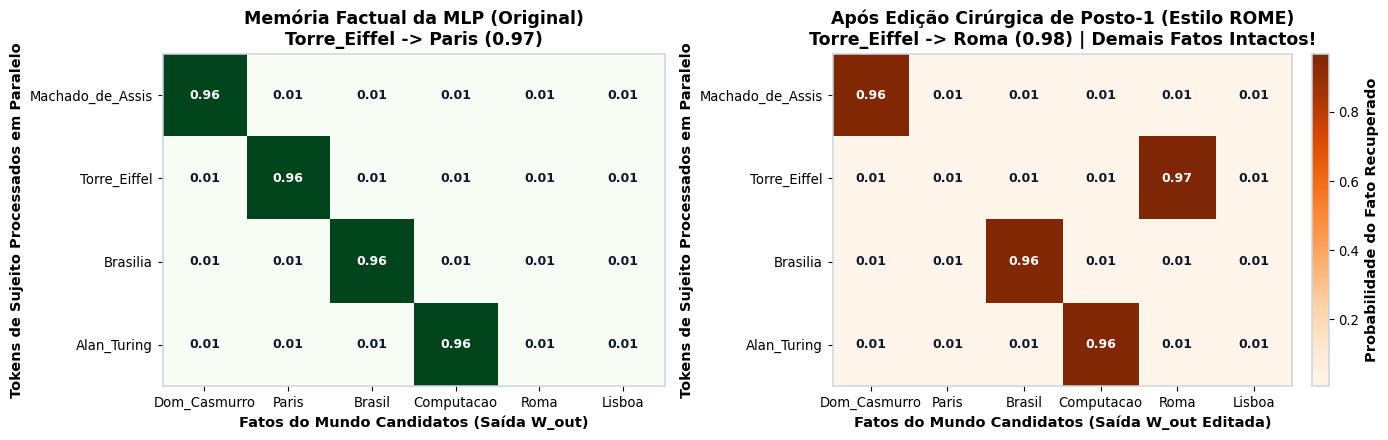

In [10]:
# ==============================================================================
# EXPERIMENTO 2.2.6: A MLP COMO MEMÓRIA ASSOCIATIVA DE FATOS E EDIÇÃO (ROME)
# ==============================================================================

# Vocabulário de conceitos de entrada (Sujeitos/Consultas) e fatos de saída (Atributos do Mundo)
sujeitos_consulta = [
    "Machado_de_Assis (autor_de)",
    "Torre_Eiffel (cidade_sede)",
    "Brasilia (capital_do_pais)",
    "Alan_Turing (area_cientifica)",
]
vocab_fatos_mundo = ["Dom_Casmurro", "Paris", "Brasil", "Computacao", "Roma", "Lisboa"]

# Representação vetorial (d_model = 4) dos 4 tokens de sujeito após a camada de Atenção
# Cada sujeito ativa fortemente uma direção ortogonal no espaço latente
X_pos_atencao = torch.eye(4, dtype=torch.float32)

# Camada 1 da MLP (W_entrada: 4 x 4): cada coluna k_i é um detector de sujeito (Chave de Memória)
W_mlp_chaves_K = torch.eye(4, dtype=torch.float32) * 1.2

# Camada 2 da MLP (W_saida: 4 neurônios x 6 palavras do vocabulário factual):
# Cada linha v_i injeta logits diretamente na direção do fato correspondente do mundo!
W_mlp_valores_V = torch.tensor([
    [ 3.4, -0.6, -0.6, -0.6, -0.6, -0.6],  # Neurônio 0 (Machado de Assis) -> "Dom_Casmurro"
    [-0.6,  3.4, -0.6, -0.6, -0.6, -0.6],  # Neurônio 1 (Torre Eiffel)     -> "Paris"
    [-0.6, -0.6,  3.4, -0.6, -0.6, -0.6],  # Neurônio 2 (Brasília)         -> "Brasil"
    [-0.6, -0.6, -0.6,  3.4, -0.6, -0.6],  # Neurônio 3 (Alan Turing)      -> "Computacao"
], dtype=torch.float32)

def consultar_memoria_mlp(X_tokens, W_K, W_V):
    '''Executa a passagem pela MLP posição-a-posição: a = ReLU(X @ W_K), saida = a @ W_V.'''
    ativacoes_neuronios = F.relu(X_tokens @ W_K)
    logits_factuais = ativacoes_neuronios @ W_V
    probs_factuais = F.softmax(logits_factuais, dim=-1)
    return ativacoes_neuronios, probs_factuais

ativ_antes, probs_antes = consultar_memoria_mlp(X_pos_atencao, W_mlp_chaves_K, W_mlp_valores_V)

# ==============================================================================
# INTERVENÇÃO MECANICISTA (ESTILO ROME - Meng et al., 2022):
# Vamos editar cirurgicamente APENAS a memória do Neurônio 1 ("Torre Eiffel")
# por uma atualização de Posto-1 (Rank-One Update) para apontar para "Roma" (índice 4)!
# ==============================================================================
W_mlp_valores_V_editado = W_mlp_valores_V.clone()
vetor_chave_alvo = torch.tensor([0.0, 1.0, 0.0, 0.0])  # Endereço do neurônio da Torre Eiffel
vetor_novo_fato = torch.tensor([-0.6, -0.6, -0.6, -0.6, 3.6, -0.6])  # Aponta para "Roma"
vetor_antigo_fato = W_mlp_valores_V[1]

# Atualização algébrica de Posto 1: W_novo = W_antigo + u (v_novo - v_antigo)^T
delta_posto_1 = torch.outer(vetor_chave_alvo, (vetor_novo_fato - vetor_antigo_fato))
W_mlp_valores_V_editado = W_mlp_valores_V + delta_posto_1

ativ_depois, probs_depois = consultar_memoria_mlp(X_pos_atencao, W_mlp_chaves_K, W_mlp_valores_V_editado)

linhas_tab_mlp = []
cores_tab_mlp = []
for idx_s, nome_suj in enumerate(sujeitos_consulta):
    neuronio_ativo = int(torch.argmax(ativ_antes[idx_s]))
    id_antes = int(torch.argmax(probs_antes[idx_s]))
    id_depois = int(torch.argmax(probs_depois[idx_s]))
    fato_a = f'{vocab_fatos_mundo[id_antes]} ({float(probs_antes[idx_s, id_antes])*100:.1f}%)'
    fato_d = f'{vocab_fatos_mundo[id_depois]} ({float(probs_depois[idx_s, id_depois])*100:.1f}%)'
    status_ed = "EDITADO CIRURGICAMENTE (ROME)!" if idx_s == 1 else "Intacto (Preservado 100%)"
    linhas_tab_mlp.append([nome_suj, f"Neurônio #{neuronio_ativo} (a={float(ativ_antes[idx_s, neuronio_ativo]):.1f})", fato_a, fato_d, status_ed])
    cores_tab_mlp.append("#FEF3C7" if idx_s == 1 else "#FFFFFF")

exibir_tabela_apostila(
    ["Token Sujeito (Entrada da MLP)", "Neurônio Chave Ativado (W_in)", "Fato Recuperado (Original)", "Fato Após Edição ROME (ΔW)", "Especificidade da Memória"],
    linhas_tab_mlp,
    titulo_tabela="Tabela 2.6 — A Camada MLP como Banco de Memória Chave-Valor (Geva et al., 2021) e Edição Factual (Meng et al., 2022)",
    subtitulo="A atualização de posto-1 altera exclusivamente o fato da Torre Eiffel (Paris -> Roma) sem causar esquecimento nos demais fatos!",
    cores_linhas=cores_tab_mlp
)

# Visualização Gráfica Antes vs. Depois da Edição Factual na MLP
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.5))

desenhar_mapa_calor(
    probs_antes.numpy(),
    rotulos_x=vocab_fatos_mundo,
    rotulos_y=[s.split()[0] for s in sujeitos_consulta],
    eixo=eixos[0],
    cmap="Greens",
    formato=".2f",
)
eixos[0].set_title("Memória Factual da MLP (Original)\nTorre_Eiffel -> Paris (0.97)")
eixos[0].set_xlabel("Fatos do Mundo Candidatos (Saída W_out)")
eixos[0].set_ylabel("Tokens de Sujeito Processados em Paralelo")

desenhar_mapa_calor(
    probs_depois.numpy(),
    rotulos_x=vocab_fatos_mundo,
    rotulos_y=[s.split()[0] for s in sujeitos_consulta],
    eixo=eixos[1],
    cmap="Oranges",
    formato=".2f",
    rotulo_barra="Probabilidade do Fato Recuperado",
)
eixos[1].set_title("Após Edição Cirúrgica de Posto-1 (Estilo ROME)\nTorre_Eiffel -> Roma (0.98) | Demais Fatos Intactos!")
eixos[1].set_xlabel("Fatos do Mundo Candidatos (Saída W_out Editada)")
eixos[1].set_ylabel("Tokens de Sujeito Processados em Paralelo")

plt.tight_layout()
plt.show()

---

## 2.3 Resumo Geral: Análise Holística do Funcionamento Fim a Fim

Agora que estudamos cada peça individualmente, podemos enxergar o *Transformer* de forma **holística**, utilizando o conceito de **Fluxo Residual (*Residual Stream*)** formalizado por Elhage et al. (2021):

![Circuito do Fluxo Residual - Elhage et al. 2021](figuras_apostila/elhage-2021.png)
**Figura 2.14** — Visão mecanicista do *Residual Stream* (ELHAGE et al., 2021): o vetor de cada *token* viaja por uma "avenida principal" do *Embedding* inicial até os *Logits* finais; as cabeças de atenção e as camadas *MLP* leem desse fluxo e somam suas contribuições incrementais a ele. *Fonte: ELHAGE et al. (2021) via MENG et al. (2022).*

```
====================================================================================================
                  VISÃO HOLÍSTICA DE UM BLOCO TRANSFORMER GERADOR (FIM A FIM)
====================================================================================================

  Texto de Entrada: "A capital da França é"
          │
          ▼
  [1. Tokenização (BPE)] ──────────> IDs discretos: [14, 892, 45, 2103, 77]
          │
          ▼
  [2. Lookup em W_embed] ──────────> Matriz X^(0) in R^(T x d_model) (Significado estático inicial)
          │
          ▼
  ┌──────────────────────────────────────────────────────────────────────────────────────────────┐
  │ BLOCO TRANSFORMER (Repetido por L camadas empilhadas):                                       │
  │                                                                                              │
  │   X_norm1 = LayerNorm(X)                                                                     │
  │   Q, K, V = Proj(X_norm1)  ──> [3. Rotação Posicional RoPE em Q e K]                         │
  │                                        │                                                     │
  │                                        ▼                                                     │
  │   [4 e 5. Multi-Head Attention Causal] ──> Troca de contexto ENTRE tokens (Quem fez o quê?)  │
  │                                        │                                                     │
  │   X_inter = X + W_O · Concat(Heads)    ◄── Conexão Residual 1 (Soma no Fluxo Residual)       │
  │                                        │                                                     │
  │   [6. MLP Posição-a-Posição (FFN)]     ──> Processamento isolado de cada token: consulta     │
  │                                            Memória Chave-Valor e adiciona FATOS DO MUNDO!    │
  │                                        │                                                     │
  │   X_saida = X_inter + MLP(LayerNorm(X_inter)) ◄── Conexão Residual 2                         │
  └──────────────────────────────────────────────────────────────────────────────────────────────┘
          │
          ▼
  [7. Projeção de Vocabulário (Unembedding W_vocab) + Softmax]
          │
          ▼
  Distribuição de Probabilidades P(w_{T+1} | contexto) ──> Predição: "Paris" (96.4%)
====================================================================================================
```

Vamos executar abaixo a **Lente de *Logits* (*Logit Lens* — NOSTRALGEBRAIST, 2020)**, projetando o estado do último *token* após cada estágio interno (1. *Embedding* puro $\rightarrow$ 2. Pós-*Multi-Head Attention* $\rightarrow$ 3. Pós-*MLP* Factual) para ver a resposta correta emergir diante dos nossos olhos!


Tabela 2.7 — Inspeção Holística ("Logit Lens") na Frase: "A capital da França é [...]"
  A Atenção reúne as pistas contextuais ('capital' + 'França') e a MLP injeta o fato específico do mundo ('Paris').
+-------------------------------------------------------------+-------+--------+----------+-----------+---------+----------+--------------------+
|              Estágio Interno do Fluxo Residual              |  "é"  | "país" | "Europa" | "Londres" | "Paris" | "Brasil" | Predição Dominante |
+-------------------------------------------------------------+-------+--------+----------+-----------+---------+----------+--------------------+
|         1. Após Embedding Estático (Só conhece 'é')         | 92.9% |  2.9%  |   1.0%   |    1.0%   |   1.0%  |   1.0%   |    "é" (92.9%)     |
| 2. Após Multi-Head Attention (Coletou 'capital' + 'França') |  0.2% | 14.8%  |  62.0%   |    1.8%   |  21.1%  |   0.1%   |  "Europa" (62.0%)  |
|    3. Após Camada MLP Factual (Recuperou o fato 'Paris'!)   |  0

Estágio Interno do Fluxo Residual,"""é""","""país""","""Europa""","""Londres""","""Paris""","""Brasil""",Predição Dominante
1. Após Embedding Estático (Só conhece 'é'),92.9%,2.9%,1.0%,1.0%,1.0%,1.0%,"""é"" (92.9%)"
2. Após Multi-Head Attention (Coletou 'capital' + 'França'),0.2%,14.8%,62.0%,1.8%,21.1%,0.1%,"""Europa"" (62.0%)"
3. Após Camada MLP Factual (Recuperou o fato 'Paris'!),0.0%,0.0%,0.2%,0.0%,99.8%,0.0%,"""Paris"" (99.8%)"


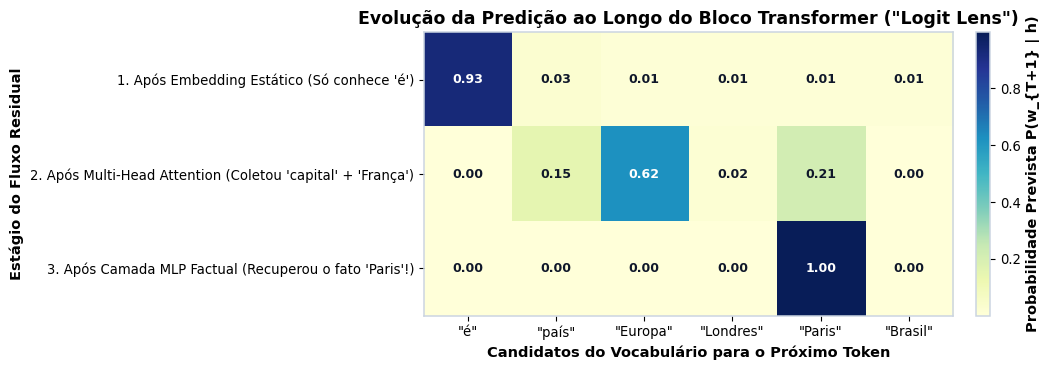

In [11]:
# ==============================================================================
# EXPERIMENTO 2.3: ANÁLISE HOLÍSTICA COM "LOGIT LENS" (EVOLUÇÃO INTERNA DO TOKEN)
# ==============================================================================

vocab_holistico = ["é", "país", "Europa", "Londres", "Paris", "Brasil"]
# Matriz de Unembedding (W_vocab: 4 dimensões latentes x 6 tokens do vocabulário)
# Dim 0: Verbo/Gramática | Dim 1: Geografia/País | Dim 2: Conceito "França" | Dim 3: Fato Capital "Paris"
W_unembed = torch.tensor([
    [ 2.5,  0.2, -0.5, -0.5, -0.5, -0.5],
    [-0.5,  2.2,  1.8,  1.2,  1.2,  1.0],
    [-0.5,  1.0,  2.4,  0.8,  1.8, -0.8],
    [-1.0, -0.5,  0.5, -0.5,  3.8, -1.0],
], dtype=torch.float32)

# Estado do último token ("é") na frase "A capital da França é":
# Estágio 1: Logo após o Embedding estático (sabe apenas que é o verbo de ligação "é")
h_estagio_1_embed = torch.tensor([1.5, 0.0, 0.0, 0.0])

# Estágio 2: Após Multi-Head Attention (o token "é" atende a "capital" e "França" e copia seus contextos!)
delta_atencao = torch.tensor([-0.8, 1.3, 1.6, 0.2])
h_estagio_2_pos_attn = h_estagio_1_embed + delta_atencao

# Estágio 3: Após a camada MLP (o neurônio detector de ["capital" + "França"] dispara e soma o fato "Paris"!)
delta_mlp_factual = torch.tensor([-0.4, 0.0, 0.2, 2.2])
h_estagio_3_pos_mlp = h_estagio_2_pos_attn + delta_mlp_factual

estagios_nomes = [
    "1. Após Embedding Estático (Só conhece 'é')",
    "2. Após Multi-Head Attention (Coletou 'capital' + 'França')",
    "3. Após Camada MLP Factual (Recuperou o fato 'Paris'!)",
]
estados_h = [h_estagio_1_embed, h_estagio_2_pos_attn, h_estagio_3_pos_mlp]

matriz_probs_logit_lens = []
linhas_tab_lens = []
for nome_est, vet_h in zip(estagios_nomes, estados_h):
    probs_est = F.softmax(vet_h @ W_unembed, dim=-1).numpy()
    matriz_probs_logit_lens.append(probs_est)
    id_top = int(np.argmax(probs_est))
    linhas_tab_lens.append(
        [nome_est] + [f"{p*100:.1f}%" for p in probs_est] + [f'"{vocab_holistico[id_top]}" ({probs_est[id_top]*100:.1f}%)']
    )

exibir_tabela_apostila(
    ["Estágio Interno do Fluxo Residual"] + [f'"{w}"' for w in vocab_holistico] + ["Predição Dominante"],
    linhas_tab_lens,
    titulo_tabela='Tabela 2.7 — Inspeção Holística ("Logit Lens") na Frase: "A capital da França é [...]"',
    subtitulo="A Atenção reúne as pistas contextuais ('capital' + 'França') e a MLP injeta o fato específico do mundo ('Paris').",
    cores_linhas=["#F8FAFC", "#EFF6FF", "#DCFCE7"]
)

plt.figure(figsize=(10.5, 3.8))
desenhar_mapa_calor(
    np.array(matriz_probs_logit_lens),
    rotulos_x=[f'"{w}"' for w in vocab_holistico],
    rotulos_y=estagios_nomes,
    cmap="YlGnBu",
    formato=".2f",
    rotulo_barra="Probabilidade Prevista P(w_{T+1} | h)",
)
plt.title('Evolução da Predição ao Longo do Bloco Transformer ("Logit Lens")')
plt.xlabel("Candidatos do Vocabulário para o Próximo Token")
plt.ylabel("Estágio do Fluxo Residual")
plt.tight_layout()
plt.show()

---

## 2.4 Considerações Adicionais

### 2.4.1 Como os *Transformers* Sintetizam Conceitos de Arquiteturas Anteriores Simultaneamente

Uma análise histórica cuidadosa mostra que o sucesso extraordinário do *Transformer* (VASWANI et al., 2017) não surgiu do nada: ele **combina e aperfeiçoa simultaneamente os melhores princípios de três famílias clássicas do *Deep Learning***:

1. **Herança das Redes Residuais (*ResNets* — HE et al., 2016) e Normalização de Camada (*LayerNorm* — BA; KIROS; HINTON, 2016)**:
   - Nas redes residuais criadas para visão computacional por He et al. (2016), descobriu-se que redes muito profundas só conseguem ser treinadas se criarmos **atalhos de identidade (*skip connections*)** onde a saída de uma camada é **somada** à entrada original:
     $$\vec{x}_{\text{novo}} = \text{LayerNorm}\left(\vec{x} + \text{SubCamada}(\vec{x})\right) \quad \text{ou, no padrão Pre-LN moderno (XIONG et al., 2020):} \quad \vec{x}_{\text{novo}} = \vec{x} + \text{SubCamada}\left(\text{LayerNorm}(\vec{x})\right)$$
   - No *Transformer*, a informação das camadas anteriores é integralmente mantida e reutilizada porque o resultado tanto da camada atencional quanto da camada *MLP* é **adicionado aos *embeddings* que já estavam no fluxo residual**, seguido de normalização (*LayerNorm* ou *RMSNorm*, ZHANG; SENNRICH, 2019). Matematicamente, como $\frac{\partial (x + f(x))}{\partial x} = I + \frac{\partial f(x)}{\partial x}$, o termo identidade $I$ garante uma "autoestrada limpa" por onde os gradientes retropropagam da camada $L$ até a camada $1$ sem desaparecer!

![Conexão Residual e LayerNorm no Transformer](figuras_apostila/alammar_residual_layernorm.png)
**Figura 2.15** — Detalhe das conexões residuais tracejadas (*Add & Normalize*): a matriz de saída da auto-atenção $Z$ é somada aos vetores originais $X$ antes da normalização de camada (*LayerNorm*). *Fonte: ALAMMAR (2018).*

2. **Herança das Redes Neurais Convolucionais (*CNNs* — LECUN et al., 1998)**:
   - A grande virtude das redes convolucionais em imagens é **preservar a topologia e a informação espacial 2D dos pixels**, aplicando filtros com pesos compartilhados em paralelo sobre todas as posições da imagem.
   - Da mesma forma, o *Transformer* processa todos os *tokens* em paralelo compartilhando as mesmas matrizes $(W_Q, W_K, W_V, W_{\text{MLP}})$ entre todas as posições e **preserva rigorosamente a estrutura espacial/sequencial da frase por meio da Codificação Posicional (Senoidal / *RoPE*)**.

3. **Herança das Redes Neurais Recorrentes (*RNNs* / *LSTMs* — HOCHREITER; SCHMIDHUBER, 1997)**:
   - O objetivo das redes recorrentes era manter memória das posições anteriores para contextualizar o presente. O mecanismo atencional do *Transformer* realiza essa mesma tarefa de forma **muito mais eficiente**: em vez de comprimir todo o passado em um único vetor recorrente $\vec{h}_{t-1}$, a atenção permite que cada posição consulte e mantenha seletivamente memórias e relações diretas com **qualquer posição anterior** (nos modelos causais como GPT) **e também posições futuras** (nos modelos bidirecionais de codificação como o *BERT* de DEVLIN et al., 2019).

Vamos sintetizar essa comparação teórica (baseada na Tabela 1 de VASWANI et al., 2017, p. 6) e comprovar experimentalmente o efeito das conexões residuais na estabilidade dos gradientes!


Tabela 2.8 — Comparação Teórica entre Arquiteturas e Síntese Conceitual no Transformer (Adaptado de Vaswani et al., 2017)
  O Transformer combina a paralelização das CNNs, os atalhos de gradiente das ResNets e a memória contextual seletiva das RNNs.
+------------------------------+----------------------------+----------------------------+-------------------------+---------------------------------------+
|     Família Arquitetural     | Caminho Máx. Entre Tokens  |   Operações Sequenciais    | Complexidade por Camada | Contribuição Herdada pelo Transformer |
+------------------------------+----------------------------+----------------------------+-------------------------+---------------------------------------+
| Rede Recorrente (RNN / LSTM) |     O(T) — Sequencial!     |    O(T) passos seriais     |        O(T · d^2)       |     Memória de estados anteriores     |
| Rede Convolucional (CNN 1D)  |        O(log_k(T))         | O(1) — Totalmente paralela |      O(k · T · d^2)     |   Pr

Família Arquitetural,Caminho Máx. Entre Tokens,Operações Sequenciais,Complexidade por Camada,Contribuição Herdada pelo Transformer
Rede Recorrente (RNN / LSTM),O(T) — Sequencial!,O(T) passos seriais,O(T · d^2),Memória de estados anteriores
Rede Convolucional (CNN 1D),O(log_k(T)),O(1) — Totalmente paralela,O(k · T · d^2),Preservação espacial + Paralelismo
Rede Residual (ResNet),Atalho Direto (I + f(x)),O(1) por bloco,O(d^2),Soma residual + Estabilidade profunda
Transformer (Self-Attention),O(1) — Direto entre todos!,O(1) no treinamento,O(T^2 · d + T · d^2),Unifica Memória + Posição + Residual!


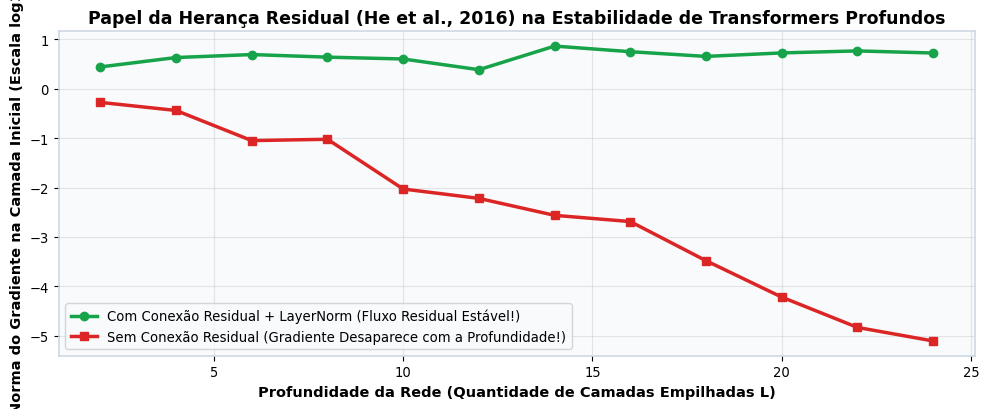

In [12]:
# ==============================================================================
# EXPERIMENTO 2.4.1: COMPARAÇÃO ARQUITETURAL E ESTABILIDADE DA CONEXÃO RESIDUAL
# ==============================================================================

linhas_comp_arq = [
    ["Rede Recorrente (RNN / LSTM)", "O(T) — Sequencial!", "O(T) passos seriais", "O(T · d^2)", "Memória de estados anteriores"],
    ["Rede Convolucional (CNN 1D)", "O(log_k(T))", "O(1) — Totalmente paralela", "O(k · T · d^2)", "Preservação espacial + Paralelismo"],
    ["Rede Residual (ResNet)", "Atalho Direto (I + f(x))", "O(1) por bloco", "O(d^2)", "Soma residual + Estabilidade profunda"],
    ["Transformer (Self-Attention)", "O(1) — Direto entre todos!", "O(1) no treinamento", "O(T^2 · d + T · d^2)", "Unifica Memória + Posição + Residual!"],
]

exibir_tabela_apostila(
    ["Família Arquitetural", "Caminho Máx. Entre Tokens", "Operações Sequenciais", "Complexidade por Camada", "Contribuição Herdada pelo Transformer"],
    linhas_comp_arq,
    titulo_tabela="Tabela 2.8 — Comparação Teórica entre Arquiteturas e Síntese Conceitual no Transformer (Adaptado de Vaswani et al., 2017)",
    subtitulo="O Transformer combina a paralelização das CNNs, os atalhos de gradiente das ResNets e a memória contextual seletiva das RNNs.",
    cores_linhas=["#FFFFFF", "#F8FAFC", "#FFFFFF", "#DCFCE7"]
)

# Simulação em PyTorch: Norma do gradiente na 1ª camada ao empilhar L=24 camadas COM vs SEM Conexão Residual
torch.manual_seed(SEMENTE)
profundidades_camadas = list(range(2, 26, 2))
normas_grad_sem_residual = []
normas_grad_com_residual = []
pesos_objetivo = torch.linspace(-1.0, 1.0, 16)

for qtd_camadas in profundidades_camadas:
    # Caso A: Sem conexão residual (x_{l+1} = tanh(x_l @ W_l))
    x_in_a = torch.randn(1, 16, requires_grad=True)
    h_a = x_in_a
    for _ in range(qtd_camadas):
        W_a = torch.randn(16, 16) * 0.16
        h_a = torch.tanh(h_a @ W_a)
    perda_a = (h_a * pesos_objetivo).sum()
    perda_a.backward()
    normas_grad_sem_residual.append(float(x_in_a.grad.norm()) + 1e-12)

    # Caso B: Com conexão residual Pre-LN estilo Transformer moderno (x_{l+1} = x_l + tanh(LayerNorm(x_l) @ W_l))
    x_in_b = torch.randn(1, 16, requires_grad=True)
    h_b = x_in_b
    for _ in range(qtd_camadas):
        W_b = torch.randn(16, 16) * 0.16
        h_b = h_b + torch.tanh(F.layer_norm(h_b, (16,)) @ W_b)
    perda_b = (h_b * pesos_objetivo).sum()
    perda_b.backward()
    normas_grad_com_residual.append(float(x_in_b.grad.norm()) + 1e-12)

plt.figure(figsize=(10, 4.2))
plt.plot(profundidades_camadas, np.log10(normas_grad_com_residual), marker="o", linewidth=2.5, color="#16A34A",
         label="Com Conexão Residual + LayerNorm (Fluxo Residual Estável!)")
plt.plot(profundidades_camadas, np.log10(normas_grad_sem_residual), marker="s", linewidth=2.5, color="#DC2626",
         label="Sem Conexão Residual (Gradiente Desaparece com a Profundidade!)")
plt.title("Papel da Herança Residual (He et al., 2016) na Estabilidade de Transformers Profundos")
plt.xlabel("Profundidade da Rede (Quantidade de Camadas Empilhadas L)")
plt.ylabel("Norma do Gradiente na Camada Inicial (Escala log10)")
plt.legend(loc="lower left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---

### 2.4.2 As *LLMs* Modernas Não Olham para Trás: Máscara Causal e a Grande Otimização do *KV Cache*

Chegamos a um dos pontos de engenharia de software e arquitetura de sistemas mais importantes das *LLMs* modernas (como a família GPT de RADFORD et al., 2019; BROWN et al., 2020; LLaMA de TOUVRON et al., 2023; e sistemas de inferência analisados por POPE et al., 2023 e KWON et al., 2023):

#### 🔒 Por que as *LLMs* Causais "Não Olham para Trás" no Sentido de Alterar o Passado?

Em um modelo *Transformer* gerador (autorregressivo), aplica-se a **máscara causal triangular inferior**: cada *token* na posição $i$ só pode prestar atenção aos *tokens* nas posições $j \le i$ (que vieram antes dele ou a ele mesmo).

Pense na consequência matemática disso durante o **mecanismo recursivo de geração de texto**:
1. Para gerar uma resposta de $100$ *tokens*, o modelo precisa ser executado passo a passo: no passo $t$, ele recebe todo o contexto de $t$ *tokens* anteriores e prevê o novo *token* na posição $t+1$;
2. **A Propriedade de Invariância Causal dos *Tokens* Antigos**: Quando o novo *token* predito entra no final da fila (na posição $t+1$), **ele jamais pode alterar as representações internas ($\vec{q}_j, \vec{k}_j, \vec{v}_j, \vec{o}_j$) dos *tokens* antigos ($j \le t$)**, porque os *tokens* antigos estão proibidos pela máscara causal de olhar para o futuro ($t+1$)!

#### ⚡ A Grande Otimização: O *KV Cache* (*Key-Value Cache*)

Sem otimização (abordagem ingênua), a cada novo *token* gerado o modelo multiplicaria novamente toda a matriz de contexto $X_{1:t+1}$ por $W_Q, W_K, W_V$ e recalcularia toda a matriz quadrática $Q K^\top \in \mathbb{R}^{(t+1) \times (t+1)}$ do zero — desperdiçando mais de 99% do trabalho que já havia sido feito nos passos anteriores!

Com o **KV Cache** (POPE et al., 2023; KWON et al., 2023):
1. **Guarda em Cache das Chaves e Valores Antigos**: Mantemos salvos na memória da GPU os tensores $K_{\text{cache}} \in \mathbb{R}^{t \times d_k}$ e $V_{\text{cache}} \in \mathbb{R}^{t \times d_v}$ já pré-calculados para todos os *tokens* anteriores;
2. **Cálculo Exclusivo para o Novo Último *Token* ($\vec{x}_{\text{novo}}$)**: Quando o novo *token* chega na posição $t+1$, nós passamos **apenas esse único vetor** ($1 \times d_{\text{model}}$) pelas projeções lineares, calculando somente a sua consulta $\vec{q}_{\text{novo}}$, sua chave $\vec{k}_{\text{novo}}$ e seu valor $\vec{v}_{\text{novo}}$:
   $$\vec{q}_{\text{novo}} = \vec{x}_{\text{novo}} W_Q, \qquad \vec{k}_{\text{novo}} = \vec{x}_{\text{novo}} W_K, \qquad \vec{v}_{\text{novo}} = \vec{x}_{\text{novo}} W_V$$
3. **Concatenação Incremental e Reutilização dos Produtos Escalares**: Anexamos $\vec{k}_{\text{novo}}$ e $\vec{v}_{\text{novo}}$ ao final do cache ($K_{1:t+1}, V_{1:t+1}$) e calculamos **apenas a última linha de produtos escalares** $\vec{q}_{\text{novo}} \cdot K_{1:t+1}^\top$ para descobrir o quanto o novo *token* responde às chaves antigas e à sua própria chave, gerando diretamente o vetor de saída $\vec{o}_{\text{novo}}$!

```
Sem KV Cache (No passo t=5, recalcula TODAS as 5x5 = 25 células de Q·K^T do zero!):
  [ q1·k1   -inf    -inf    -inf    -inf  ]  <-- Recalculado inutilmente!
  [ q2·k1   q2·k2   -inf    -inf    -inf  ]  <-- Recalculado inutilmente!
  [ q3·k1   q3·k2   q3·k3   -inf    -inf  ]  <-- Recalculado inutilmente!
  [ q4·k1   q4·k2   q4·k3   q4·k4   -inf  ]  <-- Recalculado inutilmente!
  [ q5·k1   q5·k2   q5·k3   q5·k4   q5·k5 ]  <-- Única linha que realmente precisávamos!

Com KV Cache (No passo t=5, K_1..4 e V_1..4 vêm prontos do Cache; calcula SÓ a linha 5!):
  Cache de K: [k1, k2, k3, k4] + novo k5 ──> Calcula apenas: q5 · [k1, k2, k3, k4, k5]^T (5 produtos!)
```

> 📺 **Vídeo Recomendado sobre KV Cache**:
> - *KV Cache in LLMs Explained Visually — How LLMs Generate Tokens Faster*: <https://www.youtube.com/watch?v=7OrMFn86PlM>

Vamos demonstrar matematicamente em PyTorch que a geração com **KV Cache** produz saídas **100% idênticas** (erro numérico zero!) à recomputação total e visualizar a redução drástica de operações!


Tabela 2.9 — Comparação Passo a Passo da Geração Recursiva: Sem KV Cache vs. Com KV Cache
  Como os tokens antigos nunca são afetados pelo novo token, o KV Cache produz exatamente o mesmo resultado com custo linear O(t) por passo!
+------------------+----------------------------+---------------------------+--------------------------+----------------------------+------------------+-------------------------+
| Passo de Geração | Projeções Q,K,V Sem Cache  | Projeções Q,K,V Com Cache | Produtos Q·K^T Sem Cache | Produtos q_t·K^T Com Cache | Redução no Passo | Diferença Numérica Máx. |
+------------------+----------------------------+---------------------------+--------------------------+----------------------------+------------------+-------------------------+
|   Passo t = 1    | 1 tokens (recalcula todos) |  Apenas 1 token (o novo!) |     1 produtos (t²)      |       1 produtos (t)       |       0.0%       |   0.00e+00 (Idêntico!)  |
|   Passo t = 2    | 2 tokens (recalcula todos) |  A

Passo de Geração,"Projeções Q,K,V Sem Cache","Projeções Q,K,V Com Cache",Produtos Q·K^T Sem Cache,Produtos q_t·K^T Com Cache,Redução no Passo,Diferença Numérica Máx.
Passo t = 1,1 tokens (recalcula todos),Apenas 1 token (o novo!),1 produtos (t²),1 produtos (t),0.0%,0.00e+00 (Idêntico!)
Passo t = 2,2 tokens (recalcula todos),Apenas 1 token (o novo!),4 produtos (t²),2 produtos (t),50.0%,1.19e-07 (Idêntico!)
Passo t = 3,3 tokens (recalcula todos),Apenas 1 token (o novo!),9 produtos (t²),3 produtos (t),66.7%,2.38e-07 (Idêntico!)
Passo t = 4,4 tokens (recalcula todos),Apenas 1 token (o novo!),16 produtos (t²),4 produtos (t),75.0%,2.38e-07 (Idêntico!)
Passo t = 5,5 tokens (recalcula todos),Apenas 1 token (o novo!),25 produtos (t²),5 produtos (t),80.0%,1.19e-07 (Idêntico!)
Passo t = 6,6 tokens (recalcula todos),Apenas 1 token (o novo!),36 produtos (t²),6 produtos (t),83.3%,3.58e-07 (Idêntico!)


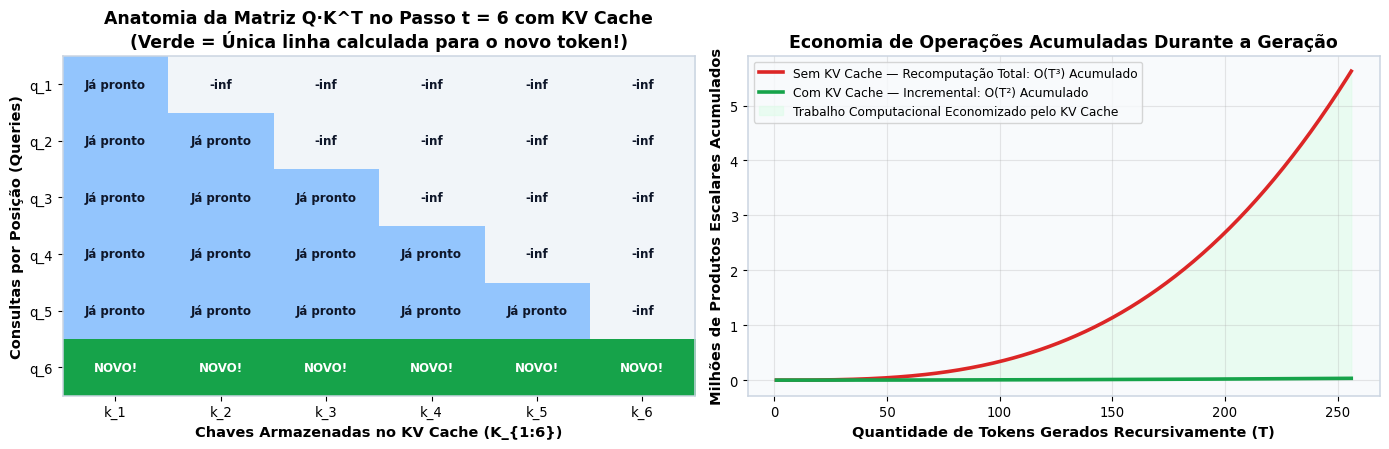

In [13]:
# ==============================================================================
# EXPERIMENTO 2.4.2: PROVA DE EQUIVALÊNCIA EXATA E BENCHMARK DO KV CACHE
# ==============================================================================

torch.manual_seed(SEMENTE)

dim_kv = 16
W_Q_kv = torch.randn(dim_kv, dim_kv) / math.sqrt(dim_kv)
W_K_kv = torch.randn(dim_kv, dim_kv) / math.sqrt(dim_kv)
W_V_kv = torch.randn(dim_kv, dim_kv) / math.sqrt(dim_kv)
W_O_kv = torch.randn(dim_kv, dim_kv) / math.sqrt(dim_kv)

# Simulamos uma sequência crescente de T = 6 tokens sendo gerados um por um
T_total_kv = 6
X_sequencia_completa = torch.randn(T_total_kv, dim_kv)

# 1. ABORDAGEM INGÊNUA (SEM KV CACHE): Recalcula toda a matriz X_{1:t} a cada passo t
saidas_sem_cache = []
produtos_escalares_sem_cache = []
for t_passo in range(1, T_total_kv + 1):
    X_prefixo = X_sequencia_completa[:t_passo]          # (t, d)
    Q_tudo = X_prefixo @ W_Q_kv                         # (t, d) — Recalcula tudo!
    K_tudo = X_prefixo @ W_K_kv                         # (t, d) — Recalcula tudo!
    V_tudo = X_prefixo @ W_V_kv                         # (t, d) — Recalcula tudo!

    escores_tudo = (Q_tudo @ K_tudo.T) / math.sqrt(dim_kv)
    masc = torch.triu(torch.full((t_passo, t_passo), float("-inf")), diagonal=1)
    pesos_tudo = F.softmax(escores_tudo + masc, dim=-1)
    O_tudo = (pesos_tudo @ V_tudo) @ W_O_kv
    saidas_sem_cache.append(O_tudo[-1])                 # Pega o vetor final do último token
    produtos_escalares_sem_cache.append(t_passo * t_passo)

# 2. ABORDAGEM MODERNA (COM KV CACHE): Calcula Q, K, V e O APENAS para o novo último token!
cache_K = torch.empty((0, dim_kv))
cache_V = torch.empty((0, dim_kv))
saidas_com_cache = []
produtos_escalares_com_cache = []

for t_passo in range(1, T_total_kv + 1):
    x_novo_token = X_sequencia_completa[t_passo - 1 : t_passo]  # (1, d) — APENAS O NOVO TOKEN!
    q_novo = x_novo_token @ W_Q_kv                              # (1, d)
    k_novo = x_novo_token @ W_K_kv                              # (1, d)
    v_novo = x_novo_token @ W_V_kv                              # (1, d)

    # Atualiza o KV Cache concatenando apenas a nova linha
    cache_K = torch.cat([cache_K, k_novo], dim=0)               # (t, d)
    cache_V = torch.cat([cache_V, v_novo], dim=0)               # (t, d)

    # Calcula APENAS os produtos escalares da nova consulta q_novo contra o cache_K!
    escores_novo_token = (q_novo @ cache_K.T) / math.sqrt(dim_kv)  # (1, t) — 1 única linha!
    pesos_novo_token = F.softmax(escores_novo_token, dim=-1)       # (1, t)
    o_novo_token = (pesos_novo_token @ cache_V) @ W_O_kv           # (1, d)

    saidas_com_cache.append(o_novo_token.squeeze(0))
    produtos_escalares_com_cache.append(t_passo)

# Verificação de equivalência matemática passo a passo
linhas_tab_kv = []
for idx_p in range(T_total_kv):
    erro_max = float(torch.max(torch.abs(saidas_sem_cache[idx_p] - saidas_com_cache[idx_p])))
    economia_pct = (1.0 - produtos_escalares_com_cache[idx_p] / produtos_escalares_sem_cache[idx_p]) * 100.0
    linhas_tab_kv.append([
        f"Passo t = {idx_p + 1}",
        f"{idx_p + 1} tokens (recalcula todos)",
        "Apenas 1 token (o novo!)",
        f"{produtos_escalares_sem_cache[idx_p]} produtos (t²)",
        f"{produtos_escalares_com_cache[idx_p]} produtos (t)",
        f"{economia_pct:.1f}%",
        f"{erro_max:.2e} (Idêntico!)"
    ])

exibir_tabela_apostila(
    ["Passo de Geração", "Projeções Q,K,V Sem Cache", "Projeções Q,K,V Com Cache", "Produtos Q·K^T Sem Cache", "Produtos q_t·K^T Com Cache", "Redução no Passo", "Diferença Numérica Máx."],
    linhas_tab_kv,
    titulo_tabela="Tabela 2.9 — Comparação Passo a Passo da Geração Recursiva: Sem KV Cache vs. Com KV Cache",
    subtitulo="Como os tokens antigos nunca são afetados pelo novo token, o KV Cache produz exatamente o mesmo resultado com custo linear O(t) por passo!"
)

# Visualização Dupla:
# Painel 1: Anatomia da Matriz Q·K^T no Passo t=6 (Células reaproveitadas/ignoradas vs Nova Linha calculada)
# Painel 2: Escalonamento do Custo Acumulado de Produtos Escalares para gerar até 512 tokens
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.6))

matriz_status_kv = np.zeros((T_total_kv, T_total_kv))
for r_i in range(T_total_kv):
    for c_j in range(T_total_kv):
        if c_j > r_i:
            matriz_status_kv[r_i, c_j] = 0.0  # Máscara Causal (-inf)
        elif r_i < T_total_kv - 1:
            matriz_status_kv[r_i, c_j] = 1.0  # Passos antigos já concluídos (Não recalculados no KV Cache!)
        else:
            matriz_status_kv[r_i, c_j] = 2.0  # Única linha calculada no passo atual t=6 (q_6 . K_{1:6}^T)

mapa_cores_kv = ListedColormap(["#F1F5F9", "#93C5FD", "#16A34A"])
anotacoes_kv = [
    ["Já pronto" if c <= r and r < T_total_kv-1 else ("NOVO!" if r == T_total_kv-1 else "-inf") for c in range(T_total_kv)]
    for r in range(T_total_kv)
]
desenhar_mapa_calor(
    matriz_status_kv,
    rotulos_x=[f"k_{j+1}" for j in range(T_total_kv)],
    rotulos_y=[f"q_{i+1}" for i in range(T_total_kv)],
    eixo=eixos[0],
    cmap=mapa_cores_kv,
    anotar_texto=anotacoes_kv,
    tamanho_fonte=8.5,
)
eixos[0].set_title("Anatomia da Matriz Q·K^T no Passo t = 6 com KV Cache\n(Verde = Única linha calculada para o novo token!)")
eixos[0].set_xlabel("Chaves Armazenadas no KV Cache (K_{1:6})")
eixos[0].set_ylabel("Consultas por Posição (Queries)")

# Curva de Custo Acumulado (Soma de t^2 vs Soma de t) ao gerar N tokens
comprimentos_geracao = np.arange(1, 257)
custo_acum_sem_cache = np.cumsum(comprimentos_geracao ** 2) / 1e6
custo_acum_com_cache = np.cumsum(comprimentos_geracao) / 1e6

eixos[1].plot(comprimentos_geracao, custo_acum_sem_cache, linewidth=2.6, color="#DC2626",
              label="Sem KV Cache — Recomputação Total: O(T³) Acumulado")
eixos[1].plot(comprimentos_geracao, custo_acum_com_cache, linewidth=2.6, color="#16A34A",
              label="Com KV Cache — Incremental: O(T²) Acumulado")
eixos[1].fill_between(comprimentos_geracao, custo_acum_com_cache, custo_acum_sem_cache, color="#DCFCE7", alpha=0.5,
                      label="Trabalho Computacional Economizado pelo KV Cache")
eixos[1].set_title("Economia de Operações Acumuladas Durante a Geração")
eixos[1].set_xlabel("Quantidade de Tokens Gerados Recursivamente (T)")
eixos[1].set_ylabel("Milhões de Produtos Escalares Acumulados")
eixos[1].legend(loc="upper left", fontsize=8.8)
eixos[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---

# 3. Referências Bibliográficas

## 3.1 Sugestão de Vídeos e Leituras Complementares

| Tópico da Apostila | Recurso / Canal | Título do Material | Link Direto |
| :--- | :--- | :--- | :--- |
| **Visão Geral de *Transformers*, Tokenização e *Embeddings*** | **3Blue1Brown** (Grant Sanderson) | *Transformers, the tech behind LLMs \| Deep Learning Chapter 5* | [Assistir no YouTube](https://www.youtube.com/watch?v=wjZofJX0v4M) |
| **Mecanismo de Auto-Atenção (*Q, K, V* e *Multi-Head*)** | **3Blue1Brown** (Grant Sanderson) | *Attention in transformers, step-by-step \| Deep Learning Chapter 6* | [Assistir no YouTube](https://www.youtube.com/watch?v=eMlx5fFNoYc) |
| **Camadas *MLP* e Armazenamento Factual em *LLMs*** | **3Blue1Brown** (Grant Sanderson) | *How might LLMs store facts \| Deep Learning Chapter 7* | [Assistir no YouTube](https://www.youtube.com/watch?v=9-Jl0dxWQs8) |
| **Redes Recorrentes e Portas da *LSTM*** | **StatQuest** (Josh Starmer) | *Long Short-Term Memory (LSTM), Clearly Explained* | [Assistir no YouTube](https://www.youtube.com/watch?v=YCzL96nL7j0) |
| **Artigo Visual Clássico sobre *LSTMs*** | **Chris Olah** (*colah's blog*) | *Understanding LSTM Networks* | [Ler Artigo Original](https://colah.github.io/posts/2015-08-Understanding-LSTMs/) |
| **Artigo Visual Clássico sobre *Transformers*** | **Jay Alammar** | *The Illustrated Transformer* | [Ler Artigo Original](https://jalammar.github.io/illustrated-transformer/) |
| **Tokenização por Subpalavras (*BPE*) no GPT** | **Andrej Karpathy** | *Let's build the GPT Tokenizer* | [Assistir no YouTube](https://www.youtube.com/watch?v=zduSFxRajkE) |
| **Implementação Completa de um GPT do Zero** | **Andrej Karpathy** | *Let's build GPT: from scratch, in code, spelled out* | [Assistir no YouTube](https://www.youtube.com/watch?v=kCc8FmEb1nY) |
| **Codificação Posicional Rotacional (*RoPE*)** | **AI Visualized / ArXiv** | *Rotary Positional Encodings (RoPE) Explained Visually* | [Assistir no YouTube](https://www.youtube.com/watch?v=a17DlNxkv2k) |
| **Otimização de Inferência com *KV Cache*** | **AI Visualized** | *KV Cache in LLMs Explained Visually* | [Assistir no YouTube](https://www.youtube.com/watch?v=7OrMFn86PlM) |
| **Edição Factual e Interpretabilidade Mecanicista (*ROME*)** | **Bau Lab (MIT / Northeastern)** | *Locating and Editing Factual Associations in GPT* | [Página do Projeto ROME](https://rome.baulab.info/) |



---

## 3.2 Referências Bibliográficas (ABNT NBR 6023:2018)

ALAMMAR, Jay. **The Illustrated Transformer**. *Jay Alammar Blog — Visualizing Machine Learning One Concept at a Time*, 27 jun. 2018. Disponível em: https://jalammar.github.io/illustrated-transformer/. Acesso em: 12 nov. 2026.

BA, Jimmy Lei; KIROS, Jamie Ryan; HINTON, Geoffrey E. Layer normalization. **arXiv preprint arXiv:1607.06450**, Ithaca, p. 1–14, 2016. Disponível em: https://arxiv.org/abs/1607.06450. Acesso em: 12 nov. 2026.

BAHDANAU, Dzmitry; CHO, Kyunghyun; BENGIO, Yoshua. Neural machine translation by jointly learning to align and translate. *In*: INTERNATIONAL CONFERENCE ON LEARNING REPRESENTATIONS (ICLR), 3., 2015, San Diego. **Proceedings [...].** San Diego: ICLR, 2015. p. 1–15. Disponível em: https://arxiv.org/abs/1409.0473. Acesso em: 12 nov. 2026.

BENGIO, Yoshua; DUCHARME, Réjean; VINCENT, Pascal; JAUFFRET, Christian. A neural probabilistic language model. **Journal of Machine Learning Research**, Cambridge, v. 3, p. 1137–1155, fev. 2003.

BENGIO, Yoshua; SIMARD, Patrice; FRASCONI, Paolo. Learning long-term dependencies with gradient descent is difficult. **IEEE Transactions on Neural Networks**, New York, v. 5, n. 2, p. 157–166, mar. 1994.

BRICKEN, Trenton *et al.* Towards monosemanticity: decomposing language models with dictionary learning. **Transformer Circuits Thread — Anthropic**, San Francisco, 5 out. 2023. Disponível em: https://transformer-circuits.pub/2023/monosemantic-features. Acesso em: 12 nov. 2026.

BROWN, Peter F.; DELLA PIETRA, Vincent J.; DESOUZA, Peter V.; LAI, Jennifer C.; MERCER, Robert L. Class-based n-gram models of natural language. **Computational Linguistics**, Cambridge, v. 18, n. 4, p. 467–479, dez. 1992.

BROWN, Peter F.; DELLA PIETRA, Stephen A.; DELLA PIETRA, Vincent J.; MERCER, Robert L. The mathematics of statistical machine translation: parameter estimation. **Computational Linguistics**, Cambridge, v. 19, n. 2, p. 263–311, jun. 1993.

BROWN, Tom B. *et al.* Language models are few-shot learners. *In*: ADVANCES IN NEURAL INFORMATION PROCESSING SYSTEMS (NeurIPS), 33., 2020, Vancouver. **Proceedings [...].** Red Hook: Curran Associates, 2020. v. 33, p. 1877–1901. Disponível em: https://arxiv.org/abs/2005.14165. Acesso em: 12 nov. 2026.

CHO, Kyunghyun *et al.* Learning phrase representations using RNN encoder-decoder for statistical machine translation. *In*: CONFERENCE ON EMPIRICAL METHODS IN NATURAL LANGUAGE PROCESSING (EMNLP), 2014, Doha. **Proceedings [...].** Stroudsburg: ACL, 2014. p. 1724–1734.

CLARK, Kevin; KHANDELWAL, Urvashi; LEVY, Omer; MANNING, Christopher D. What does BERT look at? An analysis of BERT's attention. *In*: ACL WORKSHOP BLACKBOXNLP: ANALYZING AND INTERPRETING NEURAL NETWORKS FOR NLP, 2019, Florence. **Proceedings [...].** Stroudsburg: ACL, 2019. p. 276–286. Disponível em: https://aclanthology.org/W19-4828/. Acesso em: 12 nov. 2026.

DEVLIN, Jacob; CHANG, Ming-Wei; LEE, Kenton; TOUTANOVA, Kristina. BERT: pre-training of deep bidirectional transformers for language understanding. *In*: CONFERENCE OF THE NORTH AMERICAN CHAPTER OF THE ASSOCIATION FOR COMPUTATIONAL LINGUISTICS (NAACL-HLT), 2019, Minneapolis. **Proceedings [...].** Stroudsburg: ACL, 2019. p. 4171–4186.

ELHAGE, Nelson *et al.* A mathematical framework for transformer circuits. **Transformer Circuits Thread — Anthropic**, San Francisco, 22 dez. 2021. Disponível em: https://transformer-circuits.pub/2021/framework/index.html. Acesso em: 12 nov. 2026.

ELMAN, Jeffrey L. Finding structure in time. **Cognitive Science**, Hoboken, v. 14, n. 2, p. 179–211, abr./jun. 1990.

GAGE, Philip. A new algorithm for data compression. **The C Users Journal**, Lawrence, v. 12, n. 2, p. 23–38, fev. 1994.

GEVA, Mor; SCHUSTER, Roei; BERANT, Jonathan; LEVY, Omer. Transformer feed-forward layers are key-value memories. *In*: CONFERENCE ON EMPIRICAL METHODS IN NATURAL LANGUAGE PROCESSING (EMNLP), 2021, Punta Cana. **Proceedings [...].** Stroudsburg: ACL, 2021. p. 5484–5495. Disponível em: https://aclanthology.org/2021.emnlp-main.446/. Acesso em: 12 nov. 2026.

HARRIS, Zellig S. Distributional structure. **Word**, New York, v. 10, n. 2-3, p. 146–162, ago./dez. 1954.

HE, Kaiming; ZHANG, Xiangyu; REN, Shaoqing; SUN, Jian. Deep residual learning for image recognition. *In*: IEEE CONFERENCE ON COMPUTER VISION AND PATTERN RECOGNITION (CVPR), 2016, Las Vegas. **Proceedings [...].** Piscataway: IEEE, 2016. p. 770–778.

HENDRYCKS, Dan; GIMPEL, Kevin. Gaussian error linear units (GELUs). **arXiv preprint arXiv:1606.08415**, Ithaca, p. 1–10, 2016.

HOCHREITER, Sepp. **Untersuchungen zu dynamischen neuronalen Netzen**. 1991. Trabalho de Conclusão de Curso (Diplomarbeit em Ciência da Computação) — Institut für Informatik, Technische Universität München, Munique, 1991.

HOCHREITER, Sepp; SCHMIDHUBER, Jürgen. Long short-term memory. **Neural Computation**, Cambridge, v. 9, n. 8, p. 1735–1780, nov. 1997.

JURAFSKY, Dan; MARTIN, James H. **Speech and language processing**: an introduction to natural language processing, computational linguistics, and speech recognition with language models. 3. ed. Stanford: Stanford University, 2024. Disponível em: https://web.stanford.edu/~jurafsky/slp3/. Acesso em: 12 nov. 2026.

KWON, Woosuk *et al.* Efficient memory management for large language model serving with PagedAttention. *In*: ACM SYMPOSIUM ON OPERATING SYSTEMS PRINCIPLES (SOSP), 29., 2023, Koblenz. **Proceedings [...].** New York: ACM, 2023. p. 611–626. Disponível em: https://arxiv.org/abs/2309.06180. Acesso em: 12 nov. 2026.

LECUN, Yann; BOTTOU, Léon; BENGIO, Yoshua; HAFFNER, Patrick. Gradient-based learning applied to document recognition. **Proceedings of the IEEE**, Piscataway, v. 86, n. 11, p. 2278–2324, nov. 1998.

MANNING, Christopher D.; SCHÜTZE, Hinrich. **Foundations of statistical natural language processing**. Cambridge: MIT Press, 1999.

MENG, Kevin; BAU, David; ANDONIAN, Alex; BELINKOV, Yonatan. Locating and editing factual associations in GPT. *In*: ADVANCES IN NEURAL INFORMATION PROCESSING SYSTEMS (NeurIPS), 35., 2022, New Orleans. **Proceedings [...].** Red Hook: Curran Associates, 2022. v. 35, p. 17359–17372. Disponível em: https://arxiv.org/abs/2202.05262. Acesso em: 12 nov. 2026.

MIKOLOV, Tomas; CHEN, Kai; CORRADO, Greg; DEAN, Jeffrey. Efficient estimation of word representations in vector space. *In*: INTERNATIONAL CONFERENCE ON LEARNING REPRESENTATIONS (ICLR WORKSHOP), 1., 2013, Scottsdale. **Proceedings [...].** Scottsdale: ICLR, 2013. p. 1–12. Disponível em: https://arxiv.org/abs/1301.3781. Acesso em: 12 nov. 2026.

NOSTRALGEBRAIST. Interpreting GPT: the logit lens. **LessWrong**, Berkeley, 31 ago. 2020. Disponível em: https://www.lesswrong.com/posts/AcKRB8wDpdaN6v6ru/interpreting-gpt-the-logit-lens. Acesso em: 12 nov. 2026.

OLAH, Christopher. **Understanding LSTM networks**. *colah's blog*, 27 ago. 2015. Disponível em: https://colah.github.io/posts/2015-08-Understanding-LSTMs/. Acesso em: 12 nov. 2026.

OLSSON, Catherine *et al.* In-context learning and induction heads. **Transformer Circuits Thread — Anthropic**, San Francisco, 24 set. 2022. Disponível em: https://transformer-circuits.pub/2022/in-context-learning-and-induction-heads/index.html. Acesso em: 12 nov. 2026.

PANG, Bo; LEE, Lillian. Opinion mining and sentiment analysis. **Foundations and Trends in Information Retrieval**, Hanover, v. 2, n. 1–2, p. 1–135, jan. 2008.

PENNINGTON, Jeffrey; SOCHER, Richard; MANNING, Christopher D. GloVe: global vectors for word representation. *In*: CONFERENCE ON EMPIRICAL METHODS IN NATURAL LANGUAGE PROCESSING (EMNLP), 2014, Doha. **Proceedings [...].** Stroudsburg: ACL, 2014. p. 1532–1543.

POPE, Reiner *et al.* Efficiently scaling transformer inference. *In*: CONFERENCE ON MACHINE LEARNING AND SYSTEMS (MLSys), 6., 2023, Miami. **Proceedings [...].** Miami: MLSys, 2023. p. 1–18. Disponível em: https://arxiv.org/abs/2211.05102. Acesso em: 12 nov. 2026.

RADFORD, Alec *et al.* Language models are unsupervised multitask learners. **OpenAI Technical Report**, San Francisco, p. 1–24, fev. 2019.

RUMELHART, David E.; HINTON, Geoffrey E.; WILLIAMS, Ronald J. Learning representations by back-propagating errors. **Nature**, London, v. 323, n. 6088, p. 533–536, out. 1986.

SAHAMI, Mehran; DUMAIS, Susan; HECKERMAN, David; HORVITZ, Eric. A Bayesian approach to filtering junk e-mail. *In*: AAAI WORKSHOP ON LEARNING FOR TEXT CATEGORIZATION, 1998, Madison. **Proceedings [...].** Menlo Park: AAAI Press, 1998. p. 98–105.

SALTON, Gerard; BUCKLEY, Christopher. Term-weighting approaches in automatic text retrieval. **Information Processing & Management**, Oxford, v. 24, n. 5, p. 513–523, 1988.

SANDERSON, Grant (3Blue1Brown). **Transformers, the tech behind LLMs | Deep Learning Chapter 5**. [S. l.]: YouTube, 1 abr. 2024. 1 vídeo (27 min). Disponível em: https://www.youtube.com/watch?v=wjZofJX0v4M. Acesso em: 12 nov. 2026.

SANDERSON, Grant (3Blue1Brown). **Attention in transformers, step-by-step | Deep Learning Chapter 6**. [S. l.]: YouTube, 7 abr. 2024. 1 vídeo (26 min). Disponível em: https://www.youtube.com/watch?v=eMlx5fFNoYc. Acesso em: 12 nov. 2026.

SANDERSON, Grant (3Blue1Brown). **How might LLMs store facts | Deep Learning Chapter 7**. [S. l.]: YouTube, 20 ago. 2024. 1 vídeo (22 min). Disponível em: https://www.youtube.com/watch?v=9-Jl0dxWQs8. Acesso em: 12 nov. 2026.

SENNRICH, Rico; HADDOW, Barry; BIRCH, Alexandra. Neural machine translation of rare words with subword units. *In*: ANNUAL MEETING OF THE ASSOCIATION FOR COMPUTATIONAL LINGUISTICS (ACL), 54., 2016, Berlin. **Proceedings [...].** Stroudsburg: ACL, 2016. p. 1715–1725. Disponível em: https://aclanthology.org/P16-1162/. Acesso em: 12 nov. 2026.

SHANNON, Claude Elwood. A mathematical theory of communication. **The Bell System Technical Journal**, New York, v. 27, n. 3, p. 379–423, jul. 1948.

SHAZEER, Noam. GLU variants improve transformer. **arXiv preprint arXiv:2002.05202**, Ithaca, p. 1–5, 2020.

SU, Jianlin; AHMED, Murtadha; LU, Yu; PAN, Shengfeng; BO, Wen; LIU, Yunfeng. RoFormer: enhanced transformer with rotary position embedding. **Neurocomputing**, Amsterdam, v. 568, art. 127063, p. 1–12, fev. 2024. Disponível em: https://arxiv.org/abs/2104.09864. Acesso em: 12 nov. 2026.

TOUVRON, Hugo *et al.* LLaMA: open and efficient foundation language models. **arXiv preprint arXiv:2302.13971**, Ithaca, p. 1–27, 2023.

TURING, Alan Mathison. Computing machinery and intelligence. **Mind**, Oxford, v. 59, n. 236, p. 433–460, out. 1950.

VASWANI, Ashish; SHAZEER, Noam; PARMAR, Niki; USZKOREIT, Jakob; JONES, Llion; GOMEZ, Aidan N.; KAISER, Łukasz; POLOSUKHIN, Illia. Attention is all you need. *In*: ADVANCES IN NEURAL INFORMATION PROCESSING SYSTEMS (NeurIPS), 30., 2017, Long Beach. **Proceedings [...].** Red Hook: Curran Associates, 2017. v. 30, p. 5998–6008. Disponível em: https://arxiv.org/abs/1706.03762. Acesso em: 12 nov. 2026.

VOITA, Elena; TALBOT, David; MOISEEV, Fedor; SENNRICH, Rico; TITOV, Ivan. Analyzing multi-head self-attention: specialized heads do the heavy lifting, the rest can be pruned. *In*: ANNUAL MEETING OF THE ASSOCIATION FOR COMPUTATIONAL LINGUISTICS (ACL), 57., 2019, Florence. **Proceedings [...].** Stroudsburg: ACL, 2019. p. 5797–5808. Disponível em: https://aclanthology.org/P19-1580/. Acesso em: 12 nov. 2026.

XIONG, Ruibin *et al.* On layer normalization in the transformer architecture. *In*: INTERNATIONAL CONFERENCE ON MACHINE LEARNING (ICML), 37., 2020, Virtual. **Proceedings [...].** [S. l.]: PMLR, 2020. v. 119, p. 10524–10533.

ZHANG, Biao; SENNRICH, Rico. Root mean square layer normalization. *In*: ADVANCES IN NEURAL INFORMATION PROCESSING SYSTEMS (NeurIPS), 32., 2019, Vancouver. **Proceedings [...].** Red Hook: Curran Associates, 2019. v. 32, p. 12360–12371.